# Pic-nic or not pic-nic


In [ ]:
# Load the picnic labels dataset
import pandas as pd

try:
    df_labels = pd.read_csv('data/weather_prediction_picnic_labels.csv')
    print("Picnic labels dataset loaded successfully!")
except FileNotFoundError:
    print("Error: Picnic labels file not found. Make sure the file path is correct.")
except Exception as e:
    print(f"An error occurred while loading the picnic labels dataset: {e}")

Picnic labels dataset loaded successfully!


Counts of 'yes' and 'no' labels for BASEL_picnic_weather:
BASEL_picnic_weather
no     2717
yes     937
Name: count, dtype: int64


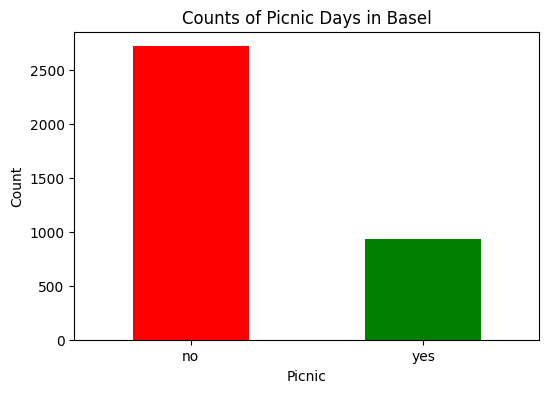

Counts of 'yes' and 'no' labels for BUDAPEST_picnic_weather:
BUDAPEST_picnic_weather
no     2311
yes    1343
Name: count, dtype: int64


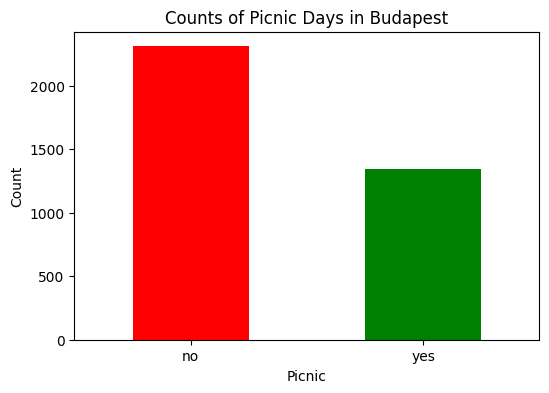

Counts of 'yes' and 'no' labels for DEBILT_picnic_weather:
DEBILT_picnic_weather
no     2851
yes     803
Name: count, dtype: int64


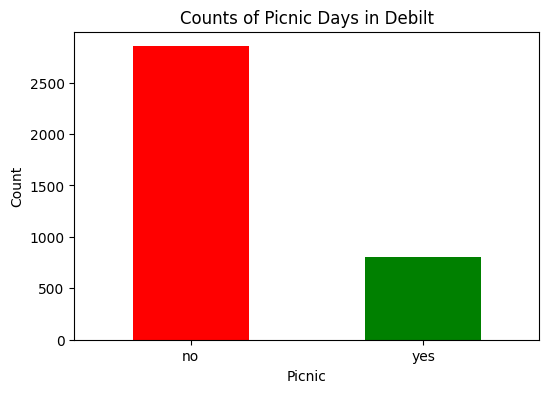

Counts of 'yes' and 'no' labels for DRESDEN_picnic_weather:
DRESDEN_picnic_weather
no     2821
yes     833
Name: count, dtype: int64


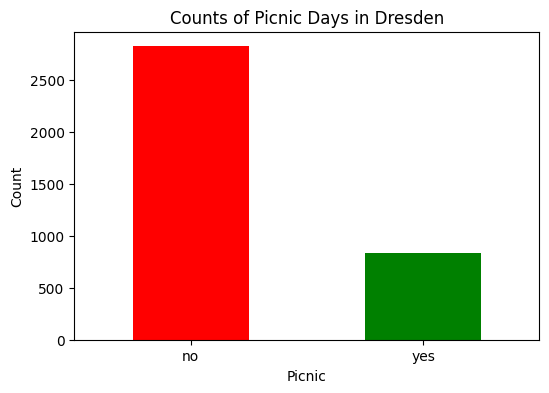

Counts of 'yes' and 'no' labels for DUSSELDORF_picnic_weather:
DUSSELDORF_picnic_weather
no     2817
yes     837
Name: count, dtype: int64


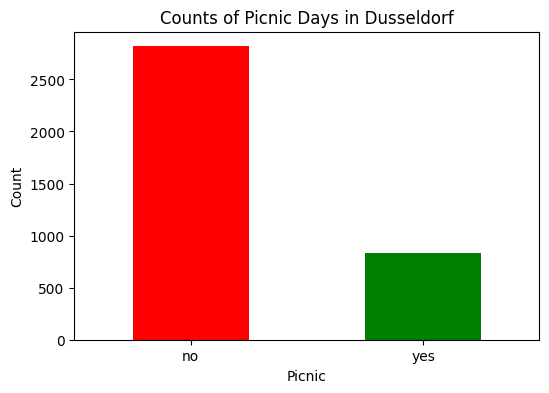

Counts of 'yes' and 'no' labels for HEATHROW_picnic_weather:
HEATHROW_picnic_weather
no     2785
yes     869
Name: count, dtype: int64


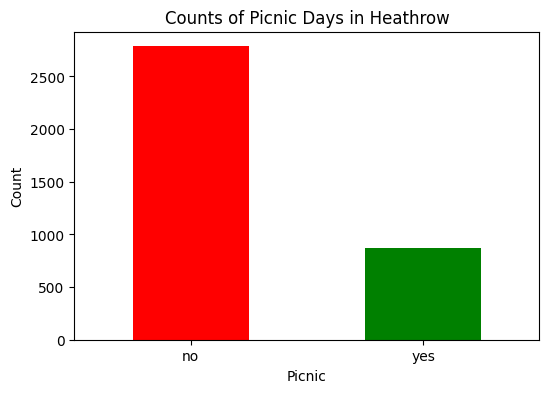

Counts of 'yes' and 'no' labels for KASSEL_picnic_weather:
KASSEL_picnic_weather
no     2920
yes     734
Name: count, dtype: int64


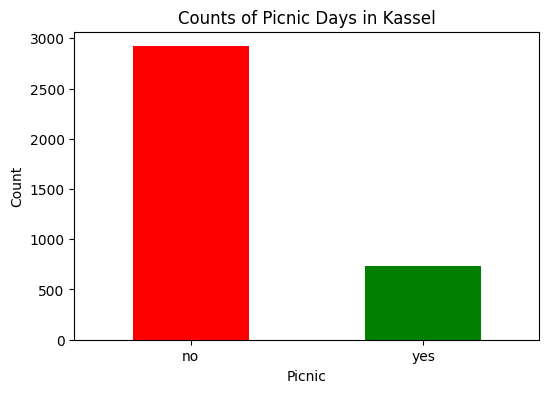

Counts of 'yes' and 'no' labels for LJUBLJANA_picnic_weather:
LJUBLJANA_picnic_weather
no     2552
yes    1102
Name: count, dtype: int64


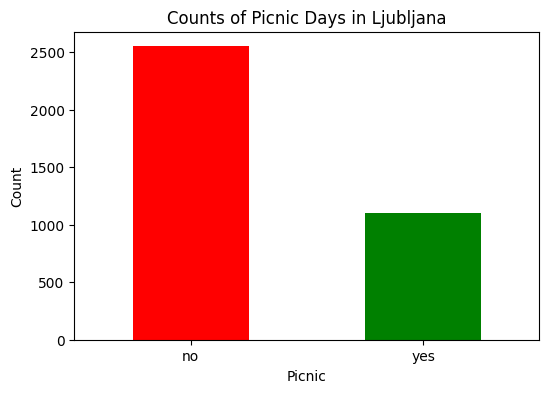

Counts of 'yes' and 'no' labels for MAASTRICHT_picnic_weather:
MAASTRICHT_picnic_weather
no     2826
yes     828
Name: count, dtype: int64


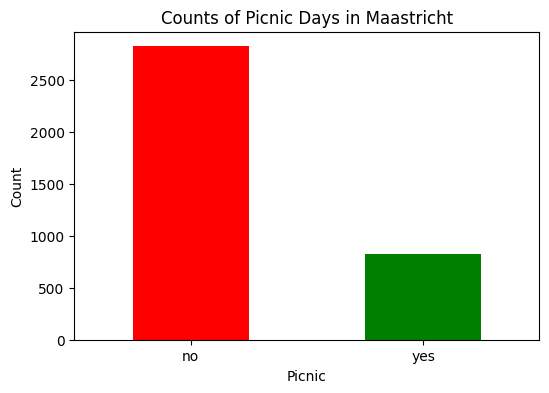

Counts of 'yes' and 'no' labels for MALMO_picnic_weather:
MALMO_picnic_weather
no     2884
yes     770
Name: count, dtype: int64


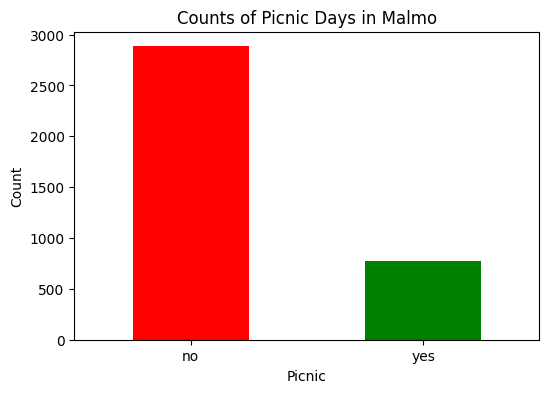

Counts of 'yes' and 'no' labels for MONTELIMAR_picnic_weather:
MONTELIMAR_picnic_weather
no     2252
yes    1402
Name: count, dtype: int64


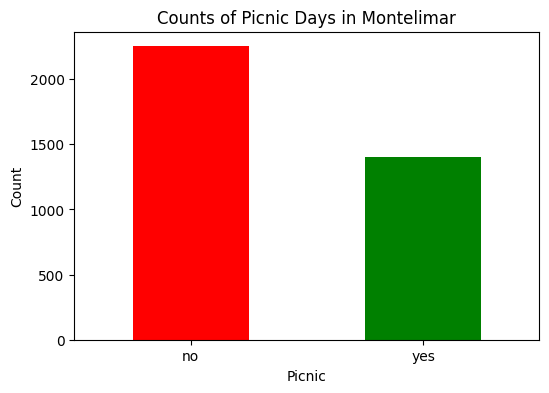

Counts of 'yes' and 'no' labels for MUENCHEN_picnic_weather:
MUENCHEN_picnic_weather
no     2815
yes     839
Name: count, dtype: int64


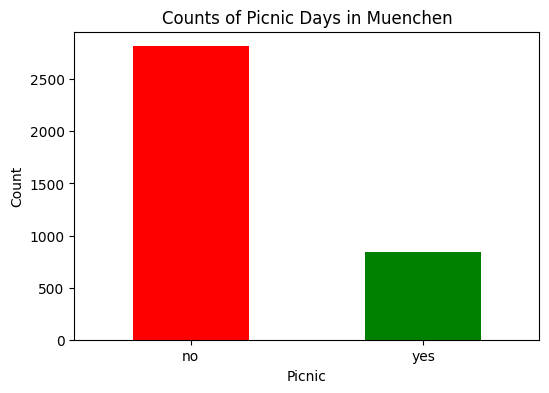

Counts of 'yes' and 'no' labels for OSLO_picnic_weather:
OSLO_picnic_weather
no     3037
yes     617
Name: count, dtype: int64


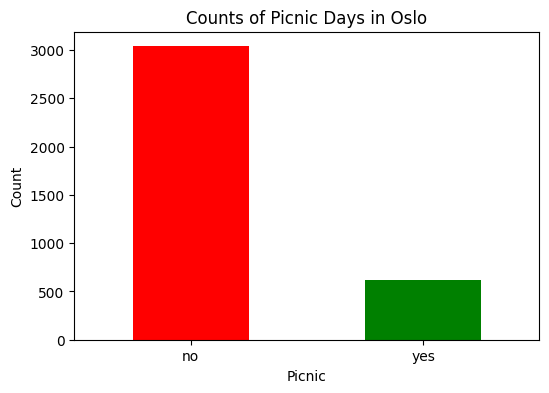

Counts of 'yes' and 'no' labels for PERPIGNAN_picnic_weather:
PERPIGNAN_picnic_weather
no     1883
yes    1771
Name: count, dtype: int64


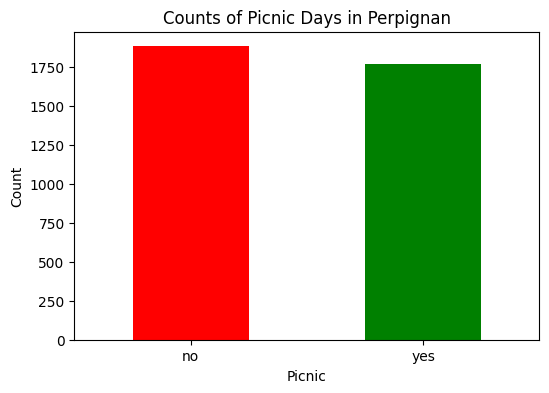

Counts of 'yes' and 'no' labels for SONNBLICK_picnic_weather:
SONNBLICK_picnic_weather
no    3654
Name: count, dtype: int64


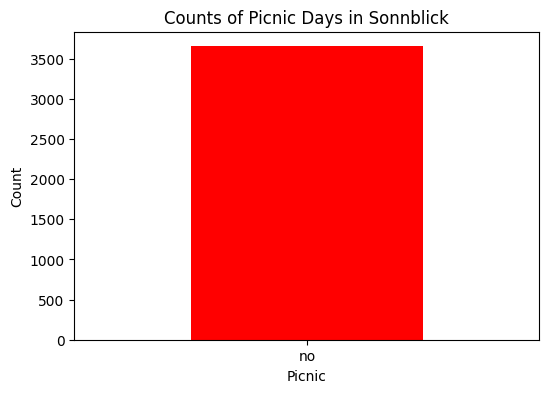

Counts of 'yes' and 'no' labels for STOCKHOLM_picnic_weather:
STOCKHOLM_picnic_weather
no     2980
yes     674
Name: count, dtype: int64


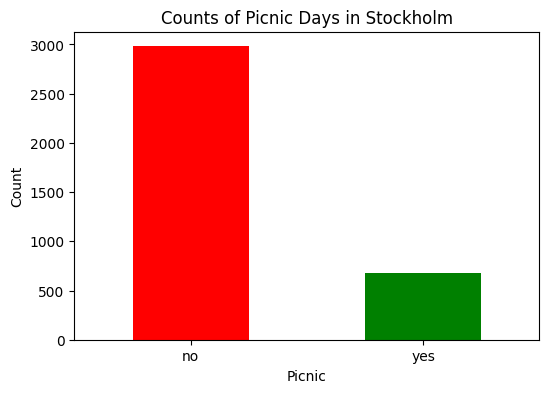

Counts of 'yes' and 'no' labels for TOURS_picnic_weather:
TOURS_picnic_weather
no     2677
yes     977
Name: count, dtype: int64


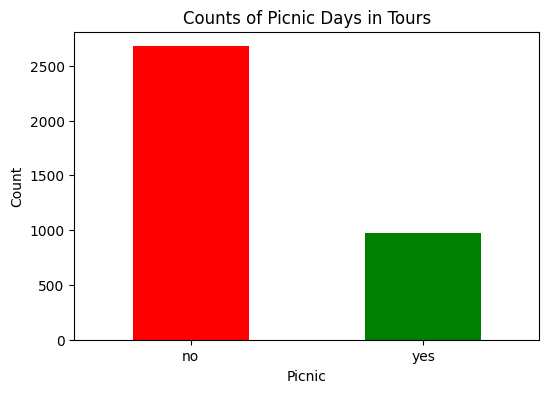

In [ ]:
# Create a bar chart for each city comparing 'yes picnic' with 'no picnic'
import matplotlib.pyplot as plt


picnic_columns = [col for col in df_labels.columns if col.endswith('_picnic_weather')]

for col in picnic_columns:

    picnic_counts = df_labels[col].value_counts()


    picnic_counts.index = picnic_counts.index.map({True: 'yes', False: 'no'})

    print(f"Counts of 'yes' and 'no' labels for {col}:")
    print(picnic_counts)


    colors = ['green' if label == 'yes' else 'red' for label in picnic_counts.index]
    plt.figure(figsize=(6, 4))
    picnic_counts.plot(kind='bar', color=colors)


    city_name = col.replace('_picnic_weather', '').replace('_', ' ').title()

    plt.title(f'Counts of Picnic Days in {city_name}')
    plt.xlabel('Picnic')
    plt.ylabel('Count')
    plt.xticks(rotation=0)
    plt.show()

# Missing Data

Dataset caricato con successo!


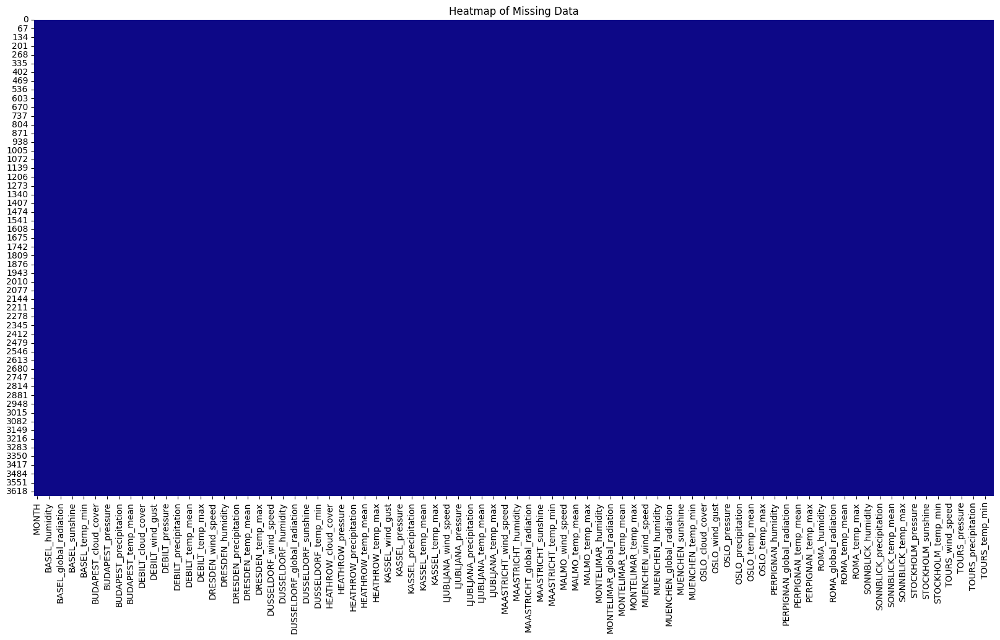

In [ ]:
# Create the heatmap of the missing data
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt


try:
    df = pd.read_csv('data/weather_prediction_dataset.csv')
    print("Dataset caricato con successo!")
except FileNotFoundError:
    print("Errore: File non trovato. Assicurati che il percorso del file sia corretto.")
except Exception as e:
    print(f"Si è verificato un errore durante il caricamento del dataset: {e}")


df_heatmap = df.drop(columns=['DATE'])


plt.figure(figsize=(20, 10))
sns.heatmap(df_heatmap.isnull(), cbar=False, cmap='plasma')
plt.title('Heatmap of Missing Data')
plt.show()

In [ ]:
# Check whether there are missing data or not, where the data are missing, and what their percentage is.
# If there are no missing data in the entire dataset, print 'there are no missing data'
import numpy as np

missing_columns = []
for col in df_labels.columns:
    if col in ['DATE']:
        continue
    pct_missing = np.mean(df_labels[col].isnull())
    print('{} - {}%'.format(col, round(pct_missing*100)))
    if pct_missing > 0:
      missing_columns.append(col)

if not missing_columns:
    print("\nThere are no missing data.")

BASEL_picnic_weather - 0%
BUDAPEST_picnic_weather - 0%
DEBILT_picnic_weather - 0%
DRESDEN_picnic_weather - 0%
DUSSELDORF_picnic_weather - 0%
HEATHROW_picnic_weather - 0%
KASSEL_picnic_weather - 0%
LJUBLJANA_picnic_weather - 0%
MAASTRICHT_picnic_weather - 0%
MALMO_picnic_weather - 0%
MONTELIMAR_picnic_weather - 0%
MUENCHEN_picnic_weather - 0%
OSLO_picnic_weather - 0%
PERPIGNAN_picnic_weather - 0%
SONNBLICK_picnic_weather - 0%
STOCKHOLM_picnic_weather - 0%
TOURS_picnic_weather - 0%

There are no missing data.


#Outliers

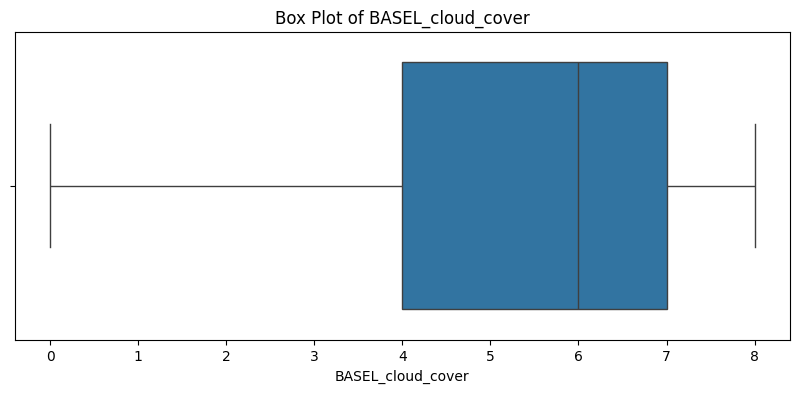

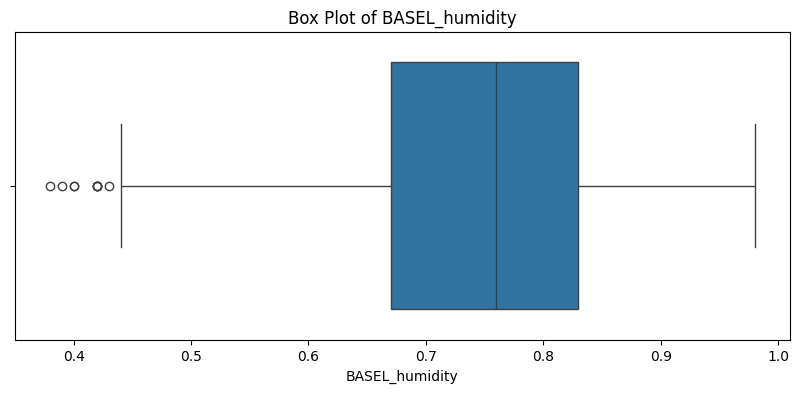

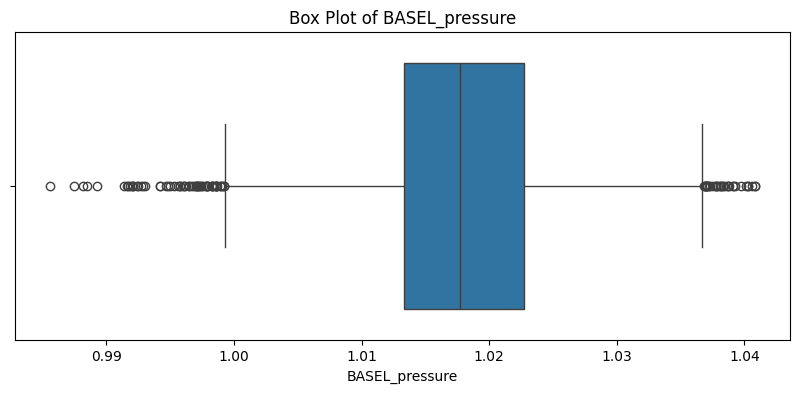

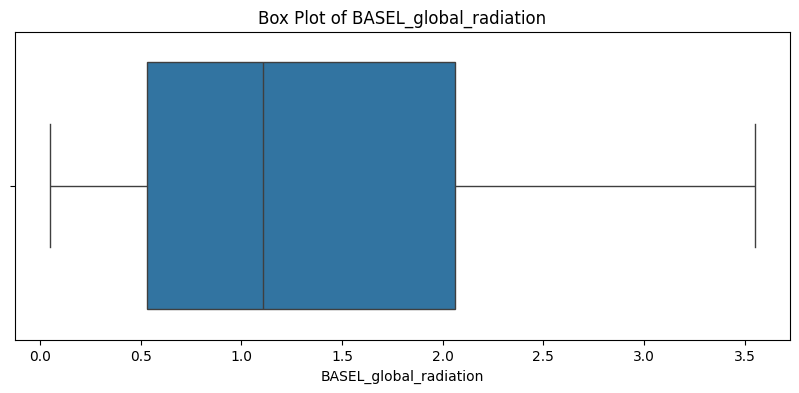

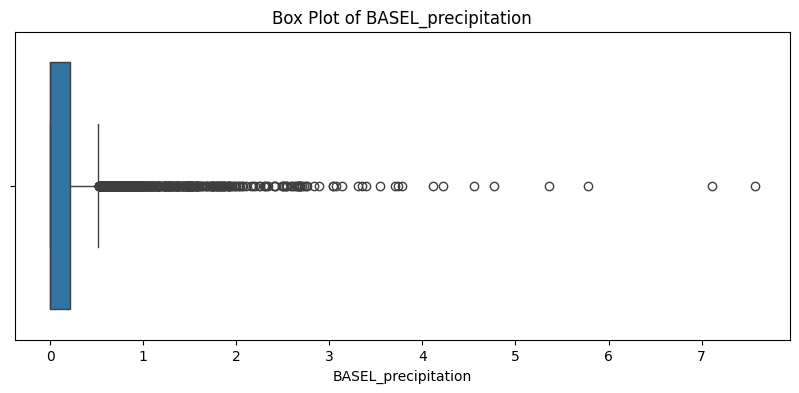

...

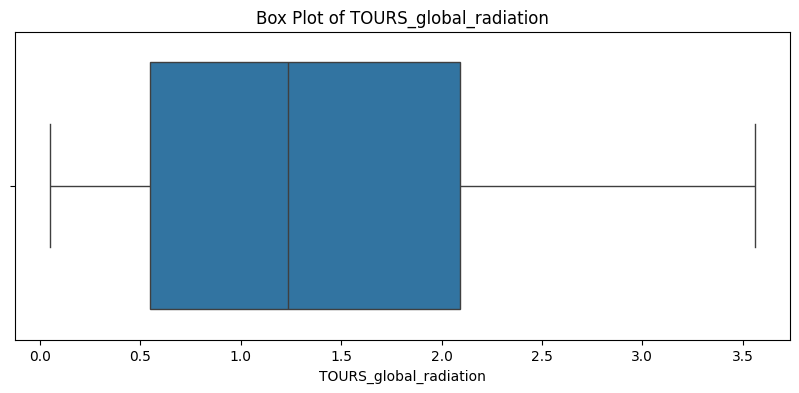

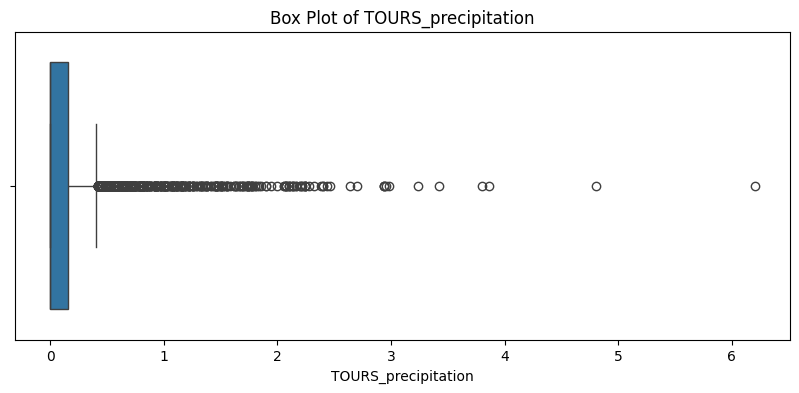

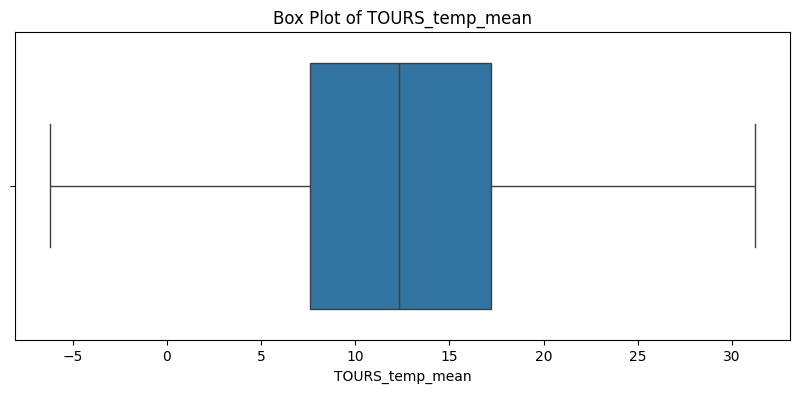

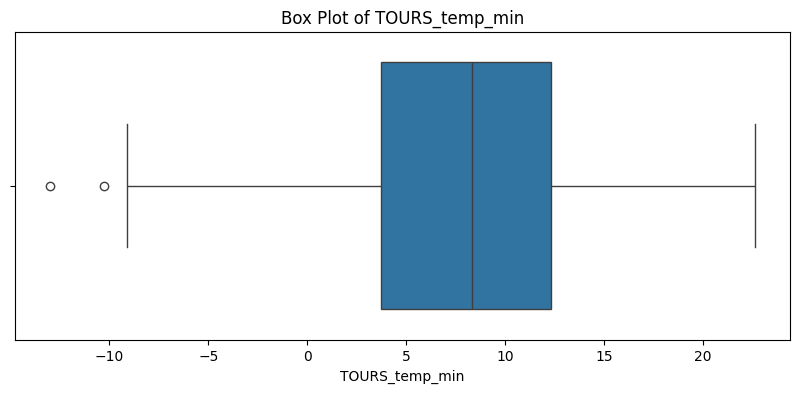

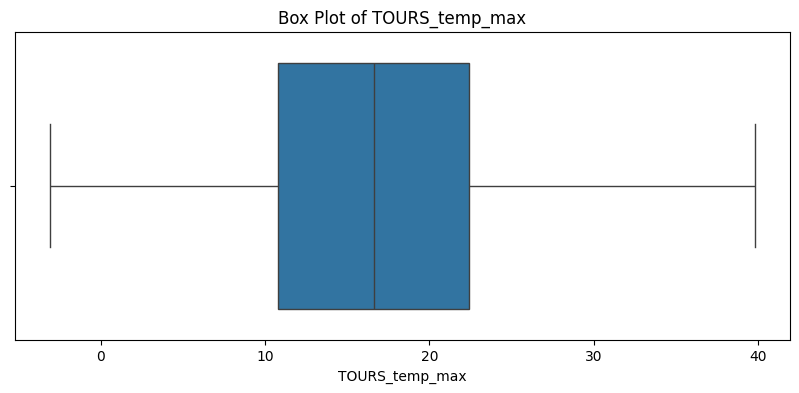

In [ ]:
# Create a box plot for each numerical column to identify outliers
import matplotlib.pyplot as plt
import seaborn as sns



numerical_cols = df.select_dtypes(include=['float64', 'int64']).columns.tolist()
numerical_cols.remove('DATE')
numerical_cols.remove('MONTH')



for col in numerical_cols:
    plt.figure(figsize=(10, 4))
    sns.boxplot(x=df[col])
    plt.title(f'Box Plot of {col}')
    plt.xlabel(col)
    plt.show()

In [ ]:
# Filter for rows where 'STOCKHOLM_cloud_cover' is negative
negative_cloud_cover_stockholm = df[df['STOCKHOLM_cloud_cover'] < 0]


if not negative_cloud_cover_stockholm.empty:
    print("Righe con valori negativi nella colonna 'STOCKHOLM_cloud_cover' (Stockholm):")
    display(negative_cloud_cover_stockholm[['DATE', 'STOCKHOLM_cloud_cover']])
else:
    print("Non ci sono valori negativi nella colonna 'STOCKHOLM_cloud_cover' (Stockholm).")

Righe con valori negativi nella colonna 'STOCKHOLM_cloud_cover' (Stockholm):


,DATE,STOCKHOLM_cloud_cover
3127,20080724,-99
3463,20090625,-99


In [ ]:
# Calculate the most frequent value counts for 'STOCKHOLM_cloud_cover'
stockholm_cloud_cover_counts = df['STOCKHOLM_cloud_cover'].value_counts()


most_frequent_value = stockholm_cloud_cover_counts.index[0]
frequency = stockholm_cloud_cover_counts.iloc[0]

print(f"Il valore più frequente nella colonna 'STOCKHOLM_cloud_cover' è: {most_frequent_value}")
print(f"La sua frequenza è: {frequency}")

Il valore più frequente nella colonna 'STOCKHOLM_cloud_cover' è: 8
La sua frequenza è: 856


In [ ]:
# Replacement of outliers with the most frequent value and verification of the correct replacement
df['STOCKHOLM_cloud_cover'] = df['STOCKHOLM_cloud_cover'].replace(-99, 8)


negative_cloud_cover_stockholm_after_replace = df[df['STOCKHOLM_cloud_cover'] < 0]

if not negative_cloud_cover_stockholm_after_replace.empty:
    print("Ancora valori negativi nella colonna 'STOCKHOLM_cloud_cover' dopo la sostituzione:")
    display(negative_cloud_cover_stockholm_after_replace[['DATE', 'STOCKHOLM_cloud_cover']])
else:
    print("Valori -99 nella colonna 'STOCKHOLM_cloud_cover' sostituiti con successo con 8.")

Valori -99 nella colonna 'STOCKHOLM_cloud_cover' sostituiti con successo con 8.


In [ ]:
# Filter for rows where 'STOCKHOLM_pressure' is negative
negative_pressure_stockholm = df[df['STOCKHOLM_pressure'] < 0]


if not negative_pressure_stockholm.empty:
    print("Righe con valori negativi nella colonna 'STOCKHOLM_pressure' (Stockholm):")
    display(negative_pressure_stockholm[['DATE', 'STOCKHOLM_pressure']])
else:
    print("Non ci sono valori negativi nella colonna 'STOCKHOLM_pressurer' (Stockholm).")

Righe con valori negativi nella colonna 'STOCKHOLM_pressure' (Stockholm):


,DATE,STOCKHOLM_pressure
23,20000124,-0.099
2710,20070603,-0.099
2837,20071008,-0.099


In [ ]:
# Replacement of outliers with the mean value and verification of the correct replacement
mean_stockholm_pressure = df['STOCKHOLM_pressure'].mean()

print(f"Il valore medio della colonna 'STOCKHOLM_pressure' è: {mean_stockholm_pressure}")


df['STOCKHOLM_pressure'] = df['STOCKHOLM_pressure'].replace(-0.099, mean_stockholm_pressure)


negative_pressure_stockholm_after_replace = df[df['STOCKHOLM_pressure'] < 0]

if not negative_pressure_stockholm_after_replace.empty:
    print("Ancora valori negativi nella colonna 'STOCKHOLM_pressure' dopo la sostituzione:")
    display(negative_pressure_stockholm_after_replace[['DATE', 'STOCKHOLM_pressure']])
else:
    print("Valori -0.099 nella colonna 'STOCKHOLM_pressure' sostituiti con successo con il valore medio.")

Il valore medio della colonna 'STOCKHOLM_pressure' è: 1.011073754789272
Valori -0.099 nella colonna 'STOCKHOLM_pressure' sostituiti con successo con il valore medio.


In [ ]:
# Filter for rows where 'TOURS_pressure' is less than 0.200
low_pressure_tours = df[df['TOURS_pressure'] < 0.200]


if not low_pressure_tours.empty:
    print("Righe con valori minori di 0.200 nella colonna 'TOURS_pressure' (Tours):")
    display(low_pressure_tours[['DATE', 'TOURS_pressure']])
else:
    print("Non ci sono valori minori di 0.200 nella colonna 'TOURS_pressure' (Tours).")

Righe con valori minori di 0.200 nella colonna 'TOURS_pressure' (Tours):


,DATE,TOURS_pressure
3286,20081230,0.0003


In [ ]:
# replacement of outliers with the most frequent value and verification of the correct replacement
mean_tours_pressure = df['TOURS_pressure'].mean()

print(f"Il valore medio della colonna 'TOURS_pressure' è: {mean_tours_pressure}")


df['TOURS_pressure'] = df['TOURS_pressure'].replace(0.0003, mean_tours_pressure)


low_pressure_tours_after_replace = df[df['TOURS_pressure'] == 0.0003]

if not low_pressure_tours_after_replace.empty:
    print("Ancora valori 0.0003 nella colonna 'TOURS_pressure' dopo la sostituzione:")
    display(low_pressure_tours_after_replace[['DATE', 'TOURS_pressure']])
else:
    print("Valore 0.0003 nella colonna 'TOURS_pressure' sostituito con successo con il valore medio.")

Il valore medio della colonna 'TOURS_pressure' è: 1.0166392446633825
Valore 0.0003 nella colonna 'TOURS_pressure' sostituito con successo con il valore medio.


# Pearson correlation

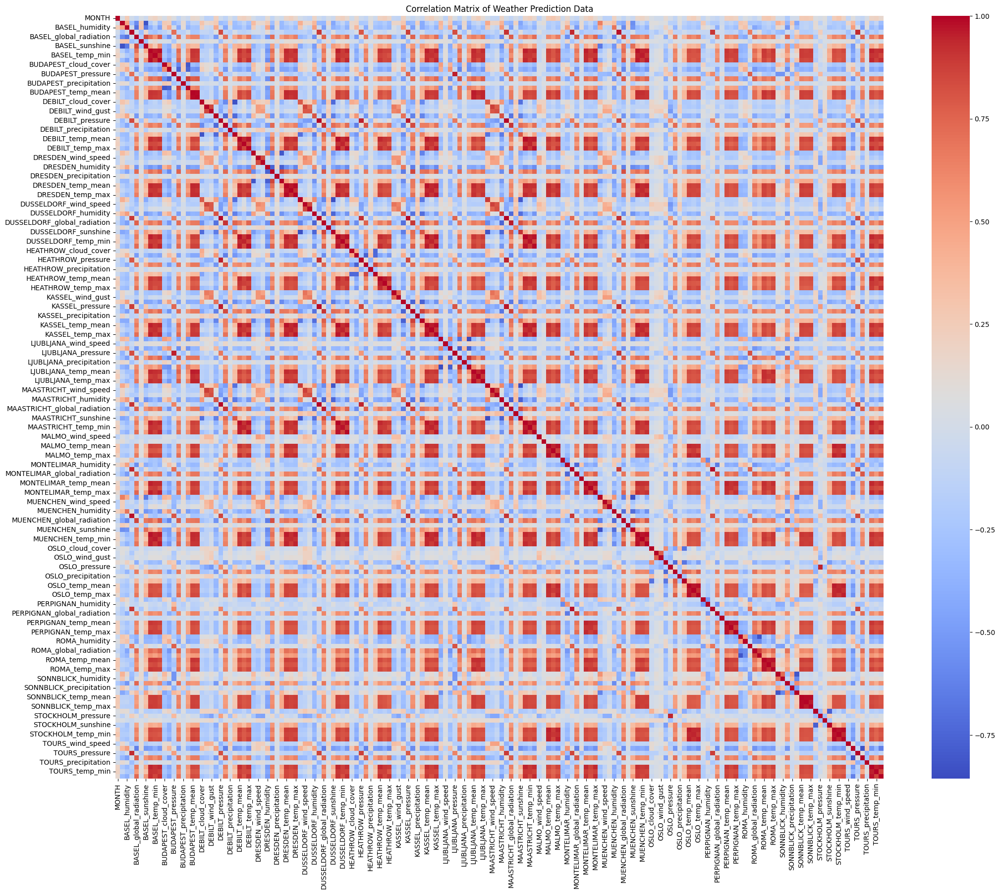

In [ ]:
# Create a heatmap of the correlation matrix with Pearson correlation
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

# Select numeric columns, drop DATE if present
numerical_df = df.select_dtypes(include=['float64', 'int64']).drop(columns=['DATE'], errors='ignore')

# Compute Pearson correlation matrix
correlation_matrix = numerical_df.corr(method='pearson')

# Plot heatmap
plt.figure(figsize=(25, 20))
sns.heatmap(
    correlation_matrix,
    annot=False,
    cmap='coolwarm',
    fmt='.2f'
)
plt.title('Correlation Matrix of Weather Prediction Data')  # chart title
plt.show()


In [ ]:
# Calculate correlation for each picnic weather column with other numerical features
# Select target columns ending with '_picnic_weather'
picnic_target_cols = [col for col in df.columns if col.endswith('_picnic_weather')]

# Select numerical features excluding DATE and targets
numerical_cols = df.select_dtypes(include=['float64', 'int64']).columns.tolist()
numerical_features = [col for col in numerical_cols if col not in ['DATE'] and col not in picnic_target_cols]

# Compute correlations between each target and numerical features
correlations = {}
for target_col in picnic_target_cols:
    subset_df = df[[target_col] + numerical_features]
    correlation_matrix_subset = subset_df.corr(method='pearson')
    correlations[target_col] = correlation_matrix_subset[target_col].drop(target_col)


In [ ]:
# Extract and sort variable pairs with absolute correlation > 0.8 from the upper triangle of the correlation matrix
import numpy as np

# Mask upper triangle to avoid duplicate pairs
mask = np.triu(np.ones_like(correlation_matrix, dtype=bool))

# Keep lower triangle values
upper_triangle = correlation_matrix.mask(mask).stack()

# Threshold for high correlation
correlation_threshold = 0.8

# Filter and sort pairs above threshold
highly_correlated_pairs = upper_triangle[abs(upper_triangle) > correlation_threshold]
highly_correlated_pairs = highly_correlated_pairs.sort_values(key=abs, ascending=False)


print(f"Highly correlated feature pairs (|corr| > {correlation_threshold}):")
display(highly_correlated_pairs)


Highly correlated feature pairs (|corr| > 0.8):


,,0
MAASTRICHT_pressure,DUSSELDORF_pressure,0.995518
MAASTRICHT_temp_mean,DUSSELDORF_temp_mean,0.994148
MAASTRICHT_temp_max,DUSSELDORF_temp_max,0.990203
BUDAPEST_temp_max,BUDAPEST_temp_mean,0.989866
DUSSELDORF_pressure,DEBILT_pressure,0.989141
...,...,...
STOCKHOLM_temp_max,ROMA_temp_min,0.800996
OSLO_temp_max,MONTELIMAR_temp_min,0.800861
ROMA_temp_mean,DUSSELDORF_temp_min,0.800786
MUENCHEN_global_radiation,KASSEL_global_radiation,0.800493


In [ ]:
# Select a subset of features by analyzing the mean absolute correlation of each feature with the target
# then reduce redundancy by discarding, from pairs of highly correlated variables, the one with the lower correlation to the target.
import numpy as np
import pandas as pd

# Build a dict mapping each feature to its list of absolute correlations with picnic targets
feature_target_correlations = {}
for target_col, corr_series in correlations.items():
    for feature, corr_value in corr_series.items():
        if feature not in feature_target_correlations:
            feature_target_correlations[feature] = []
        feature_target_correlations[feature].append(abs(corr_value))

# Compute average absolute correlation for each feature across all targets
average_target_correlations = {
    feature: np.mean(corr_values)
    for feature, corr_values in feature_target_correlations.items()
}
# Convert to Series and sort descending to rank features by importance
sorted_avg_correlations = pd.Series(average_target_correlations).sort_values(ascending=False)

print("Average absolute correlations with picnic weather across cities:")
display(sorted_avg_correlations.head(20))

# Initialize lists for final feature selection, tracking exclusions due to multicollinearity
selected_features = []
excluded_features = set()

# Pick features by descending avg_corr, exclude their highly correlated peers
for feature, avg_corr in sorted_avg_correlations.items():
    if feature not in excluded_features:
        selected_features.append(feature)
        highly_correlated_with_current = highly_correlated_pairs.index[
            (highly_correlated_pairs.index.get_level_values(0) == feature) |
            (highly_correlated_pairs.index.get_level_values(1) == feature)
        ].tolist()

        for f1, f2 in highly_correlated_with_current:
            excluded_features.add(f2 if f1 == feature else f1)

# Resolve any remaining mutual selections in highly correlated pairs
for (feature1, feature2), corr_value in highly_correlated_pairs.items():
    if feature1 in selected_features and feature2 in selected_features:

        if average_target_correlations.get(feature1, 0) >= average_target_correlations.get(feature2, 0):
            selected_features.remove(feature2)
        else:
            selected_features.remove(feature1)
    elif feature1 not in selected_features and feature2 not in selected_features:

        if average_target_correlations.get(feature1, 0) >= average_target_correlations.get(feature2, 0):
            if feature1 not in excluded_features:
                selected_features.append(feature1)
            if feature2 in selected_features:
                selected_features.remove(feature2)
        else:
            if feature2 not in excluded_features:
                selected_features.append(feature2)
            if feature1 in selected_features:
                selected_features.remove(feature1)

print("\nSelected features based on correlation analysis:")
print(selected_features)
print(f"\nNumber of selected features: {len(selected_features)}")


Average absolute correlations with picnic weather across cities:


,0



Selected features based on correlation analysis:
['TOURS_temp_max', 'TOURS_temp_mean', 'STOCKHOLM_pressure', 'TOURS_pressure', 'LJUBLJANA_sunshine', 'MAASTRICHT_humidity', 'MAASTRICHT_sunshine', 'BUDAPEST_sunshine', 'MAASTRICHT_wind_speed', 'MUENCHEN_sunshine', 'ROMA_sunshine', 'KASSEL_sunshine', 'DRESDEN_sunshine', 'DEBILT_sunshine', 'PERPIGNAN_global_radiation', 'TOURS_temp_min', 'MUENCHEN_global_radiation', 'HEATHROW_sunshine', 'BASEL_sunshine', 'DRESDEN_wind_gust', 'MAASTRICHT_wind_gust', 'MUENCHEN_wind_gust', 'PERPIGNAN_pressure', 'LJUBLJANA_pressure', 'OSLO_temp_mean', 'STOCKHOLM_temp_max', 'TOURS_global_radiation', 'PERPIGNAN_temp_min', 'OSLO_temp_max', 'STOCKHOLM_temp_mean', 'ROMA_temp_max', 'SONNBLICK_sunshine', 'KASSEL_temp_min', 'PERPIGNAN_temp_mean', 'MALMO_temp_min', 'HEATHROW_global_radiation', 'DUSSELDORF_humidity', 'HEATHROW_temp_max', 'STOCKHOLM_temp_min', 'LJUBLJANA_temp_mean', 'PERPIGNAN_temp_max', 'SONNBLICK_temp_max', 'OSLO_temp_min', 'MUENCHEN_pressure', 'MONTELI

Correlation matrix for selected features:


,TOURS_temp_max,TOURS_temp_mean,STOCKHOLM_pressure,TOURS_pressure,LJUBLJANA_sunshine,MAASTRICHT_humidity,MAASTRICHT_sunshine,BUDAPEST_sunshine,MAASTRICHT_wind_speed,MUENCHEN_sunshine,...,HEATHROW_temp_max,STOCKHOLM_temp_min,LJUBLJANA_temp_mean,PERPIGNAN_temp_max,SONNBLICK_temp_max,OSLO_temp_min,MUENCHEN_pressure,MONTELIMAR_global_radiation,ROMA_temp_mean,SONNBLICK_temp_min
TOURS_temp_max,1.000000,0.974055,0.038424,-0.088189,0.552604,-0.484064,0.475195,0.562265,-0.221044,0.524792,...,0.907323,0.793480,0.863309,0.878551,0.816226,0.794616,-0.090388,0.710714,0.842123,0.797975
TOURS_temp_mean,0.974055,1.000000,0.012109,-0.142085,0.530273,-0.423966,0.400757,0.552743,-0.170110,0.487288,...,0.890552,0.803781,0.884231,0.893238,0.851738,0.804034,-0.152621,0.660859,0.858586,0.839188
STOCKHOLM_pressure,0.038424,0.012109,1.000000,0.170763,0.041826,-0.178078,0.272816,0.056258,-0.436294,0.123630,...,0.081957,-0.024729,-0.027132,-0.039272,-0.050105,-0.003525,0.345312,0.051567,-0.013203,-0.003281
TOURS_pressure,-0.088189,-0.142085,0.170763,1.000000,0.083884,0.086638,0.040600,-0.017824,-0.143107,-0.078822,...,0.038133,-0.047097,-0.178371,-0.062213,-0.139611,-0.057625,0.849415,0.116275,-0.150990,-0.165828
LJUBLJANA_sunshine,0.552604,0.530273,0.041826,0.083884,1.000000,-0.392079,0.339087,0.651788,-0.177511,0.589267,...,0.524524,0.442446,0.572778,0.491324,0.478195,0.443918,0.102294,0.525166,0.469416,0.430424
MAASTRICHT_humidity,-0.484064,-0.423966,-0.178078,0.086638,-0.392079,1.000000,-0.767573,-0.401185,0.070259,-0.538656,...,-0.459882,-0.312699,-0.381745,-0.353181,-0.329834,-0.328025,-0.032135,-0.447522,-0.333335,-0.306982
MAASTRICHT_sunshine,0.475195,0.400757,0.272816,0.040600,0.339087,-0.767573,1.000000,0.358617,-0.300440,0.472254,...,0.475887,0.327821,0.357875,0.350257,0.313983,0.330970,0.153953,0.431148,0.354931,0.296387
BUDAPEST_sunshine,0.562265,0.552743,0.056258,-0.017824,0.651788,-0.401185,0.358617,1.000000,-0.176035,0.549940,...,0.534315,0.476676,0.591200,0.506118,0.547726,0.489582,0.002203,0.503437,0.540569,0.509181
MAASTRICHT_wind_speed,-0.221044,-0.170110,-0.436294,-0.143107,-0.177511,0.070259,-0.300440,-0.176035,1.000000,-0.170821,...,-0.252013,-0.192017,-0.191479,-0.170988,-0.141932,-0.189416,-0.142491,-0.250899,-0.233881,-0.153285
MUENCHEN_sunshine,0.524792,0.487288,0.123630,-0.078822,0.589267,-0.538656,0.472254,0.549940,-0.170821,1.000000,...,0.472701,0.385965,0.432311,0.389621,0.442048,0.384031,0.067890,0.405335,0.398672,0.393560


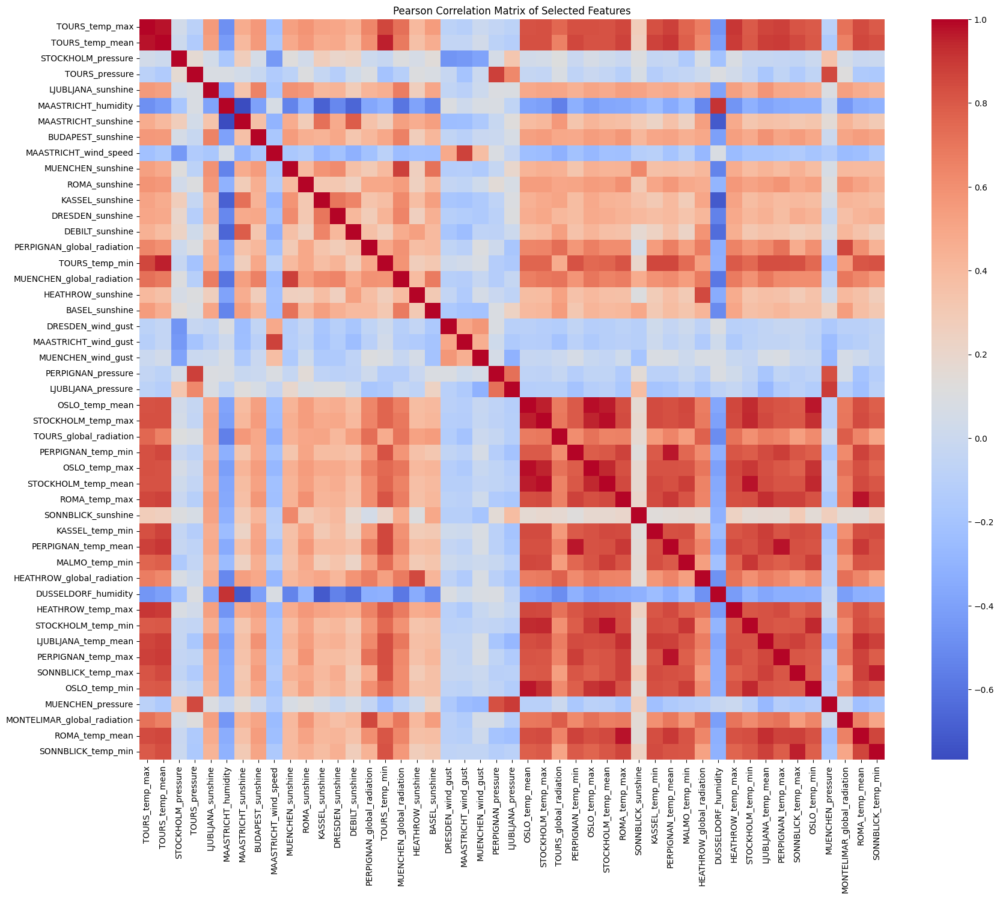

In [ ]:
# Calculate the Pearson correlation matrix for the selected features
import matplotlib.pyplot as plt
import seaborn as sns

selected_df = df[selected_features]

subset_correlation_matrix = selected_df.corr(method='pearson')


print("Correlation matrix for selected features:")
display(subset_correlation_matrix)

plt.figure(figsize=(20, 16))
sns.heatmap(subset_correlation_matrix, annot=False, cmap='coolwarm', fmt=".2f")
plt.title('Pearson Correlation Matrix of Selected Features')
plt.show()

In [ ]:
# Create a new DataFrame with only the selected features
df_selected = df[selected_features].copy()

# Display the first few rows of the new DataFrame to verify
print("Nuovo DataFrame con le feature selezionate:")
display(df_selected.head())

print(f"\nIl nuovo dataset ha {df_selected.shape[1]} features e {df_selected.shape[0]} righe.")

# Define the filename for the new dataset
output_filename = 'data/weather_prediction_selected_features.csv'

# Save the DataFrame with selected features to a new CSV file
try:
    df_selected.to_csv(output_filename, index=False)
    print(f"Dataset con feature selezionate salvato con successo come '{output_filename}'")
except Exception as e:
    print(f"Si è verificato un errore durante il salvataggio del dataset: {e}")

Nuovo DataFrame con le feature selezionate:


,TOURS_temp_max,TOURS_temp_mean,STOCKHOLM_pressure,TOURS_pressure,LJUBLJANA_sunshine,MAASTRICHT_humidity,MAASTRICHT_sunshine,BUDAPEST_sunshine,MAASTRICHT_wind_speed,MUENCHEN_sunshine,...,HEATHROW_temp_max,STOCKHOLM_temp_min,LJUBLJANA_temp_mean,PERPIGNAN_temp_max,SONNBLICK_temp_max,OSLO_temp_min,MUENCHEN_pressure,MONTELIMAR_global_radiation,ROMA_temp_mean,SONNBLICK_temp_min
0,9.8,8.5,1.0163,1.0275,5.2,0.98,0.0,3.7,3.1,0.0,...,10.8,-9.3,-4.8,14.0,-13.4,-8.6,1.0273,0.30,1.6,-17.0
1,9.2,7.9,1.0108,1.0293,5.0,0.95,0.0,0.4,3.8,6.1,...,11.5,0.5,-0.9,14.6,-12.3,-6.7,1.0321,0.54,4.2,-15.0
2,9.6,8.1,1.0071,1.0267,2.4,0.87,0.9,0.0,7.4,0.4,...,9.5,-1.0,-0.3,13.2,-5.8,-1.1,1.0317,0.53,3.8,-12.5
3,10.8,8.6,0.9947,1.0222,3.5,0.92,0.0,0.0,7.2,4.5,...,11.0,2.5,-3.6,12.8,-4.2,-0.5,1.0260,0.64,6.0,-7.0
4,9.5,8.0,1.0072,1.0209,4.6,0.87,6.2,0.8,4.1,0.2,...,10.8,-1.8,-3.0,14.9,-5.8,-4.0,1.0248,0.70,5.0,-9.4



Il nuovo dataset ha 47 features e 3654 righe.
Dataset con feature selezionate salvato con successo come 'weather_prediction_selected_features.csv'


# PCA


In [ ]:
# Standardize all numerical features
from sklearn.preprocessing import StandardScaler

# Select numerical features excluding 'DATE'
numerical_features = df.select_dtypes(include=['float64', 'int64']).drop(columns=['DATE'], errors='ignore')

# Instantiate StandardScaler
scaler = StandardScaler()

# Fit and transform the numerical features
scaled_features = scaler.fit_transform(numerical_features)

# Display the first few rows of the scaled features (as a numpy array)
print("Scaled features (first 5 rows):")
display(scaled_features[:5])

Scaled features (first 5 rows):


array([[-1.60041224e+00,  1.11026048e+00,  1.34443286e+00,
         1.34700635e+00, -1.20867838e+00, -3.82043510e-01,
        -1.07660751e+00, -1.09564105e+00, -8.10098373e-01,
        -1.33447356e+00, -7.92305039e-01,  1.76154035e+00,
         1.26577618e+00, -9.66902077e-01, -3.33700557e-01,
        -4.58839935e-01, -1.95291698e+00, -1.73635200e+00,
         7.44490334e-01, -6.29678528e-01, -5.54539895e-01,
         1.56096530e+00,  8.82559211e-01, -1.24220674e+00,
        -2.97951454e-01, -1.18756882e+00, -7.43713732e-01,
        -5.13777049e-01, -9.29103069e-01,  1.18250218e+00,
        -5.95516413e-01, -9.23960755e-01,  9.89236376e-01,
        -1.25324437e+00,  3.13532316e-01, -1.08803738e+00,
        -1.12057435e+00, -1.11400936e+00, -1.29142153e+00,
         1.35118925e+00, -8.52065509e-01, -1.20802396e+00,
         1.47208710e+00,  8.60113701e-01, -1.16669864e+00,
         4.45205523e-03, -1.02737623e+00, -1.03790872e+00,
        -7.09897902e-01, -1.08152815e+00,  8.59015118e-0

In [ ]:
#Apply Principal Component Analysis (PCA)
from sklearn.decomposition import PCA
import pandas as pd

# Instantiate PCA, keeping all components initially
pca = PCA(n_components=None)

# Fit PCA on the scaled features
pca.fit(scaled_features)

# Transform the scaled features to obtain the principal components
principal_components = pca.transform(scaled_features)

# Create a list of column names for the principal components
pca_column_names = [f'principal component {i+1}' for i in range(principal_components.shape[1])]

# Create a new DataFrame from the principal components array
pca_df = pd.DataFrame(principal_components, columns=pca_column_names)

# Display the shape of the principal components array
print("Shape of principal components array:", principal_components.shape)

# Display the head of the new DataFrame
print("\nHead of the PCA DataFrame with labels:")
display(pca_df.head())

Shape of principal components array: (3654, 164)

Head of the PCA DataFrame with labels:


,principal component 1,principal component 2,principal component 3,principal component 4,principal component 5,principal component 6,principal component 7,principal component 8,principal component 9,principal component 10,...,principal component 155,principal component 156,principal component 157,principal component 158,principal component 159,principal component 160,principal component 161,principal component 162,principal component 163,principal component 164
0,-10.862496,2.182780,-0.812095,5.271411,0.472973,-1.207269,0.012907,0.926024,-1.909604,0.610384,...,0.123609,0.028420,-0.000498,0.103824,-0.001002,-0.059096,0.013261,0.004892,0.001610,0.000255
1,-9.770506,2.978664,0.463637,5.373012,0.202412,0.265952,0.044650,-0.884701,-0.576198,0.832287,...,-0.044604,-0.084204,0.047780,-0.042953,-0.002394,-0.038532,0.011508,-0.006341,-0.000375,0.002039
2,-9.368043,0.723917,4.688040,4.978113,1.036044,2.020357,-0.661766,-1.975452,-0.430434,0.396921,...,0.037928,-0.056209,-0.000743,-0.063763,-0.003405,0.009480,-0.015036,-0.007158,-0.000864,0.000843
3,-8.495714,-1.320702,5.583118,3.671332,-0.036684,-0.279892,-2.776515,-1.753303,1.969434,-3.743612,...,-0.048446,-0.004798,0.104121,-0.005314,0.010062,-0.049621,-0.010196,0.005000,0.001314,-0.001043
4,-8.213420,2.585179,2.228551,0.936048,1.431843,2.375013,-0.355721,0.782222,-0.443488,-0.240979,...,-0.123700,-0.010389,0.073819,0.015508,0.003905,-0.001610,0.016765,-0.007626,0.004621,0.005730


In [ ]:
# Select numerical features excluding 'DATE'
numerical_features_cov = df.select_dtypes(include=['float64', 'int64']).drop(columns=['DATE'], errors='ignore')

# Calculate the covariance matrix
covariance_matrix = numerical_features_cov.cov()

# Display the covariance matrix
print("Covariance Matrix of Weather Data:")
display(covariance_matrix)

Covariance Matrix of Weather Data:


,MONTH,BASEL_cloud_cover,BASEL_humidity,BASEL_pressure,BASEL_global_radiation,BASEL_precipitation,BASEL_sunshine,BASEL_temp_mean,BASEL_temp_min,BASEL_temp_max,...,STOCKHOLM_temp_min,STOCKHOLM_temp_max,TOURS_wind_speed,TOURS_humidity,TOURS_pressure,TOURS_global_radiation,TOURS_precipitation,TOURS_temp_mean,TOURS_temp_min,TOURS_temp_max
MONTH,11.903071,0.136791,0.096393,-0.000488,-0.311737,0.058697,-0.665330,3.984100,4.723837,3.472243,...,7.247490,5.821703,-0.531104,0.033205,-0.001317,-0.287956,0.027487,4.044883,4.074295,4.016552
BASEL_cloud_cover,0.136791,5.407938,0.122908,-0.005236,-1.258552,0.359550,-8.287726,-3.229005,-0.384667,-6.076961,...,-3.128591,-4.395210,0.631474,0.100426,-0.003437,-0.724384,0.129360,-3.364186,-1.254191,-5.473274
BASEL_humidity,0.096393,0.122908,0.011618,-0.000020,-0.069300,0.017790,-0.305798,-0.300847,-0.146627,-0.434431,...,-0.145106,-0.257076,-0.005660,0.006424,-0.000004,-0.047102,0.002532,-0.227705,-0.136231,-0.319135
BASEL_pressure,-0.000488,-0.005236,-0.000020,0.000063,-0.000078,-0.001295,0.005525,-0.013009,-0.013944,-0.012797,...,-0.005555,-0.007465,-0.003333,-0.000040,0.000064,0.000012,-0.001002,-0.008303,-0.010333,-0.006281
BASEL_global_radiation,-0.311737,-1.258552,-0.069300,-0.000078,0.874876,-0.094505,3.446322,4.912932,3.452145,6.386435,...,3.940036,5.618971,-0.304401,-0.067910,-0.000004,0.669144,-0.037796,4.065890,2.831411,5.300084
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
TOURS_global_radiation,-0.287956,-0.724384,-0.047102,0.000012,0.669144,-0.026441,2.206980,4.501325,3.527516,5.485317,...,4.022700,5.742052,-0.281106,-0.088106,0.000673,0.858351,-0.100784,3.945180,2.479981,5.408638
TOURS_precipitation,0.027487,0.129360,0.002532,-0.001002,-0.037796,0.031794,-0.217589,0.090847,0.139195,0.062082,...,-0.081139,-0.160741,0.165836,0.015168,-0.001380,-0.100784,0.178212,0.015857,0.215919,-0.183309
TOURS_temp_mean,4.044883,-3.364186,-0.227705,-0.008303,4.065890,0.186377,12.971416,45.492958,39.140517,52.866458,...,37.690668,47.943116,-1.125882,-0.390990,-0.007893,3.945180,0.015857,41.824094,35.039181,48.599103
TOURS_temp_min,4.074295,-1.254191,-0.136231,-0.010333,2.831411,0.336994,7.742717,38.240320,34.132935,43.354263,...,30.986175,38.692263,-0.146340,-0.221464,-0.009963,2.479981,0.215919,35.039181,32.401782,37.669865


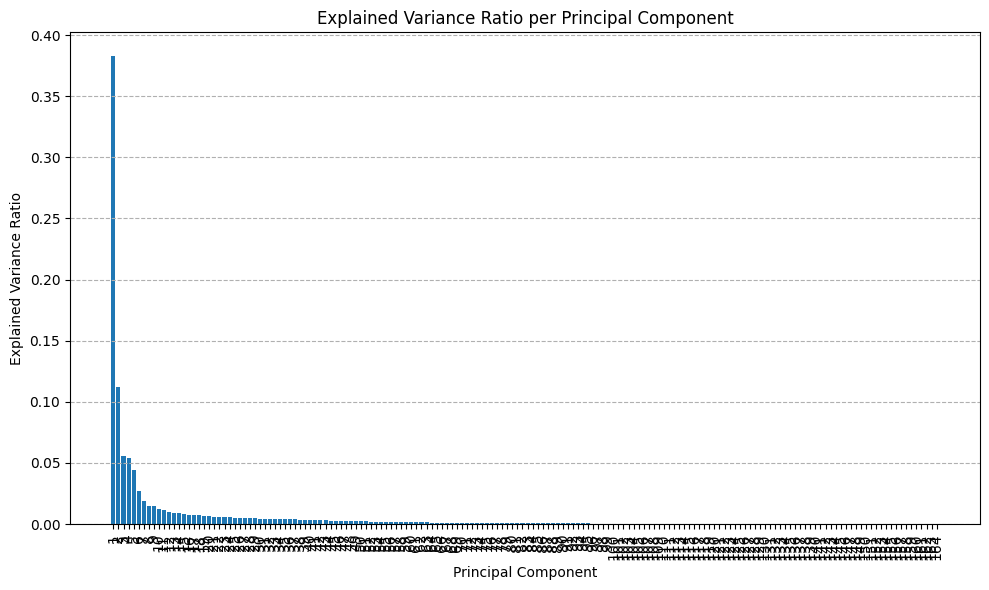

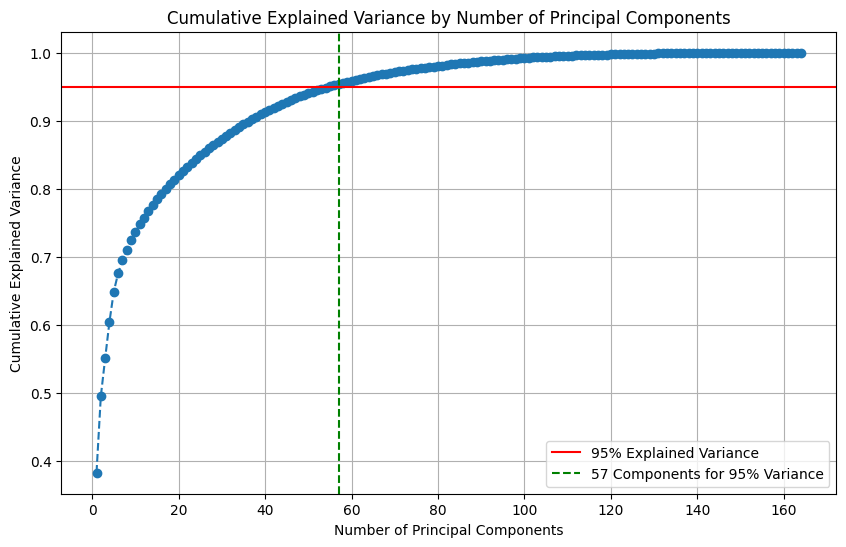

Number of components needed to explain 95% of the variance: 57


In [ ]:
# Plot the percentages of variance explained by each component
# the cumulative variance with a 95% threshold, and calculate the number of components required to reach it.
import matplotlib.pyplot as plt
import numpy as np

# Get the explained variance ratio from the PCA object
explained_variance_ratio = pca.explained_variance_ratio_

# Plot the explained variance ratio for each principal component
plt.figure(figsize=(10, 6))
plt.bar(range(1, len(explained_variance_ratio) + 1), explained_variance_ratio)
plt.title('Explained Variance Ratio per Principal Component')
plt.xlabel('Principal Component')
plt.ylabel('Explained Variance Ratio')
plt.xticks(range(1, len(explained_variance_ratio) + 1), rotation=90)
plt.grid(axis='y', linestyle='--')
plt.tight_layout() # Adjust layout to prevent labels overlapping
plt.show()

# Calculate and plot the cumulative explained variance
cumulative_explained_variance = np.cumsum(explained_variance_ratio)

plt.figure(figsize=(10, 6))
plt.plot(range(1, len(cumulative_explained_variance) + 1), cumulative_explained_variance, marker='o', linestyle='--')
plt.title('Cumulative Explained Variance by Number of Principal Components')
plt.xlabel('Number of Principal Components')
plt.ylabel('Cumulative Explained Variance')
plt.grid(True)

# Add a horizontal line at 95% cumulative explained variance
plt.axhline(y=0.95, color='r', linestyle='-', label='95% Explained Variance')

# Find the number of components needed for 95% variance
n_components_95 = np.argmax(cumulative_explained_variance >= 0.95) + 3
plt.axvline(x=n_components_95, color='g', linestyle='--', label=f'{n_components_95} Components for 95% Variance')

plt.legend()
plt.show()

print(f"Number of components needed to explain 95% of the variance: {n_components_95}")

In [ ]:
# Create a list of column names for the principal components
pca_column_names = [f'principal component {i+1}' for i in range(principal_components.shape[1])]

# Create a new DataFrame from the principal components array
pca_df = pd.DataFrame(principal_components, columns=pca_column_names)

# Select only the first 57 principal components
weather_predictione_pca_reduction = pca_df.iloc[:, :57].copy()

# Display the head of the new DataFrame
print("Nuovo DataFrame con le prime 57 Componenti Principali:")
display(weather_predictione_pca_reduction.head())

print(f"\nIl nuovo dataset ha {weather_predictione_pca_reduction.shape[1]} features e {weather_predictione_pca_reduction.shape[0]} righe.")

# Define the filename for the new dataset
output_filename = 'data/weather_prediction_pca_reduced.csv'

# Save the DataFrame with selected features to a new CSV file
try:
    weather_predictione_pca_reduction.to_csv(output_filename, index=False)
    print(f"Dataset con componenti principali salvato con successo come '{output_filename}'")
except Exception as e:
    print(f"Si è verificato un errore durante il salvataggio del dataset: {e}")

Nuovo DataFrame con le prime 57 Componenti Principali:


,principal component 1,principal component 2,principal component 3,principal component 4,principal component 5,principal component 6,principal component 7,principal component 8,principal component 9,principal component 10,...,principal component 48,principal component 49,principal component 50,principal component 51,principal component 52,principal component 53,principal component 54,principal component 55,principal component 56,principal component 57
0,-10.862496,2.182780,-0.812095,5.271411,0.472973,-1.207269,0.012907,0.926024,-1.909604,0.610384,...,-0.247516,0.262095,-0.031535,0.447178,-0.567152,-0.228418,-0.304020,-0.133884,-0.566448,-0.336005
1,-9.770506,2.978664,0.463637,5.373012,0.202412,0.265952,0.044650,-0.884701,-0.576198,0.832287,...,-0.616355,-0.008326,-0.502765,0.358124,-0.620583,-0.481853,0.049773,-0.057403,0.032885,-0.392676
2,-9.368043,0.723917,4.688040,4.978113,1.036044,2.020357,-0.661766,-1.975452,-0.430434,0.396921,...,-0.151519,0.702562,0.388313,-0.994299,0.131001,-0.784974,-0.187993,0.012346,-0.502115,0.076919
3,-8.495714,-1.320702,5.583118,3.671332,-0.036684,-0.279892,-2.776515,-1.753303,1.969434,-3.743612,...,0.116659,0.531096,-0.741895,-0.691149,-0.297047,-0.171512,-0.757595,-1.199265,-0.139397,0.851675
4,-8.213420,2.585179,2.228551,0.936048,1.431843,2.375013,-0.355721,0.782222,-0.443488,-0.240979,...,-0.050269,0.525214,-0.628438,-0.125746,-0.306249,-0.239528,0.151026,-0.390018,-0.119083,-0.461532



Il nuovo dataset ha 57 features e 3654 righe.
Dataset con componenti principali salvato con successo come 'weather_prediction_pca_reduced.csv'


Generating PCA plots for Basel...


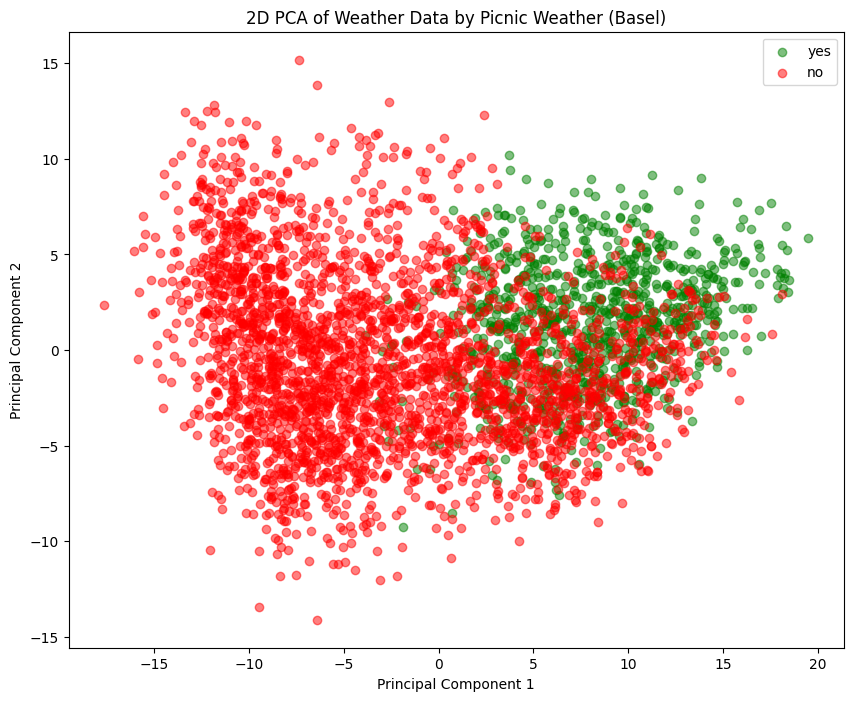

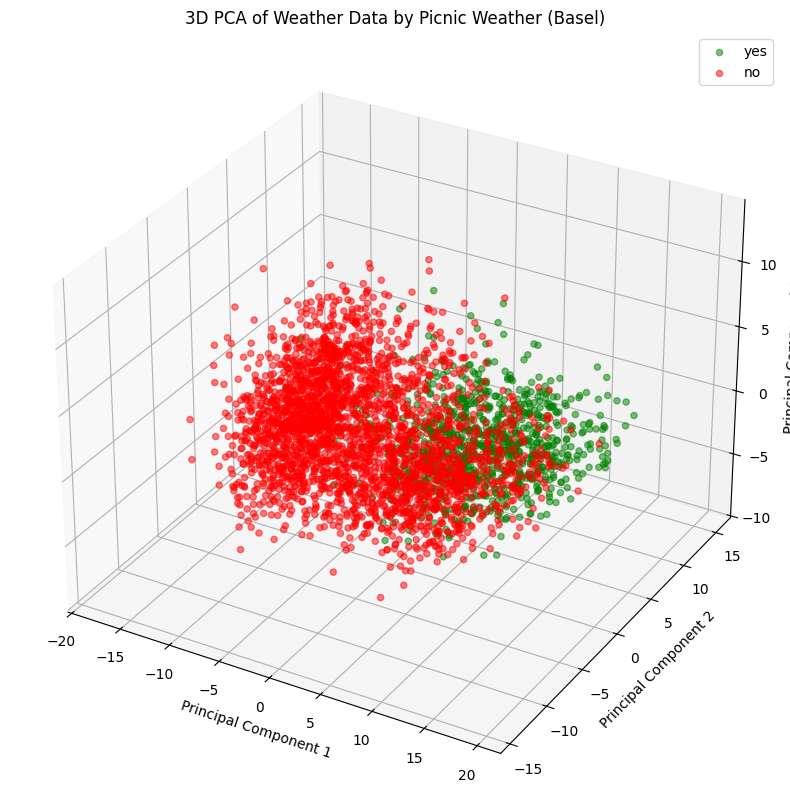

Generating PCA plots for Budapest...


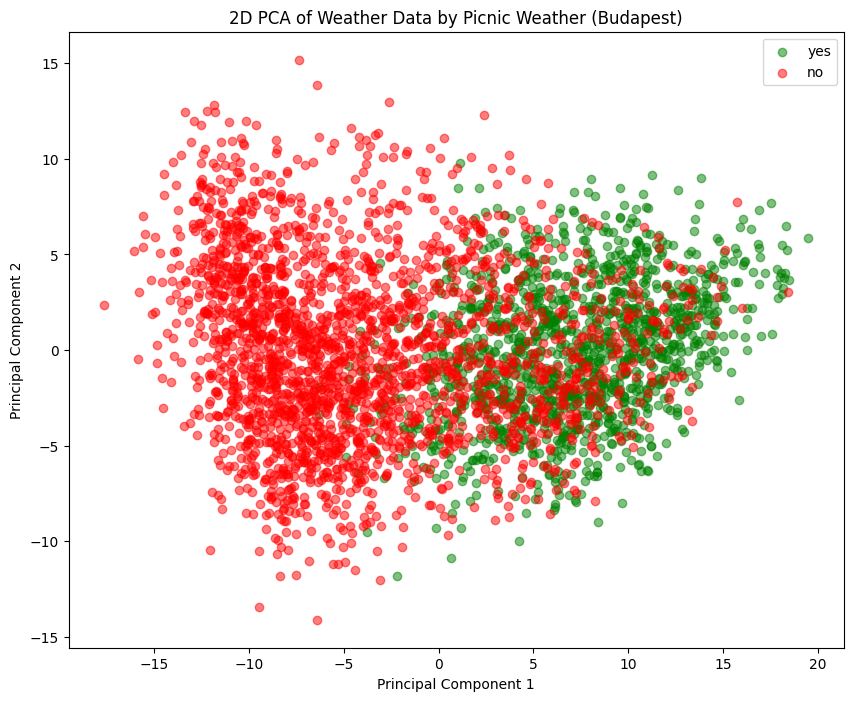

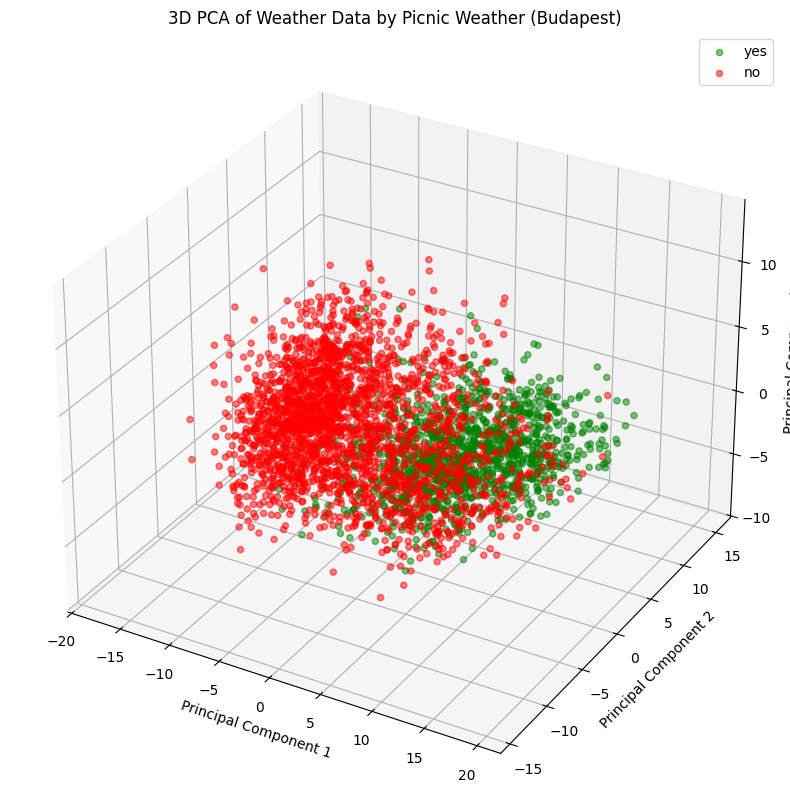

Generating PCA plots for Debilt...


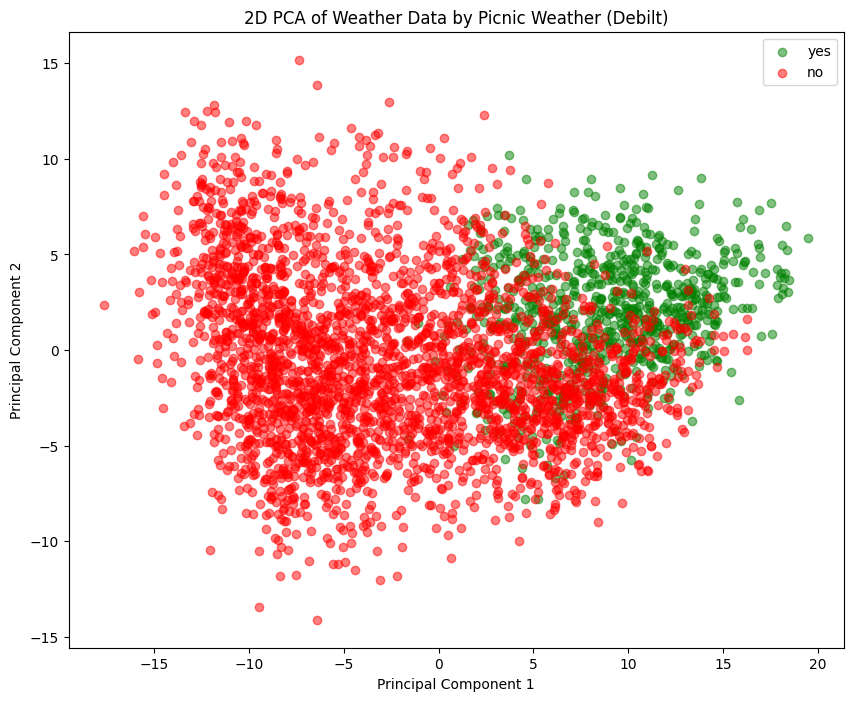

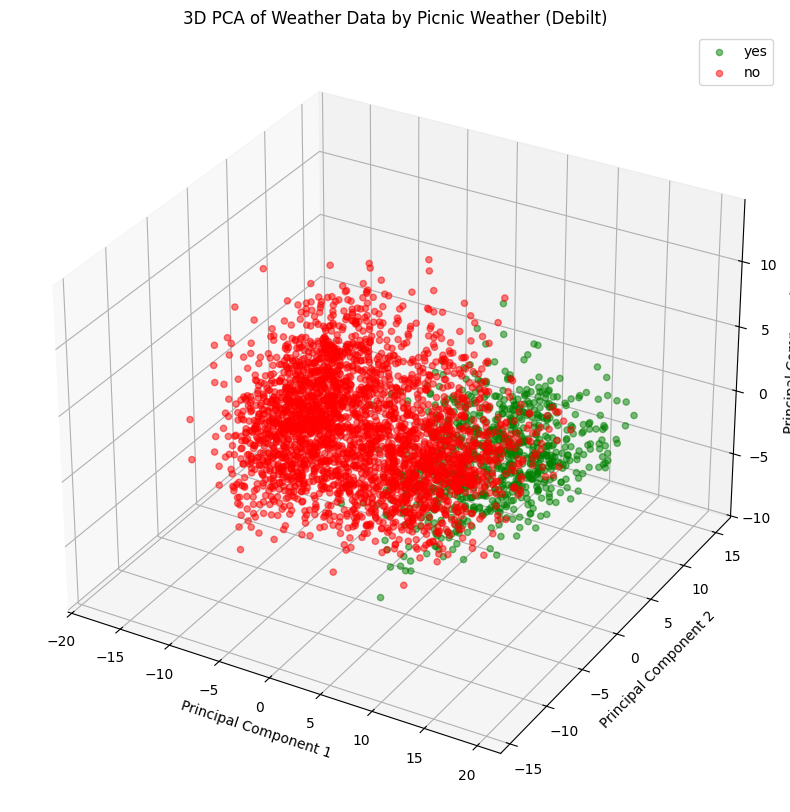

Generating PCA plots for Dresden...


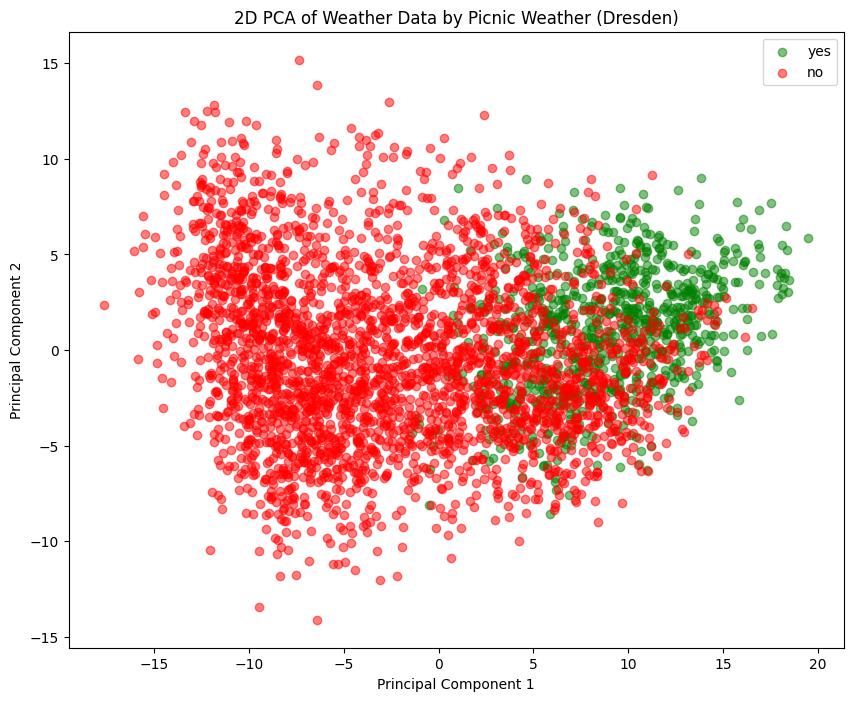

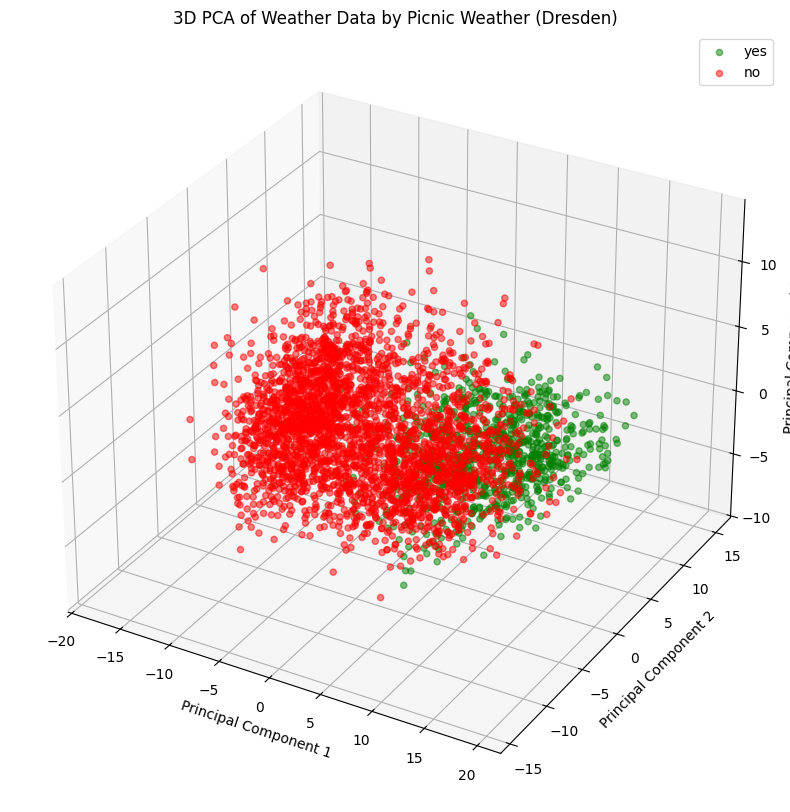

Generating PCA plots for Dusseldorf...


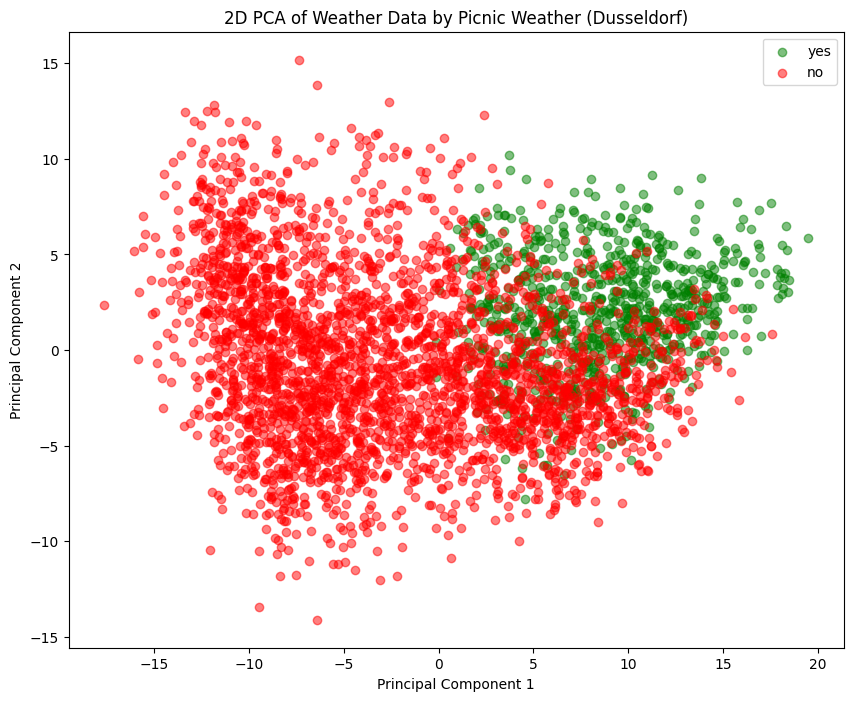

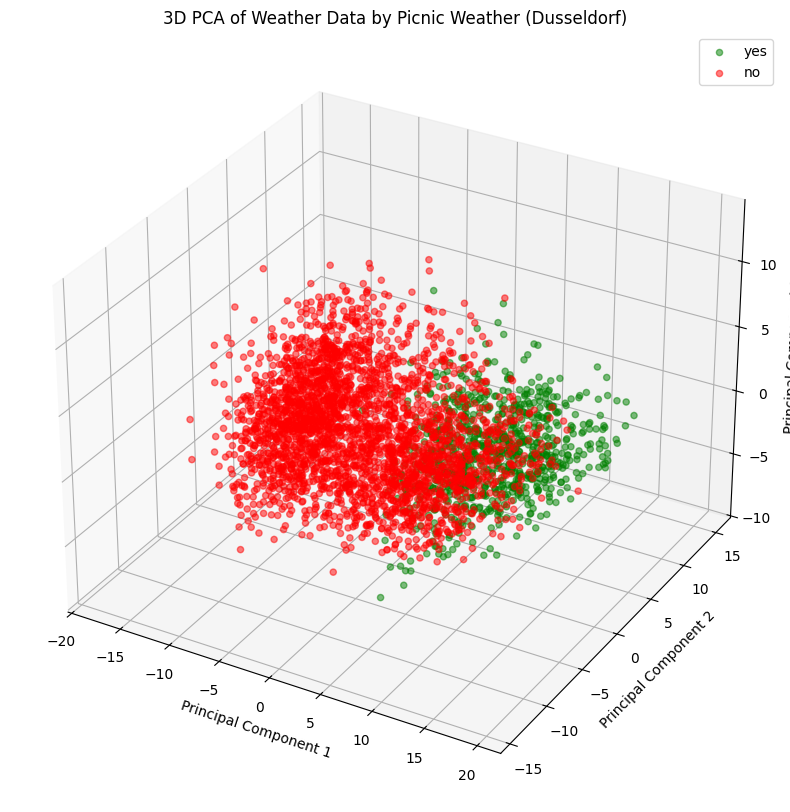

Generating PCA plots for Heathrow...


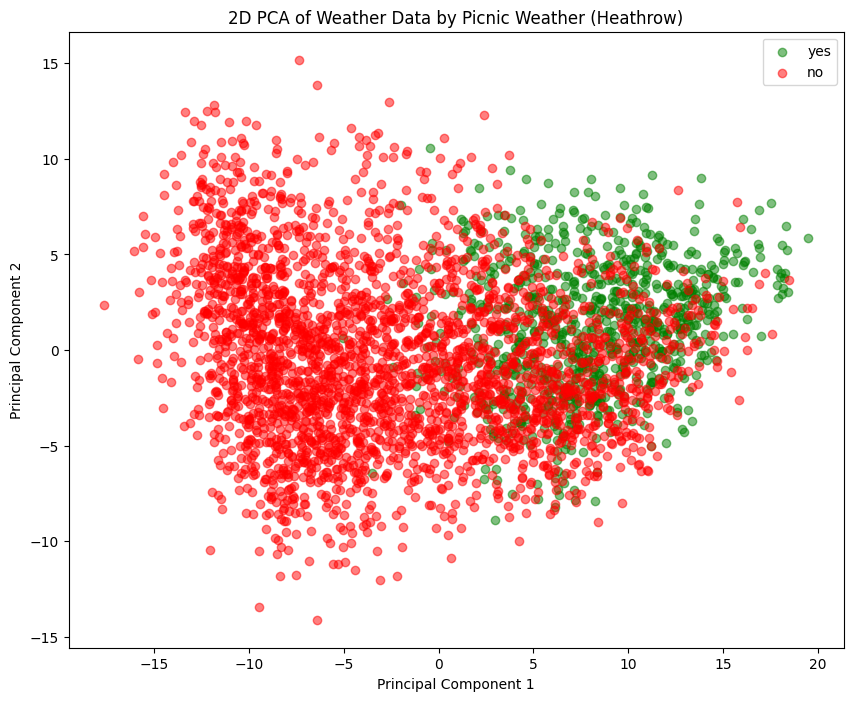

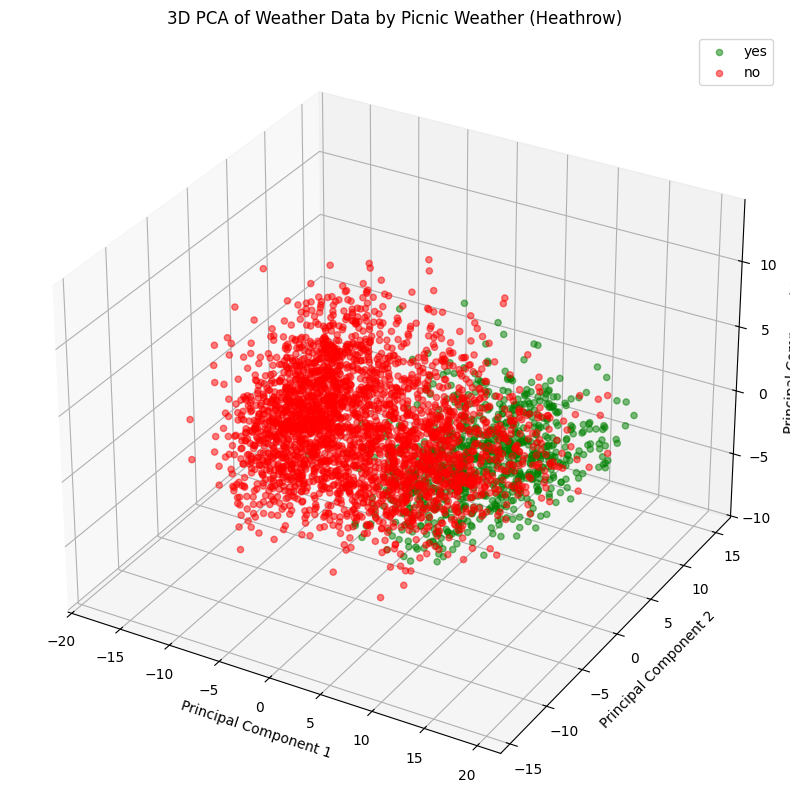

Generating PCA plots for Kassel...


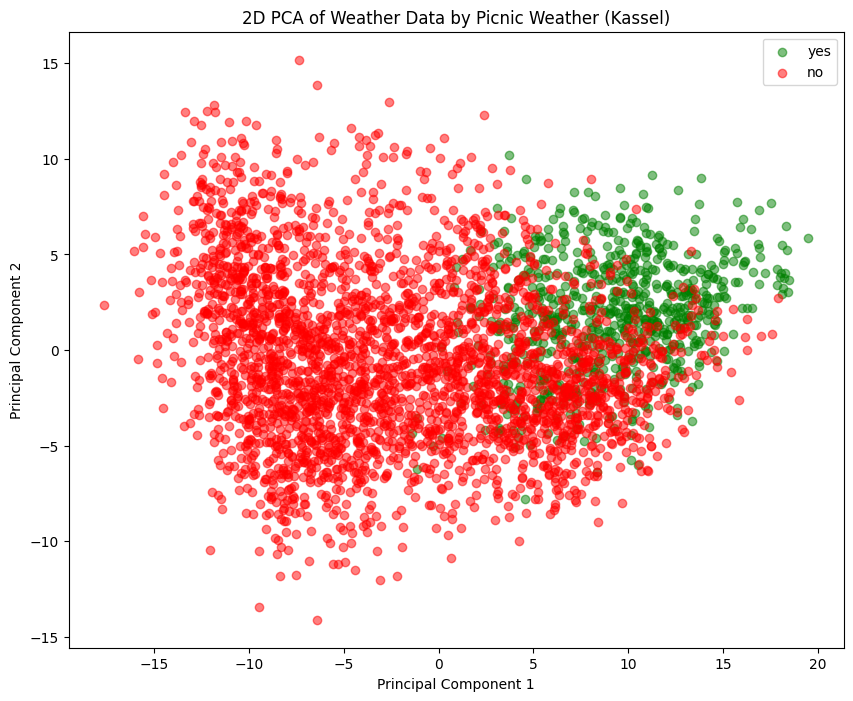

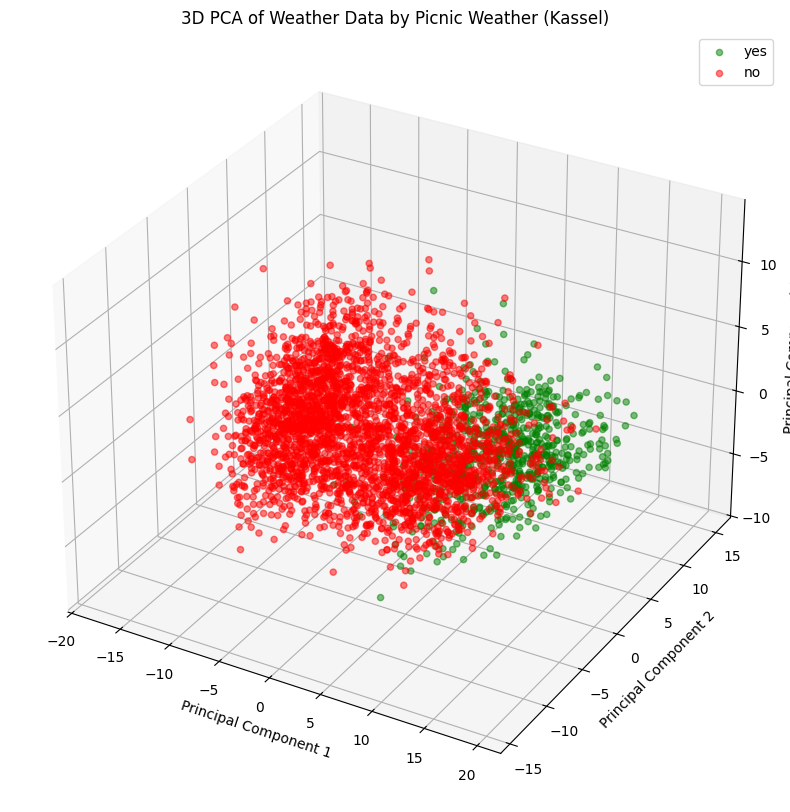

Generating PCA plots for Ljubljana...


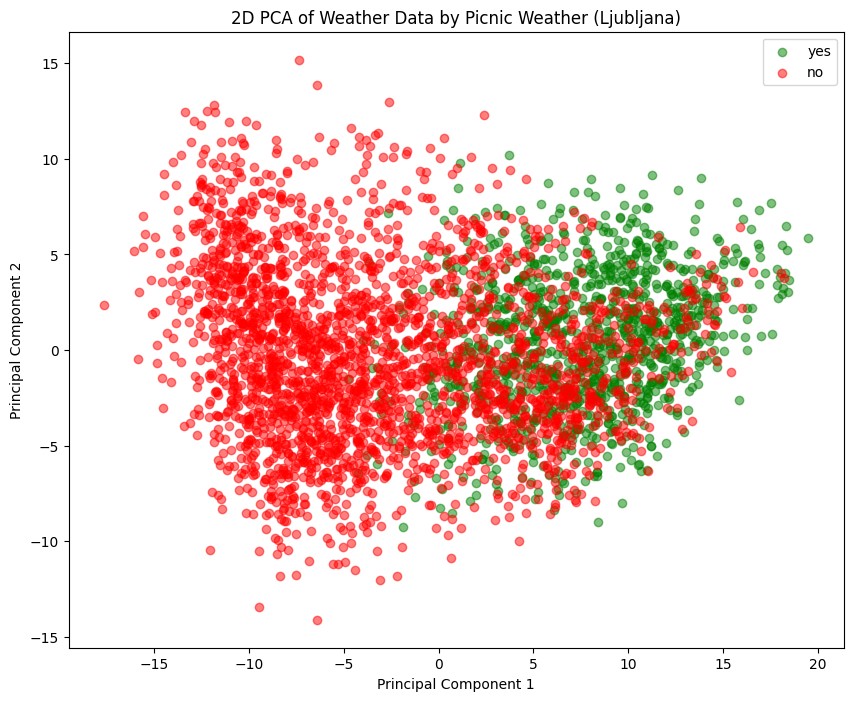

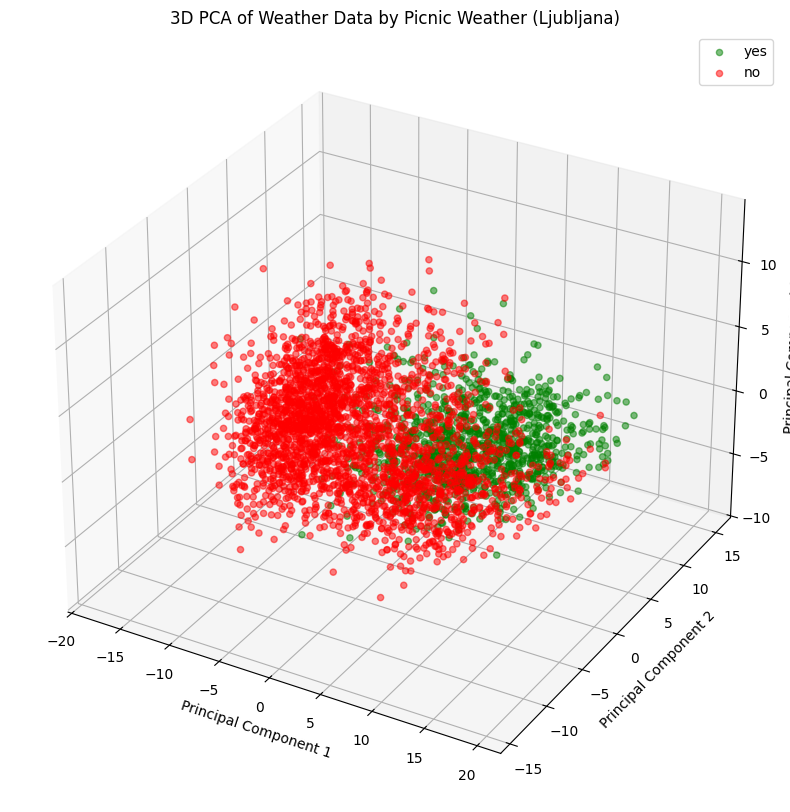

Generating PCA plots for Maastricht...


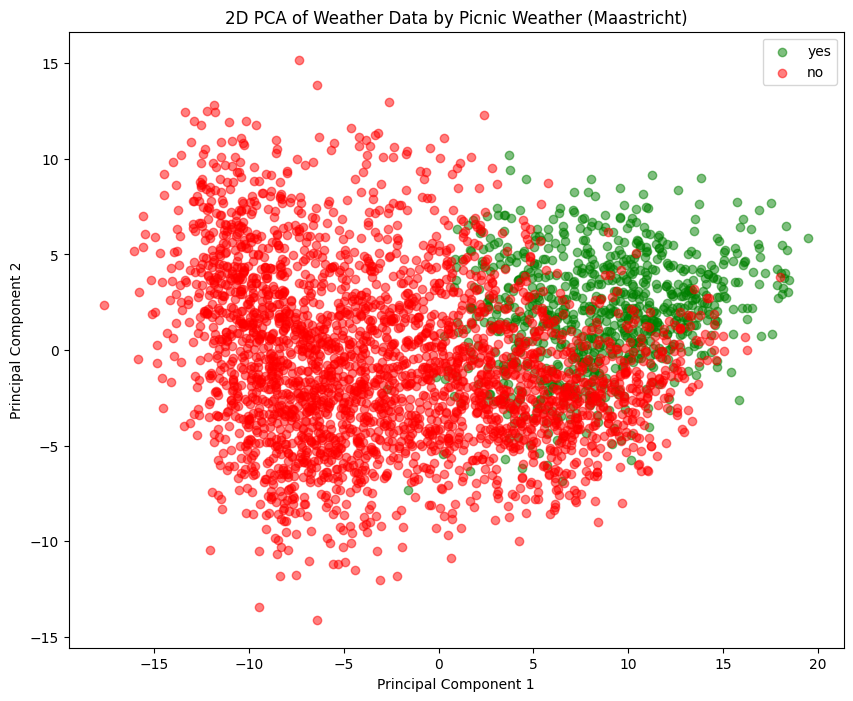

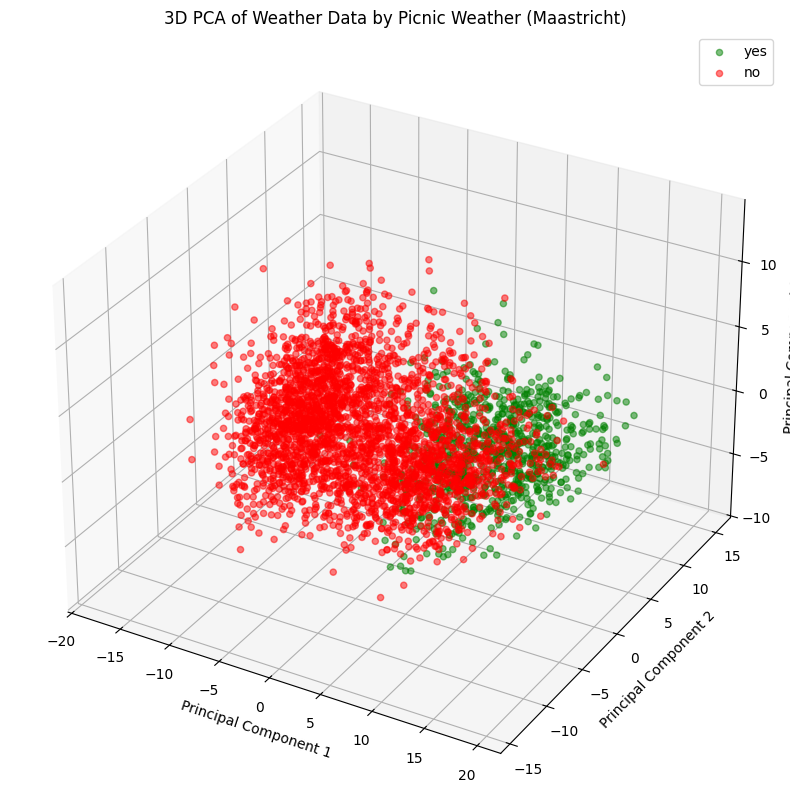

Generating PCA plots for Malmo...


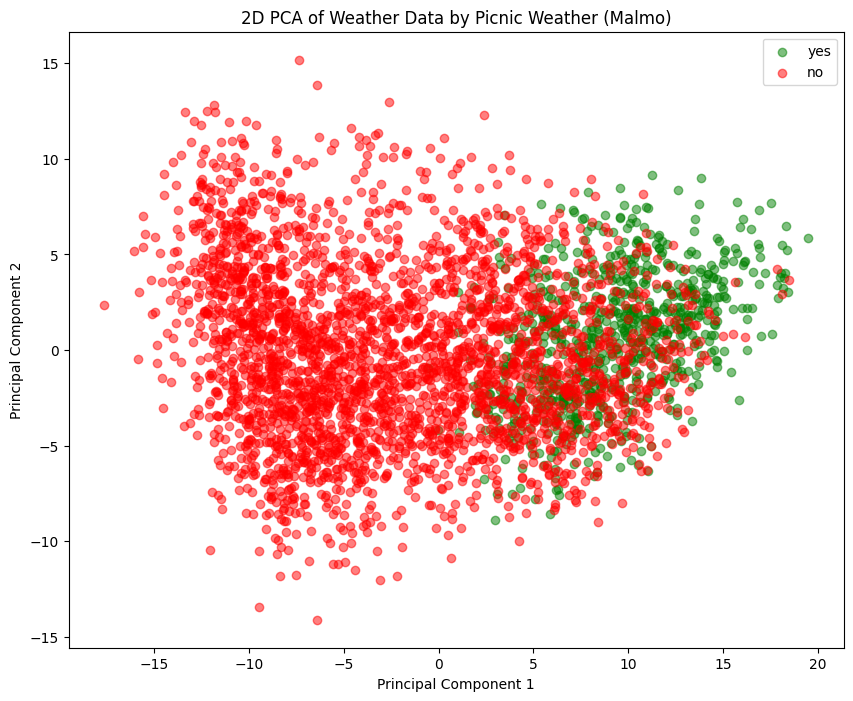

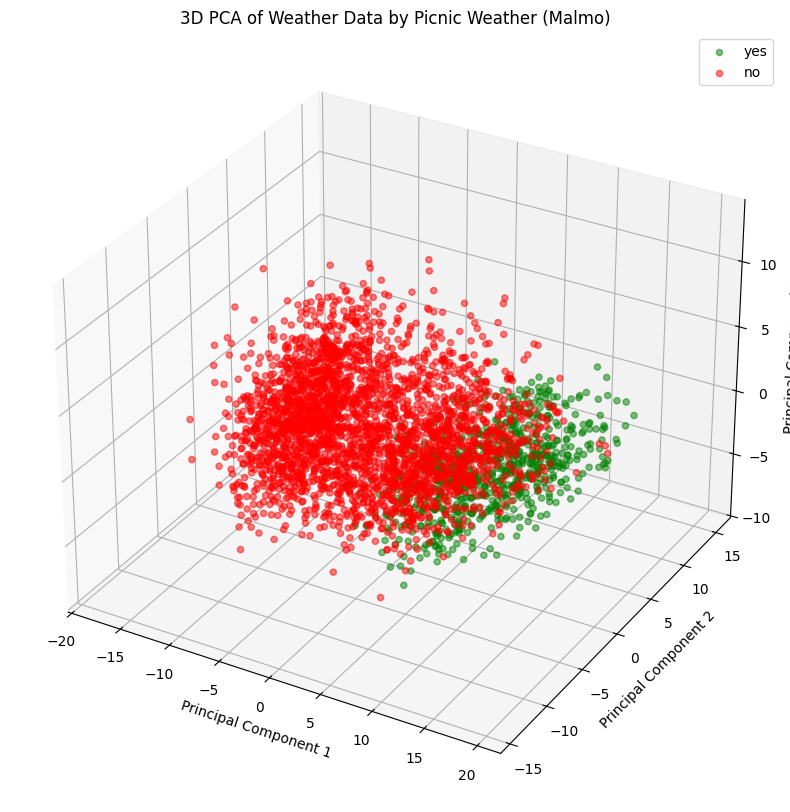

Generating PCA plots for Montelimar...


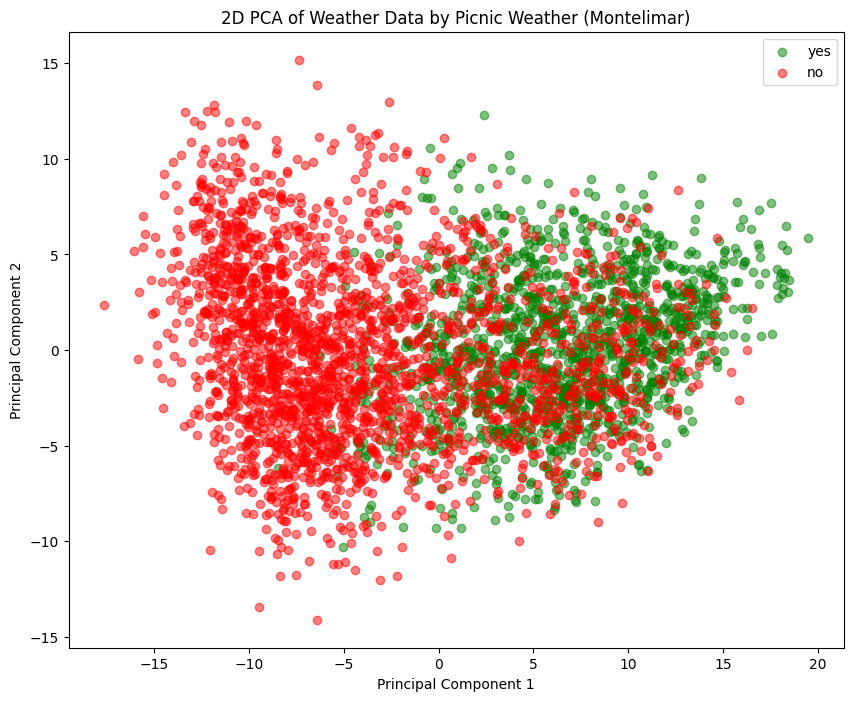

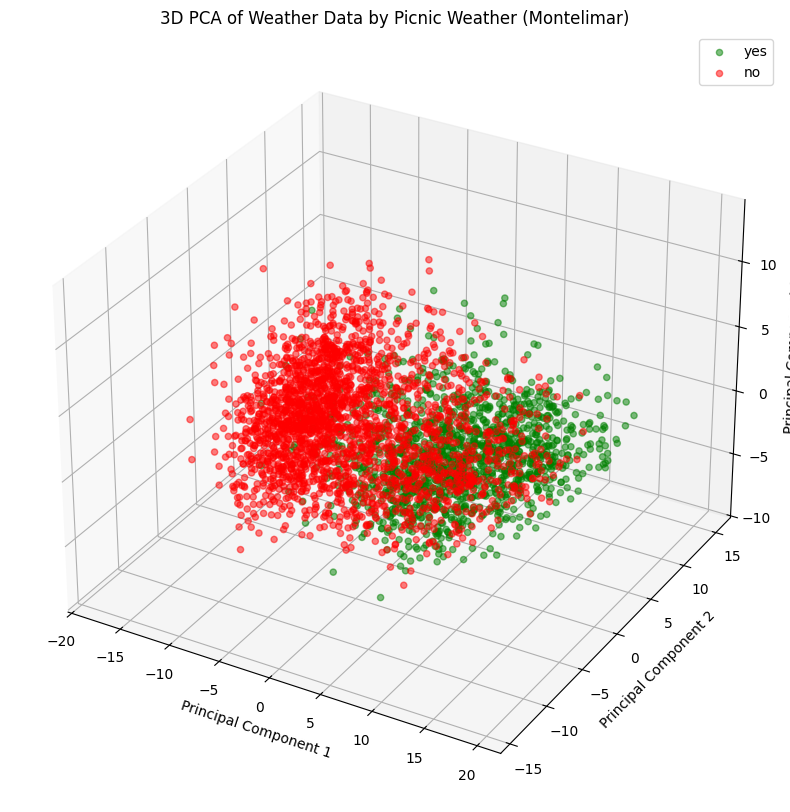

Generating PCA plots for Muenchen...


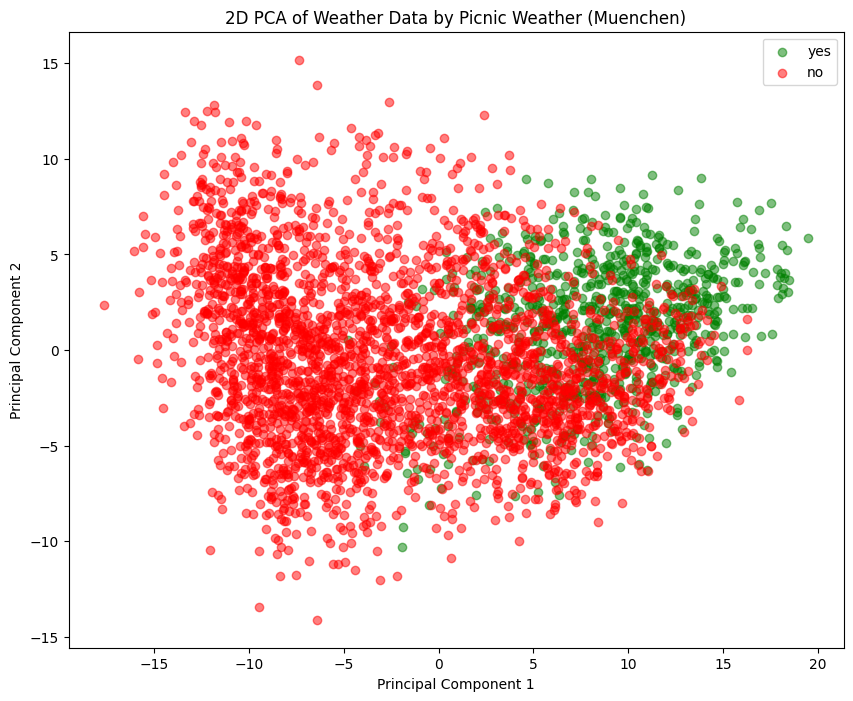

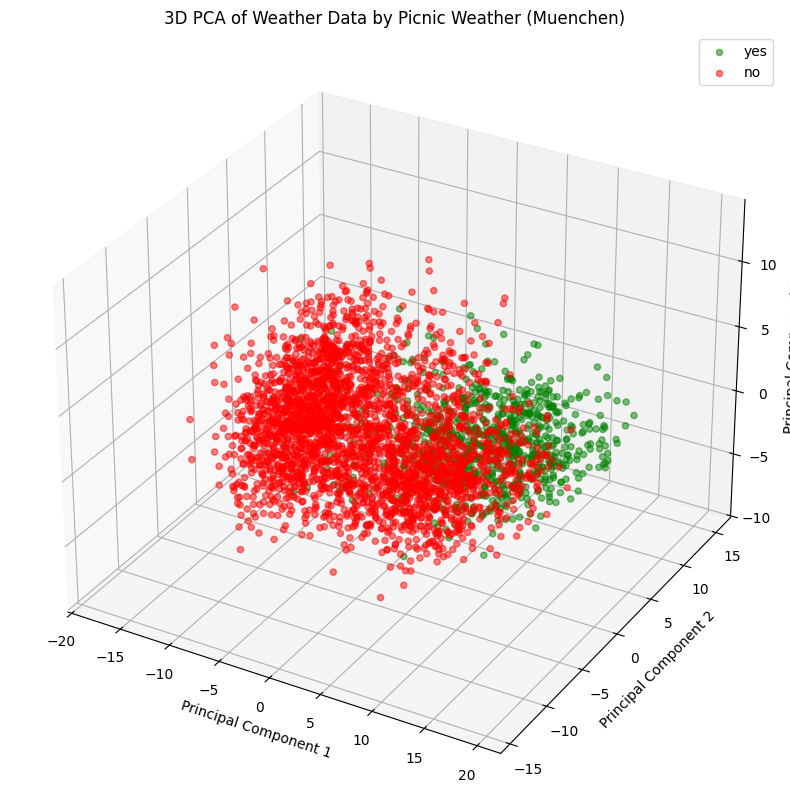

Generating PCA plots for Oslo...


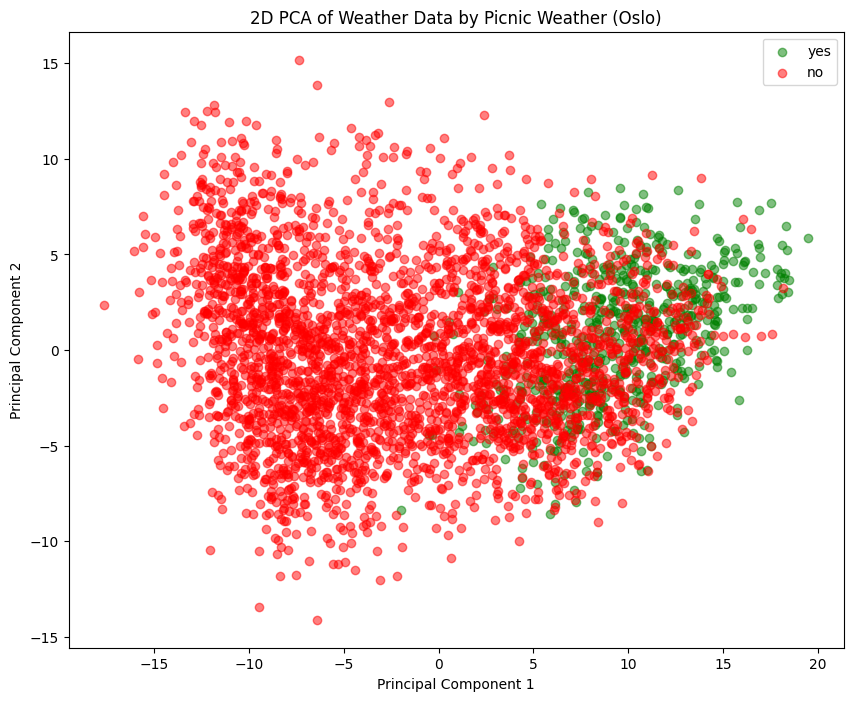

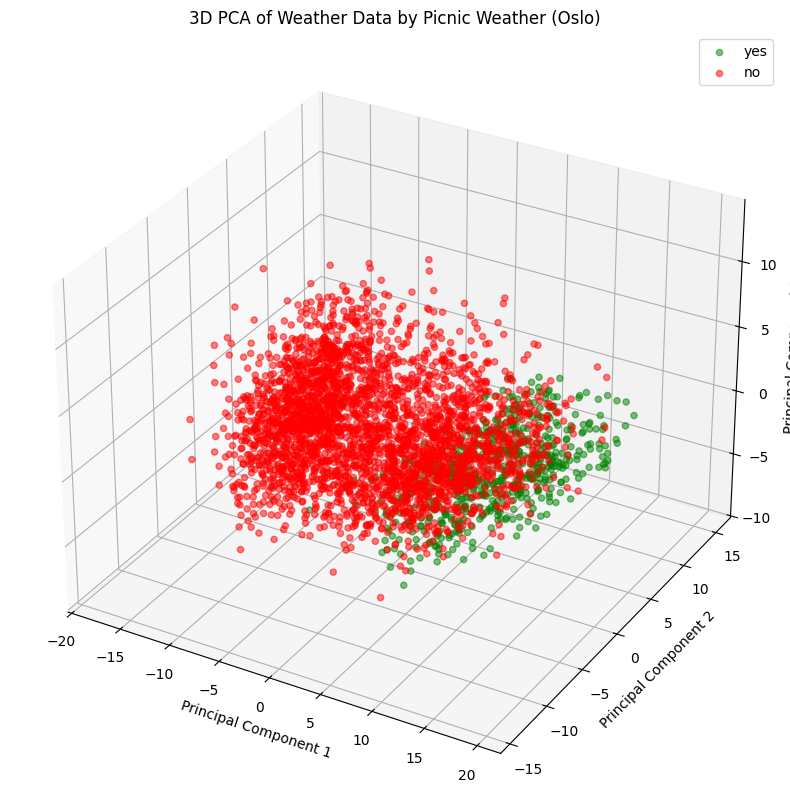

Generating PCA plots for Perpignan...


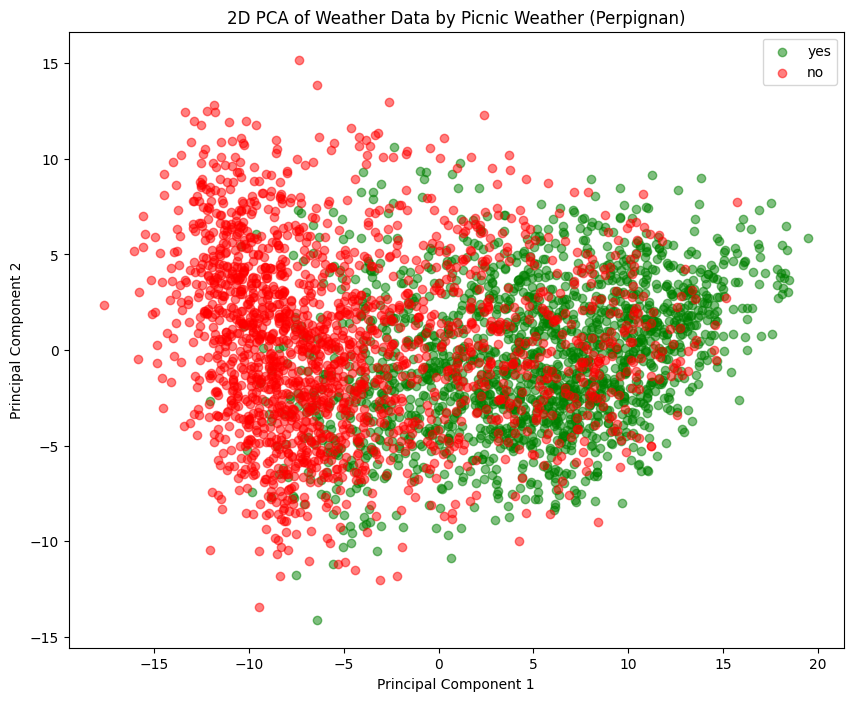

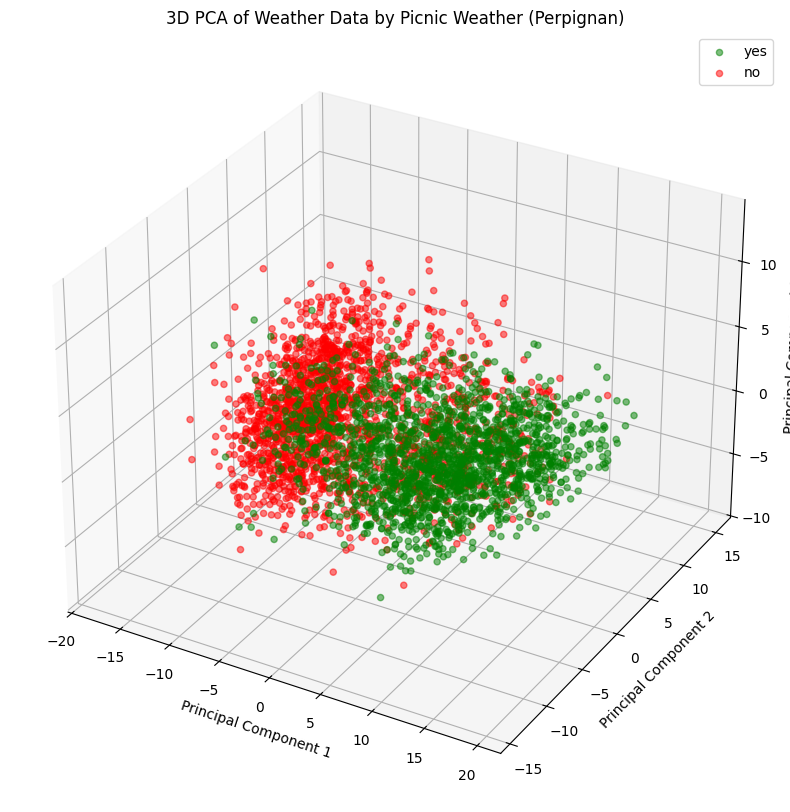

Generating PCA plots for Sonnblick...


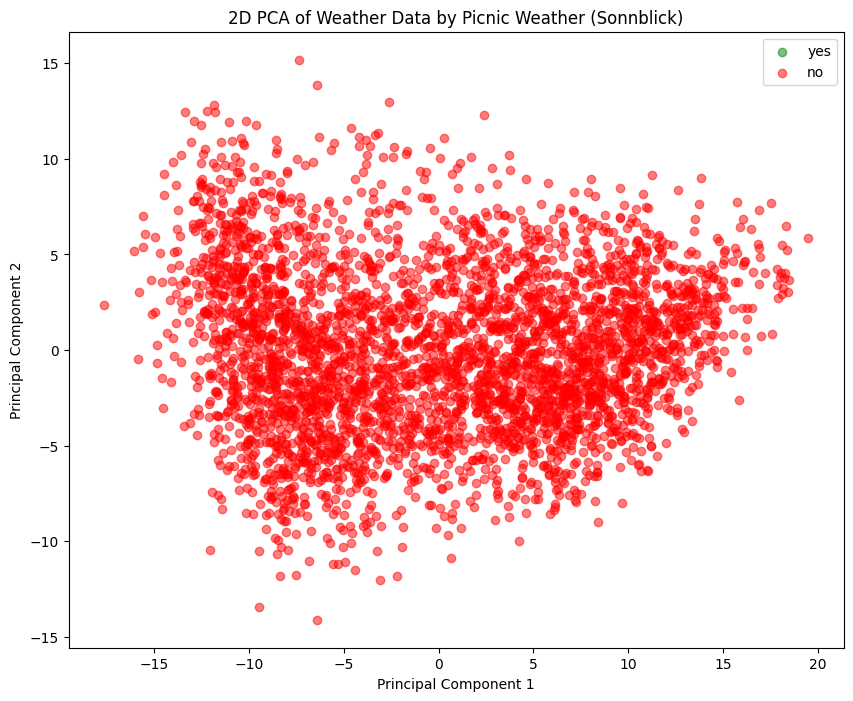

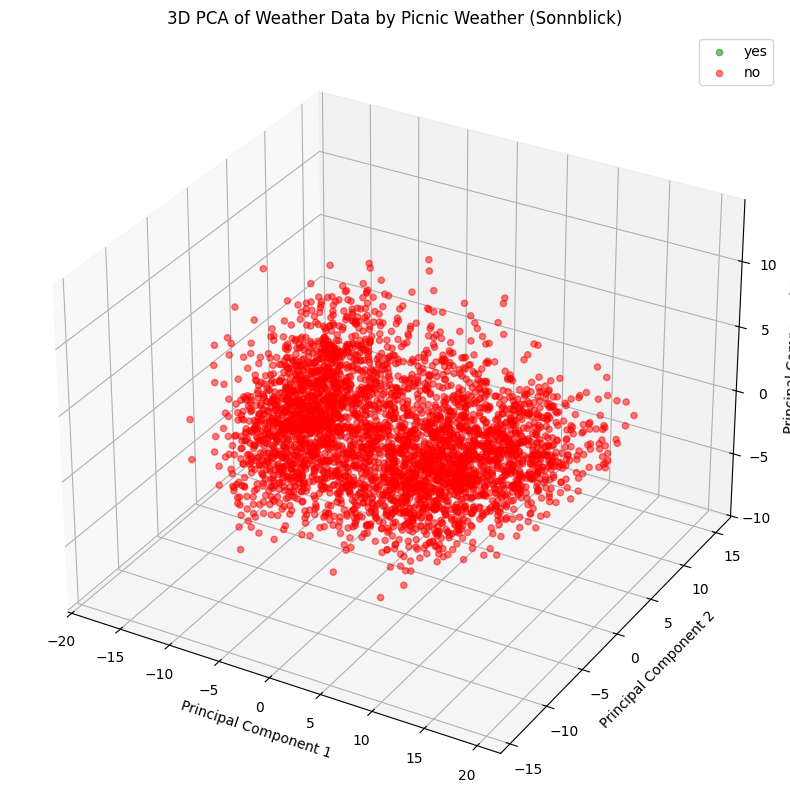

Generating PCA plots for Stockholm...


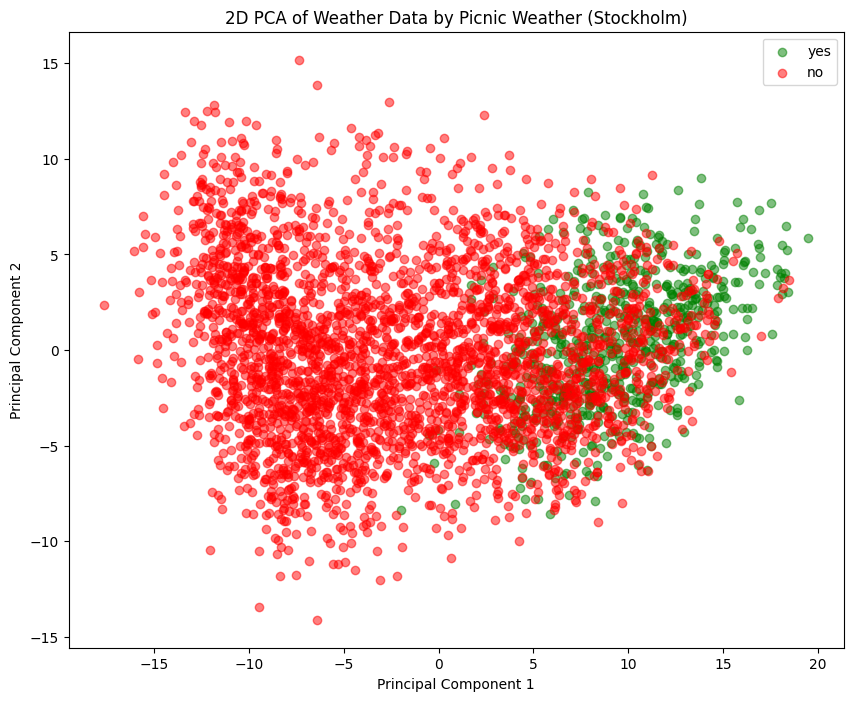

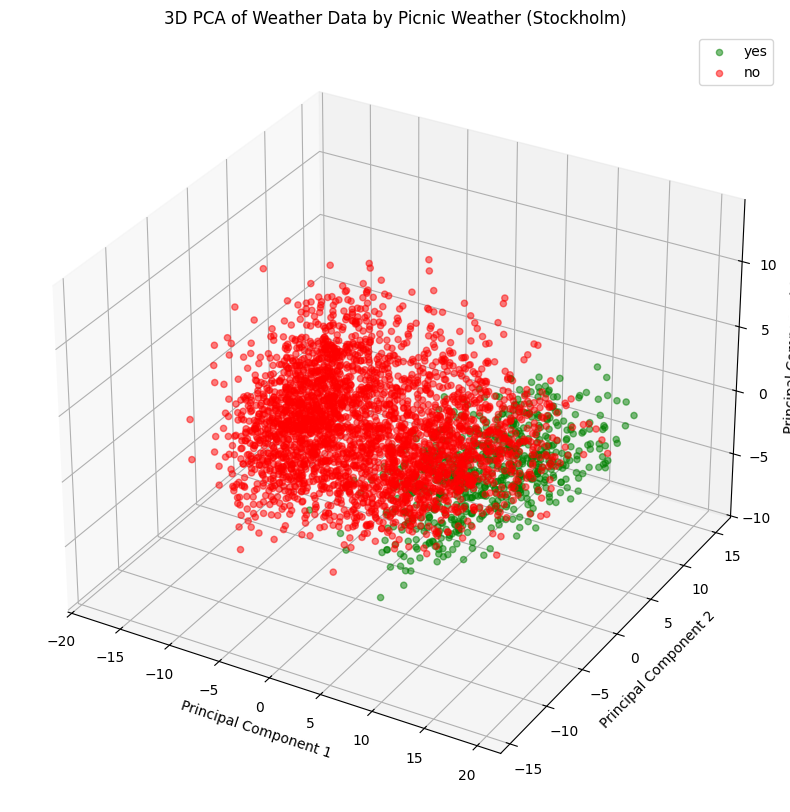

Generating PCA plots for Tours...


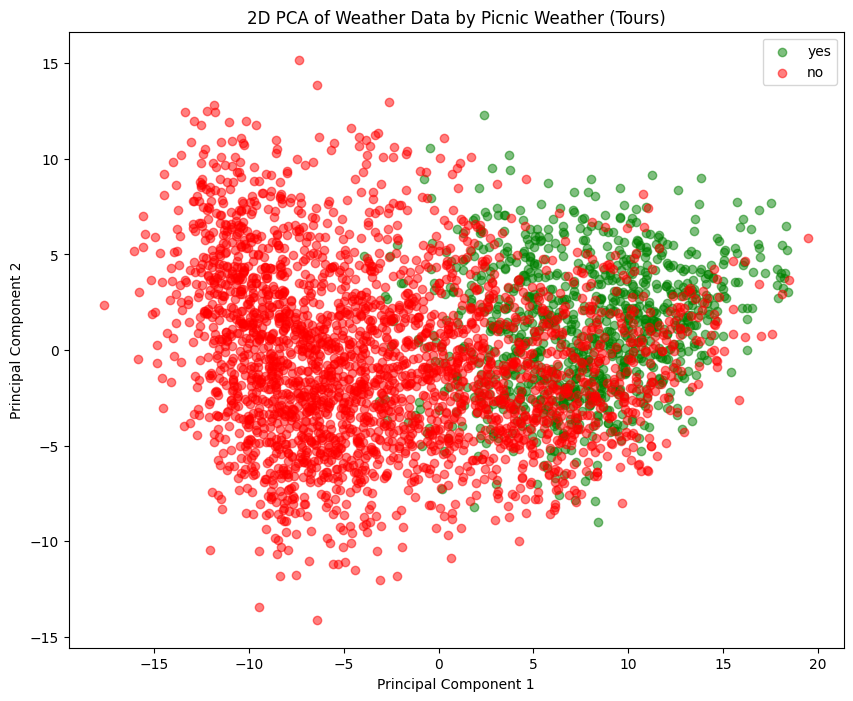

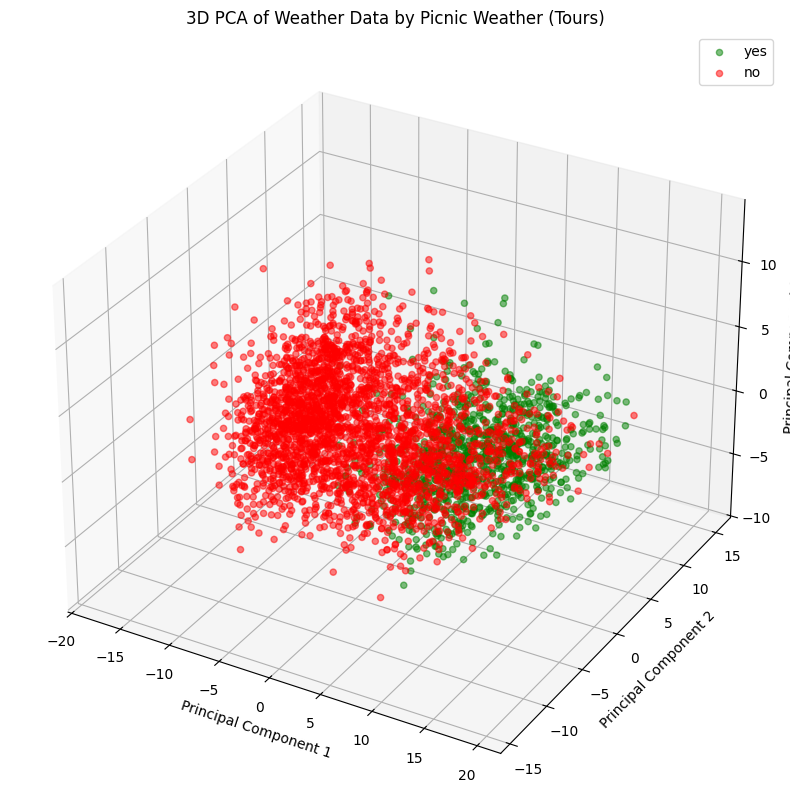

In [ ]:
# Plot 2D and 3D scatter plots for each city
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D
import pandas as pd

# Identify picnic weather columns (assuming df_labels is loaded)
picnic_target_cols = [col for col in df_labels.columns if col.endswith('_picnic_weather')]

# Ensure pca_df exists from previous steps (it should if PCA was run)
if 'pca_df' not in locals():
    print("Error: pca_df not found. Please run the PCA steps first.")
else:
    # Iterate through cities and generate plots
    for target_col in picnic_target_cols:
        # Extract city name from the column name
        city_name = target_col.replace('_picnic_weather', '').replace('_', ' ').title()

        print(f"Generating PCA plots for {city_name}...")

        # Create a temporary DataFrame combining the principal components with the current city's picnic weather
        # Ensure the index aligns
        temp_pca_df = pca_df.copy()
        temp_pca_df[target_col] = df_labels[target_col]


        # Separate data by picnic weather label for coloring
        picnic_yes = temp_pca_df[temp_pca_df[target_col] == True]
        picnic_no = temp_pca_df[temp_pca_df[target_col] == False]

        # --- 2D Plot ---
        plt.figure(figsize=(10, 8))
        plt.scatter(picnic_yes['principal component 1'], picnic_yes['principal component 2'], color='green', label='yes', alpha=0.5)
        plt.scatter(picnic_no['principal component 1'], picnic_no['principal component 2'], color='red', label='no', alpha=0.5)

        plt.xlabel('Principal Component 1')
        plt.ylabel('Principal Component 2')
        plt.title(f'2D PCA of Weather Data by Picnic Weather ({city_name})')
        plt.legend()
        plt.show()

        # --- 3D Plot ---
        fig = plt.figure(figsize=(12, 10))
        ax = fig.add_subplot(111, projection='3d')

        ax.scatter(picnic_yes['principal component 1'], picnic_yes['principal component 2'], picnic_yes['principal component 3'], color='green', label='yes', alpha=0.5)
        ax.scatter(picnic_no['principal component 1'], picnic_no['principal component 2'], picnic_no['principal component 3'], color='red', label='no', alpha=0.5)

        ax.set_xlabel('Principal Component 1')
        ax.set_ylabel('Principal Component 2')
        ax.set_zlabel('Principal Component 3')
        ax.set_title(f'3D PCA of Weather Data by Picnic Weather ({city_name})')
        ax.legend()
        plt.show()

Dataset con feature ridotte (PCA) caricato con successo!


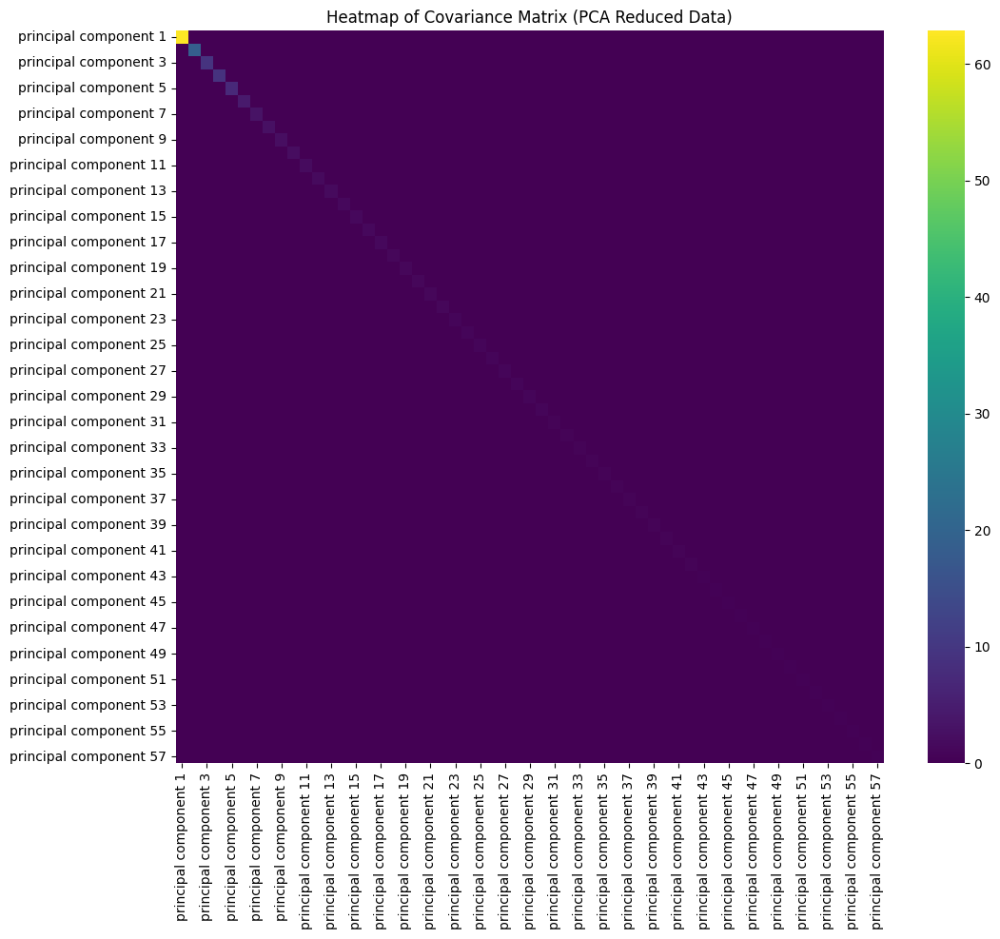

In [ ]:
# Heatmap of Covariance Matrix (PCA Reduced Data)
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

# Load the PCA reduced dataset
try:
    df_pca_reduced = pd.read_csv('data/weather_prediction_pca_reduced.csv')
    print("Dataset con feature ridotte (PCA) caricato con successo!")
except FileNotFoundError:
    print("Errore: File 'data/weather_prediction_pca_reduced.csv' non trovato. Assicurati che il percorso del file sia corretto.")
except Exception as e:
    print(f"Si è verificato un errore durante il caricamento del dataset: {e}")

# Calculate the covariance matrix for the PCA reduced data
covariance_matrix_pca = df_pca_reduced.cov()

# Create a heatmap of the covariance matrix
plt.figure(figsize=(12, 10)) # Adjust figure size as needed
sns.heatmap(covariance_matrix_pca, annot=False, cmap='viridis', fmt=".2f")
plt.title('Heatmap of Covariance Matrix (PCA Reduced Data)')
plt.show()

#T-SNE with PCA


In [ ]:
# Load the dataset reduced by PCA
import pandas as pd

try:
    df_pca_reduced = pd.read_csv('data/weather_prediction_pca_reduced.csv')
    print("Dataset con feature ridotte (PCA) caricato con successo!")
    display(df_pca_reduced.head())
except FileNotFoundError:
    print("Errore: File 'data/weather_prediction_pca_reduced.csv' non trovato. Assicurati che il percorso del file sia corretto.")
except Exception as e:
    print(f"Si è verificato un errore durante il caricamento del dataset: {e}")

Dataset con feature ridotte (PCA) caricato con successo!


,principal component 1,principal component 2,principal component 3,principal component 4,principal component 5,principal component 6,principal component 7,principal component 8,principal component 9,principal component 10,...,principal component 48,principal component 49,principal component 50,principal component 51,principal component 52,principal component 53,principal component 54,principal component 55,principal component 56,principal component 57
0,-10.862496,2.182780,-0.812095,5.271411,0.472973,-1.207269,0.012907,0.926024,-1.909604,0.610384,...,-0.247516,0.262095,-0.031535,0.447178,-0.567152,-0.228418,-0.304020,-0.133884,-0.566448,-0.336005
1,-9.770506,2.978664,0.463637,5.373012,0.202412,0.265952,0.044650,-0.884701,-0.576198,0.832287,...,-0.616355,-0.008326,-0.502765,0.358124,-0.620583,-0.481853,0.049773,-0.057403,0.032885,-0.392676
2,-9.368043,0.723917,4.688040,4.978113,1.036044,2.020357,-0.661766,-1.975452,-0.430434,0.396921,...,-0.151519,0.702562,0.388313,-0.994299,0.131001,-0.784974,-0.187993,0.012346,-0.502115,0.076919
3,-8.495714,-1.320702,5.583118,3.671332,-0.036684,-0.279892,-2.776515,-1.753303,1.969434,-3.743612,...,0.116659,0.531096,-0.741895,-0.691149,-0.297047,-0.171512,-0.757595,-1.199265,-0.139397,0.851675
4,-8.213420,2.585179,2.228551,0.936048,1.431843,2.375013,-0.355721,0.782222,-0.443488,-0.240979,...,-0.050269,0.525214,-0.628438,-0.125746,-0.306249,-0.239528,0.151026,-0.390018,-0.119083,-0.461532


In [ ]:
# Apply t-SNE to the dataset already reduced via PCA
from sklearn.manifold import TSNE
import time

# Instantiate t-SNE. We'll reduce to 2 components for visualization.
tsne_pca = TSNE(n_components=2, perplexity=5, learning_rate='auto', n_iter=3000, random_state=42)

print("Applicando t-SNE sul dataset ridotto con PCA. Questo potrebbe richiedere del tempo...")
t0_pca = time.time()

# Fit and transform the PCA reduced features
tsne_components_pca = tsne_pca.fit_transform(df_pca_reduced)

t1_pca = time.time()
print(f"t-SNE completato in {t1_pca - t0_pca:.2f} secondi.")

# Display the shape of the t-SNE components array
print("Shape of t-SNE components array:", tsne_components_pca.shape)

Applicando t-SNE sul dataset ridotto con PCA. Questo potrebbe richiedere del tempo...


/usr/local/lib/python3.11/dist-packages/sklearn/manifold/_t_sne.py:1164: FutureWarning: 'n_iter' was renamed to 'max_iter' in version 1.5 and will be removed in 1.7.
  warnings.warn(


t-SNE completato in 80.56 secondi.
Shape of t-SNE components array: (3654, 2)


In [ ]:
import pandas as pd

# Create a DataFrame from the t-SNE components obtained from PCA reduced data
tsne_pca_df = pd.DataFrame(tsne_components_pca, columns=['t-sne component 1', 't-sne component 2'])

# Load the original labels dataset if not already loaded
try:
    df_labels = pd.read_csv('data/weather_prediction_picnic_labels.csv')
    print("Picnic labels dataset caricato con successo!")
except FileNotFoundError:
    print("Errore: File 'data/weather_prediction_picnic_labels.csv' non trovato. Assicurati che il file path sia corretto.")
except Exception as e:
    print(f"An error occurred while loading the picnic labels dataset: {e}")

# Add a picnic weather label column (e.g., PERPIGNAN) to the t-SNE DataFrame
# Ensure the index aligns if necessary
if 'PERPIGNAN_picnic_weather' in df_labels.columns:
    tsne_pca_df['PERPIGNAN_picnic_weather'] = df_labels['PERPIGNAN_picnic_weather']
    print("Colonna 'PERPIGNAN_picnic_weather' aggiunta al DataFrame t-SNE.")
else:
    print("Warning: Colonna 'PERPIGNAN_picnic_weather' non trovata nel dataset dei label. Il DataFrame t-SNE non includerà i label.")

# Display the head of the new DataFrame
print("\nHead of the t-SNE DataFrame (from PCA) with labels:")
display(tsne_pca_df.head())

Picnic labels dataset caricato con successo!
Colonna 'PERPIGNAN_picnic_weather' aggiunta al DataFrame t-SNE.

Head of the t-SNE DataFrame (from PCA) with labels:


,t-sne component 1,t-sne component 2,PERPIGNAN_picnic_weather
0,-102.993195,32.635826,False
1,-103.005585,31.989460,False
2,-55.356525,46.205803,False
3,-55.474697,40.497929,False
4,-61.295296,49.014572,False


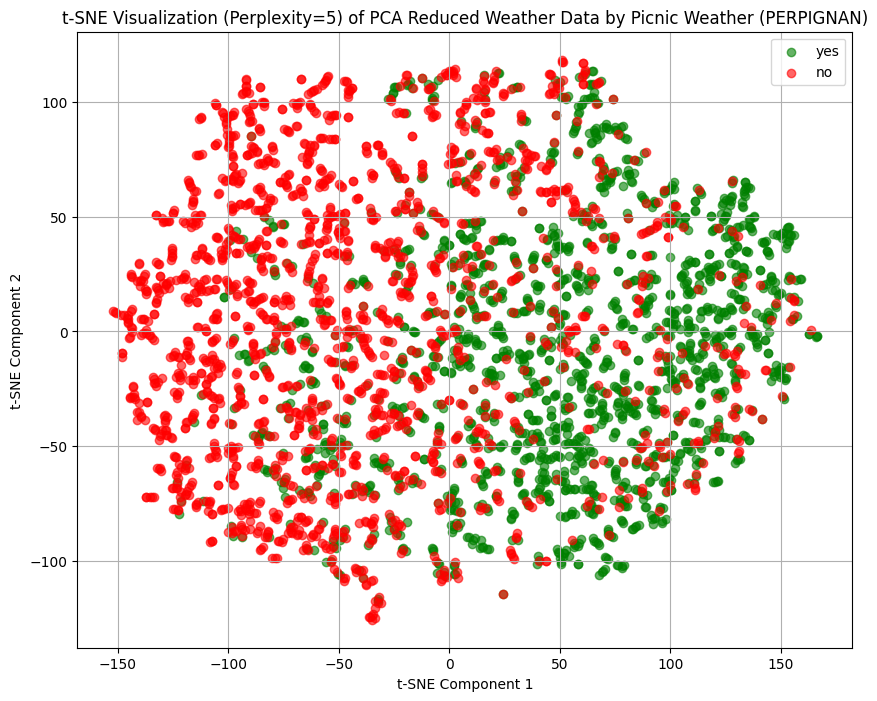

In [ ]:
# Generate 2D scatter plot
import matplotlib.pyplot as plt
import seaborn as sns

# Visualize the t-SNE components, colored by the picnic weather label
plt.figure(figsize=(10, 8))

# Separate data by picnic weather label for coloring
picnic_yes_tsne_pca = tsne_pca_df[tsne_pca_df['PERPIGNAN_picnic_weather'] == True]
picnic_no_tsne_pca = tsne_pca_df[tsne_pca_df['PERPIGNAN_picnic_weather'] == False]

# Create the scatter plot
plt.scatter(picnic_yes_tsne_pca['t-sne component 1'], picnic_yes_tsne_pca['t-sne component 2'], color='green', label='yes', alpha=0.6)
plt.scatter(picnic_no_tsne_pca['t-sne component 1'], picnic_no_tsne_pca['t-sne component 2'], color='red', label='no', alpha=0.6)

# Add labels and title
plt.xlabel('t-SNE Component 1')
plt.ylabel('t-SNE Component 2')
plt.title(f't-SNE Visualization (Perplexity={tsne_pca.perplexity}) of PCA Reduced Weather Data by Picnic Weather (PERPIGNAN)') # Added perplexity to title
plt.legend()
plt.grid(True)

# Display the plot
plt.show()

Picnic labels dataset caricato con successo!

Applicando t-SNE con 3 componenti sul dataset ridotto con PCA. Questo potrebbe richiedere del tempo...


/usr/local/lib/python3.11/dist-packages/sklearn/manifold/_t_sne.py:1164: FutureWarning: 'n_iter' was renamed to 'max_iter' in version 1.5 and will be removed in 1.7.
  warnings.warn(


t-SNE completato in 432.04 secondi.


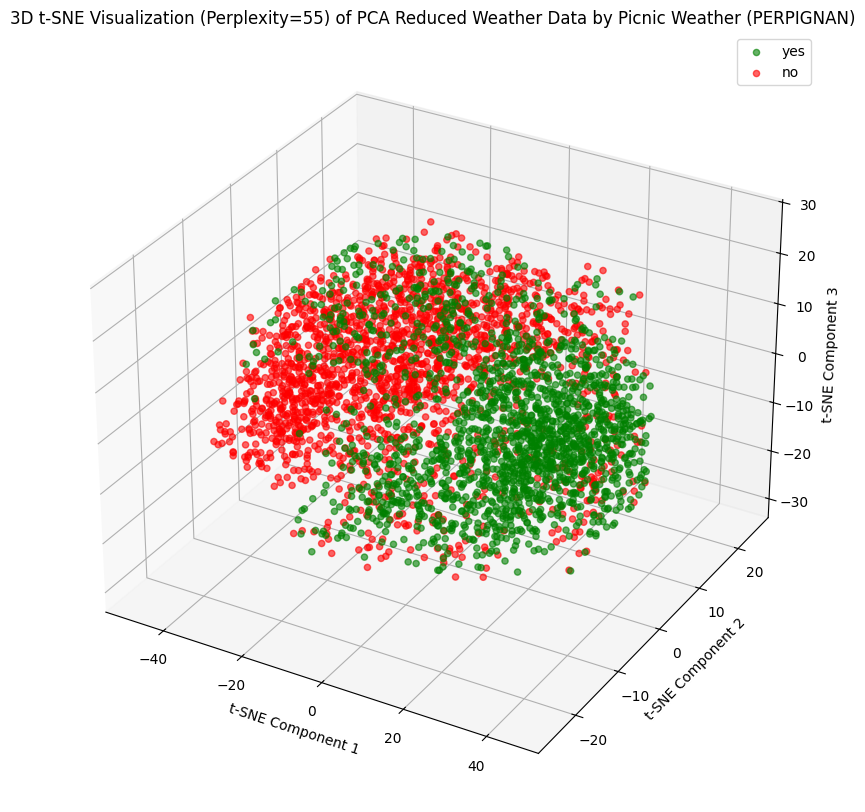

In [ ]:
# Generate 3D scatter plot
from sklearn.manifold import TSNE
import time
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D # Import for 3D plotting
import pandas as pd


# Load the original labels dataset to get the 'PERPIGNAN_picnic_weather' column
try:
    df_labels = pd.read_csv('data/weather_prediction_picnic_labels.csv')
    print("Picnic labels dataset caricato con successo!")
except FileNotFoundError:
    print("Errore: File 'data/weather_prediction_picnic_labels.csv' non trovato. Assicurati che il percorso del file sia corretto.")
except Exception as e:
    print(f"Si è verificato un errore durante il caricamento del dataset dei label: {e}")

# Identify the target label column
target_label_col = 'PERPIGNAN_picnic_weather'

# Check if the target label column exists
if target_label_col not in df_labels.columns:
    print(f"Errore: Colonna '{target_label_col}' non trovata nel dataset dei label. Impossibile generare il grafico con i label.")
else:
    # Instantiate t-SNE. We'll reduce to 3 components for visualization.
    # Experiment with perplexity (e.g., 5 to 50) and n_iter (e.g., 250 to 3000 or more) for better results.
    tsne_pca_3d = TSNE(n_components=3, perplexity=55, learning_rate='auto', n_iter=3000, random_state=42) # Set n_components to 3

    print("\nApplicando t-SNE con 3 componenti sul dataset ridotto con PCA. Questo potrebbe richiedere del tempo...")
    t0 = time.time()

    # Fit and transform the PCA reduced features
    tsne_components_pca_3d = tsne_pca_3d.fit_transform(df_pca_reduced)

    t1 = time.time()
    print(f"t-SNE completato in {t1 - t0:.2f} secondi.")

    # Create a DataFrame from the 3D t-SNE components
    tsne_pca_3d_df = pd.DataFrame(tsne_components_pca_3d, columns=['t-sne component 1', 't-sne component 2', 't-sne component 3'])

    # Add the target label column to the t-SNE DataFrame
    tsne_pca_3d_df[target_label_col] = df_labels[target_label_col]

    # Visualize the 3D t-SNE components, colored by the picnic weather label
    fig = plt.figure(figsize=(12, 10))
    ax = fig.add_subplot(111, projection='3d')

    # Separate data by picnic weather label for coloring
    picnic_yes_tsne_pca_3d = tsne_pca_3d_df[tsne_pca_3d_df[target_label_col] == True]
    picnic_no_tsne_pca_3d = tsne_pca_3d_df[tsne_pca_3d_df[target_label_col] == False]

    # Create the 3D scatter plot
    ax.scatter(picnic_yes_tsne_pca_3d['t-sne component 1'], picnic_yes_tsne_pca_3d['t-sne component 2'], picnic_yes_tsne_pca_3d['t-sne component 3'], color='green', label='yes', alpha=0.6)
    ax.scatter(picnic_no_tsne_pca_3d['t-sne component 1'], picnic_no_tsne_pca_3d['t-sne component 2'], picnic_no_tsne_pca_3d['t-sne component 3'], color='red', label='no', alpha=0.6)

    # Add labels and title
    ax.set_xlabel('t-SNE Component 1')
    ax.set_ylabel('t-SNE Component 2')
    ax.set_zlabel('t-SNE Component 3')
    ax.set_title(f'3D t-SNE Visualization (Perplexity={tsne_pca_3d.perplexity}) of PCA Reduced Weather Data by Picnic Weather (PERPIGNAN)')
    ax.legend()
    plt.show()

In [ ]:
# Create a DataFrame from the t-SNE components (from PCA reduced data)
import pandas as pd


# We'll use the tsne_components_pca array generated earlier
if 'tsne_components_pca' in locals():
    tsne_pca_reduced_df = pd.DataFrame(tsne_components_pca, columns=['t-sne component 1', 't-sne component 2'])

    # Define the filename for the t-SNE on PCA reduced data dataset
    output_filename_tsne_pca_reduced = 'data/weather_prediction_tsne_pca_reduced.csv'

    # Save the DataFrame to a new CSV file
    try:
        tsne_pca_reduced_df.to_csv(output_filename_tsne_pca_reduced, index=False)
        print(f"Dataset con componenti t-SNE (dati PCA ridotti) salvato con successo come '{output_filename_tsne_pca_reduced}'")
    except Exception as e:
        print(f"Si è verificato un errore durante il salvataggio del dataset (t-SNE su dati PCA ridotti): {e}")
else:
     print("Errore: Le componenti t-SNE per i dati ridotti con PCA (tsne_components_pca) non sono state trovate. Assicurati di aver eseguito i passaggi di t-SNE sui dati PCA ridotti.")

Dataset con componenti t-SNE (dati PCA ridotti) salvato con successo come 'weather_prediction_tsne_pca_reduced.csv'


# DT

Train cities: ['BASEL' 'BUDAPEST' 'HEATHROW' 'STOCKHOLM' 'MUENCHEN' 'SONNBLICK'
 'MAASTRICHT' 'PERPIGNAN' 'DEBILT' 'MALMO' 'TOURS']
Val   cities: ['DUSSELDORF' 'LJUBLJANA' 'MONTELIMAR']
Test  cities: ['OSLO' 'DRESDEN' 'KASSEL']
⏱ Tempo di training (Training Set): 0.019119 secondi


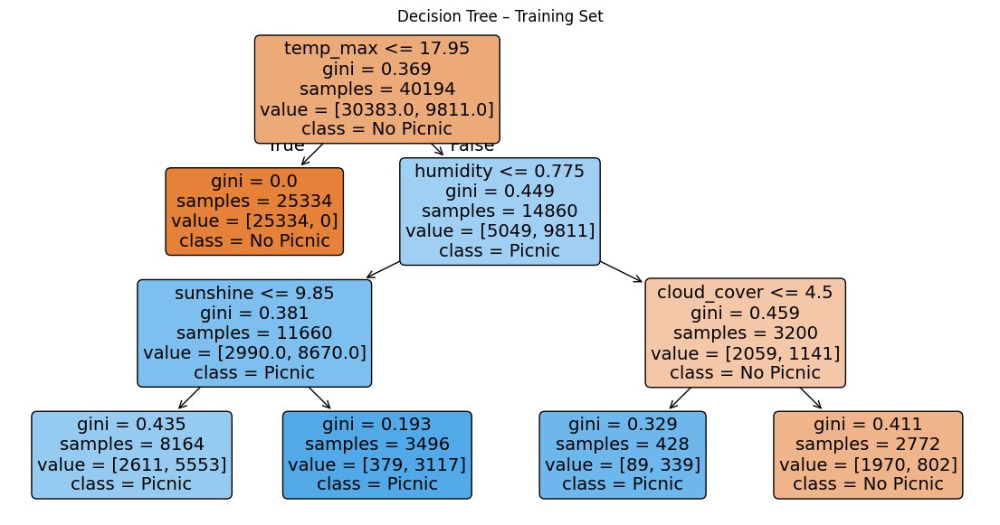

Validation Accuracy: 0.886


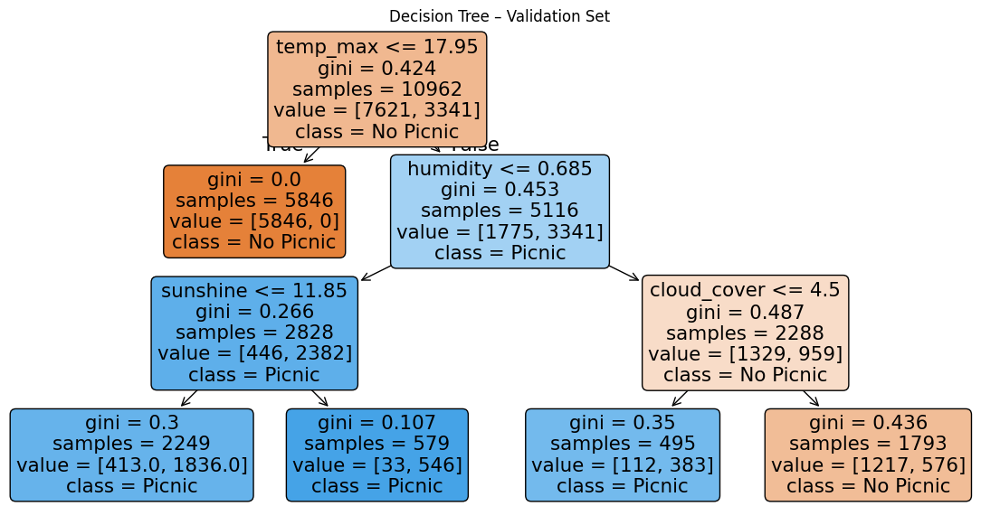

Test Accuracy: 0.902


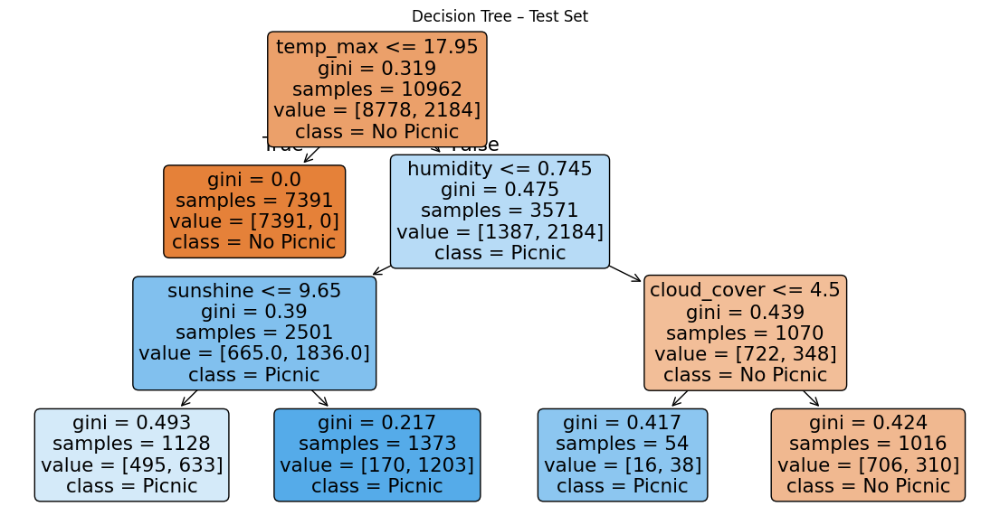

In [ ]:
# Decision tree code
import pandas as pd
import numpy as np
import time
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.impute import SimpleImputer
from sklearn.metrics import accuracy_score
from sklearn.model_selection import validation_curve, learning_curve
import matplotlib.pyplot as plt


# -----------------------------
#  Hyperparameters of the tree
# -----------------------------
MIN_SAMPLES_SPLIT = 10      # Minimum number of samples for split
MAX_DEPTH         = 3       # Maximum tree depth
MAX_FEATURES      = 'sqrt'  # Number of features to consider at each split


# Loading and formatting data
features = pd.read_csv('data/weather_prediction_dataset.csv')
labels   = pd.read_csv('data/weather_prediction_picnic_labels.csv')

feat_long = features.melt(
    id_vars=['DATE','MONTH'], var_name='var', value_name='value'
)
feat_long[['city','feature']] = feat_long['var'].str.split('_', n=1, expand=True)
feat_wide = feat_long.pivot_table(
    index=['DATE','MONTH','city'],
    columns='feature',
    values='value'
).reset_index()

labels_long = labels.melt(
    id_vars=['DATE'], var_name='var', value_name='picnic_possible'
)
labels_long['city'] = labels_long['var'].str.replace('_picnic_weather','',regex=False)
labels_long = labels_long[['DATE','city','picnic_possible']]

data = feat_wide.merge(labels_long, on=['DATE','city'])

# Split cities
non_roma = data[data['city'] != 'ROMA']
roma_df  = data[data['city'] == 'ROMA']

cities = non_roma['city'].unique()
np.random.seed(42)
shuffled = np.random.permutation(cities)

train_cities = shuffled[:11]
val_cities   = shuffled[11:14]
test_cities  = shuffled[14:17]

train_df = non_roma[non_roma['city'].isin(train_cities)].copy()
val_df   = non_roma[non_roma['city'].isin(val_cities)].copy()
test_df  = non_roma[non_roma['city'].isin(test_cities)].copy()

# Convert picnic_possible to integer (0 or 1)
for df in [train_df, val_df, test_df]:
    df['picnic_possible'] = df['picnic_possible'].fillna(False).astype(int)

print("Train cities:", train_cities)
print("Val   cities:", val_cities)
print("Test  cities:", test_cities)

# 3) Prepara X, y e imputer
drop_cols = ['DATE','city','picnic_possible']

X_train = train_df.drop(drop_cols, axis=1); y_train = train_df['picnic_possible']
X_val   = val_df.drop(drop_cols,   axis=1); y_val   = val_df['picnic_possible']
X_test  = test_df.drop(drop_cols,  axis=1); y_test  = test_df['picnic_possible']

imputer = SimpleImputer(strategy='median')
imputer.fit(X_train)

X_train_imp = imputer.transform(X_train)
X_val_imp   = imputer.transform(X_val)
X_test_imp  = imputer.transform(X_test)

# Helper function to train, plot, and return the model
def train_and_plot(X, y, title, feature_names, print_time=False):
    clf = DecisionTreeClassifier(
        random_state=42,
        min_samples_split=MIN_SAMPLES_SPLIT,
        max_depth=MAX_DEPTH,
        max_features=MAX_FEATURES
    )
    if print_time:
        start = time.perf_counter()
        clf.fit(X, y)
        end = time.perf_counter()
        print(f"⏱ Tempo di training ({title}): {end - start:.6f} secondi")
    else:
        clf.fit(X, y)

    plt.figure(figsize=(14,7))
    plot_tree(
        clf,
        feature_names=feature_names,
        class_names=['No Picnic','Picnic'],
        filled=True,
        impurity=True,
        rounded=True
    )
    plt.title(f"Decision Tree – {title}")
    plt.show()
    return clf

# Training set tree
dt_train = train_and_plot(X_train_imp, y_train, title="Training Set", feature_names=X_train.columns, print_time=True)

# Validation set accuracy
y_val_pred = dt_train.predict(X_val_imp)
val_acc    = accuracy_score(y_val, y_val_pred)
print(f"Validation Accuracy: {val_acc:.3f}")

# Validation set tree
dt_val = train_and_plot(X_val_imp, y_val, title="Validation Set", feature_names=X_val.columns)

# Test set accuracy
y_test_pred = dt_train.predict(X_test_imp)
test_acc    = accuracy_score(y_test, y_test_pred)
print(f"Test Accuracy: {test_acc:.3f}")

# Test set tree
dt_test = train_and_plot(X_test_imp, y_test, title="Test Set", feature_names=X_test.columns)



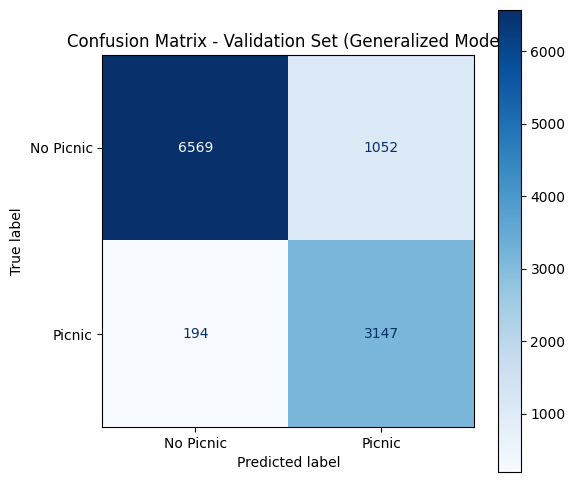

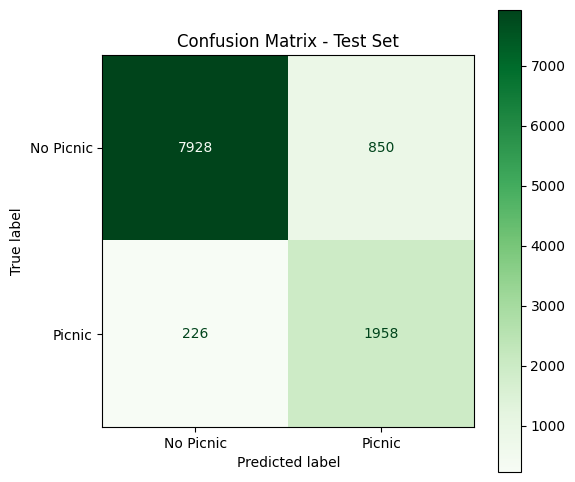

In [ ]:
# Confusion matrix validation and test set
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt



# Confusion matrix for the validation set
cm_val = confusion_matrix(y_val, y_val_pred)
disp_val = ConfusionMatrixDisplay(confusion_matrix=cm_val, display_labels=['No Picnic', 'Picnic'])

fig, ax = plt.subplots(figsize=(6, 6))
disp_val.plot(cmap=plt.cm.Blues, ax=ax)
ax.set_title('Confusion Matrix - Validation Set (Generalized Model)')
plt.show()

# Confusion matrix for the test set
cm_test = confusion_matrix(y_test, y_test_pred)
disp_test = ConfusionMatrixDisplay(confusion_matrix=cm_test, display_labels=['No Picnic', 'Picnic'])

fig, ax = plt.subplots(figsize=(6, 6))
disp_test.plot(cmap=plt.cm.Greens, ax=ax)
ax.set_title('Confusion Matrix - Test Set')
plt.show()

In [ ]:
# Accuracy and AUROC for all the sets
from sklearn.metrics import accuracy_score, roc_auc_score


y_train_pred = dt_train.predict(X_train_imp)
y_val_pred   = dt_train.predict(X_val_imp)
y_test_pred  = dt_train.predict(X_test_imp)


y_train_proba = dt_train.predict_proba(X_train_imp)[:, 1]
y_val_proba   = dt_train.predict_proba(X_val_imp)[:, 1]
y_test_proba  = dt_train.predict_proba(X_test_imp)[:, 1]

# Accuracy
train_acc = accuracy_score(y_train, y_train_pred)
val_acc   = accuracy_score(y_val,   y_val_pred)
test_acc  = accuracy_score(y_test,  y_test_pred)

# AUROC
train_auc = roc_auc_score(y_train, y_train_proba)
val_auc   = roc_auc_score(y_val,   y_val_proba)
test_auc  = roc_auc_score(y_test,  y_test_proba)


print(f"Training  → Accuracy: {train_acc:.3f} | AUROC: {train_auc:.3f}")
print(f"Validation→ Accuracy: {val_acc:.3f} | AUROC: {val_auc:.3f}")
print(f"Test      → Accuracy: {test_acc:.3f} | AUROC: {test_auc:.3f}")


Training  → Accuracy: 0.903 | AUROC: 0.954
Validation→ Accuracy: 0.886 | AUROC: 0.938
Test      → Accuracy: 0.902 | AUROC: 0.961


In [ ]:
# Classification report
from sklearn.metrics import classification_report

# Classification report for the training set
print("Classification Report - Training Set:")
print(classification_report(y_train, y_train_pred))

# Classification report for the validation set
print("Classification Report - Validation Set:")
print(classification_report(y_val, y_val_pred))

# Classification report for the test set
print("Classification Report - Test Set:")
print(classification_report(y_test, y_test_pred))

Classification Report - Training Set:
              precision    recall  f1-score   support

           0       0.97      0.90      0.93     30383
           1       0.75      0.92      0.82      9811

    accuracy                           0.90     40194
   macro avg       0.86      0.91      0.88     40194
weighted avg       0.92      0.90      0.91     40194

Classification Report - Validation Set:
              precision    recall  f1-score   support

           0       0.97      0.86      0.91      7621
           1       0.75      0.94      0.83      3341

    accuracy                           0.89     10962
   macro avg       0.86      0.90      0.87     10962
weighted avg       0.90      0.89      0.89     10962

Classification Report - Test Set:
              precision    recall  f1-score   support

           0       0.97      0.90      0.94      8778
           1       0.70      0.90      0.78      2184

    accuracy                           0.90     10962
   macro avg    

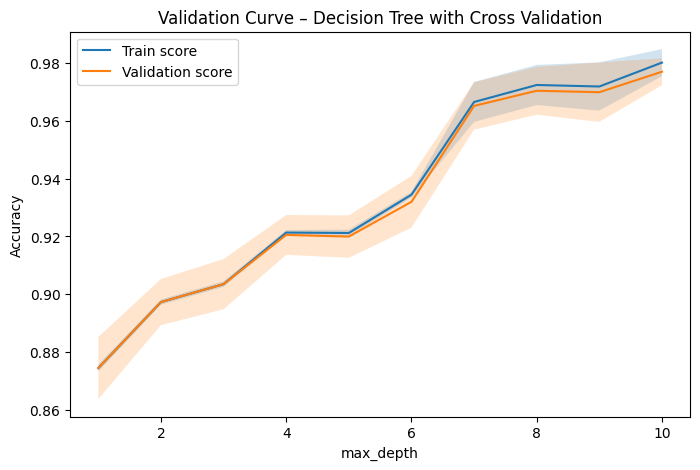

In [ ]:
# Validation curve
from sklearn.model_selection import validation_curve
import numpy as np
import matplotlib.pyplot as plt


param_range = np.arange(1, 11)

train_scores, val_scores = validation_curve(
    DecisionTreeClassifier(
        random_state=42,
        min_samples_split=MIN_SAMPLES_SPLIT,
        max_features=MAX_FEATURES
    ),
    X_train_imp, y_train,
    param_name="max_depth",
    cv=10,
    param_range=param_range,
    scoring="accuracy",
    n_jobs=-1
)

# Calculate means and standard deviations
train_mean = train_scores.mean(axis=1)
train_std  = train_scores.std(axis=1)
val_mean   = val_scores.mean(axis=1)
val_std    = val_scores.std(axis=1)

plt.figure(figsize=(8,5))
plt.plot(param_range, train_mean, label="Train score")
plt.fill_between(param_range, train_mean-train_std, train_mean+train_std, alpha=0.2)
plt.plot(param_range, val_mean, label="Validation score")
plt.fill_between(param_range, val_mean-val_std, val_mean+val_std, alpha=0.2)
plt.xlabel("max_depth")
plt.ylabel("Accuracy")
plt.title("Validation Curve – Decision Tree with Cross Validation")
plt.legend()
plt.show()


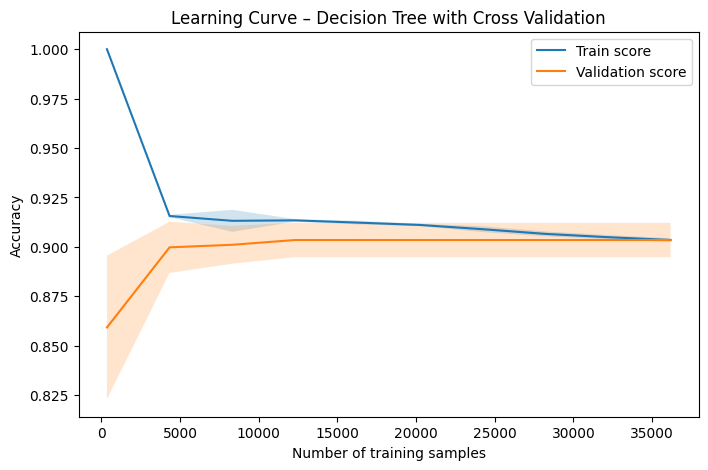

In [ ]:
# Learning curve
from sklearn.model_selection import learning_curve

train_sizes, train_scores, val_scores = learning_curve(
    dt_train,
    X_train_imp, y_train,
    train_sizes=np.linspace(0.01, 1.0, 10),
    cv=10,
    scoring="accuracy",
    n_jobs=-1
)

train_mean = train_scores.mean(axis=1)
train_std  = train_scores.std(axis=1)
val_mean   = val_scores.mean(axis=1)
val_std    = val_scores.std(axis=1)

plt.figure(figsize=(8,5))
plt.plot(train_sizes, train_mean, label="Train score")
plt.fill_between(train_sizes, train_mean-train_std, train_mean+train_std, alpha=0.2)
plt.plot(train_sizes, val_mean, label="Validation score")
plt.fill_between(train_sizes, val_mean-val_std, val_mean+val_std, alpha=0.2)
plt.xlabel("Number of training samples")
plt.ylabel("Accuracy")
plt.title("Learning Curve – Decision Tree with Cross Validation")
plt.legend()
plt.show()


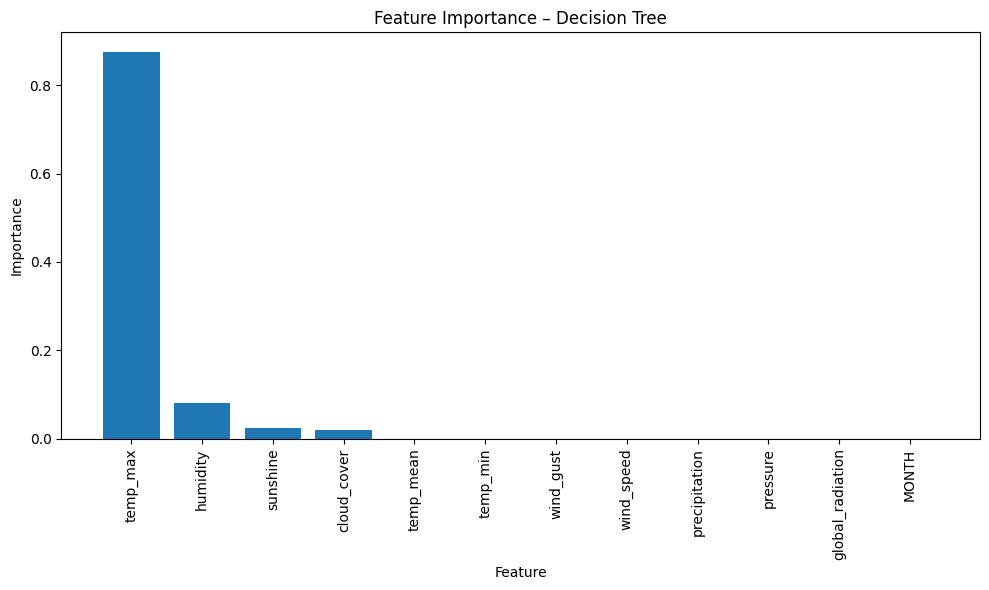

In [ ]:
# Feature Importance
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import joblib


importances = dt_train.feature_importances_
feature_names = X_train.columns


indices = np.argsort(importances)[::-1]

plt.figure(figsize=(10,6))
plt.title("Feature Importance – Decision Tree")
plt.bar(range(len(importances)), importances[indices], align="center")
plt.xticks(range(len(importances)), feature_names[indices], rotation=90)
plt.xlabel("Feature")
plt.ylabel("Importance")
plt.tight_layout()
plt.show()


#RF

Train cities: ['BASEL' 'BUDAPEST' 'HEATHROW' 'STOCKHOLM' 'MUENCHEN' 'SONNBLICK'
 'MAASTRICHT' 'PERPIGNAN' 'DEBILT' 'MALMO' 'TOURS']
Val   cities: ['DUSSELDORF' 'LJUBLJANA' 'MONTELIMAR']
Test  cities: ['OSLO' 'DRESDEN' 'KASSEL']
⏱ Tempo di training Random Forest: 1.446315 secondi
Validation Accuracy: 1.000
Test Accuracy: 1.000


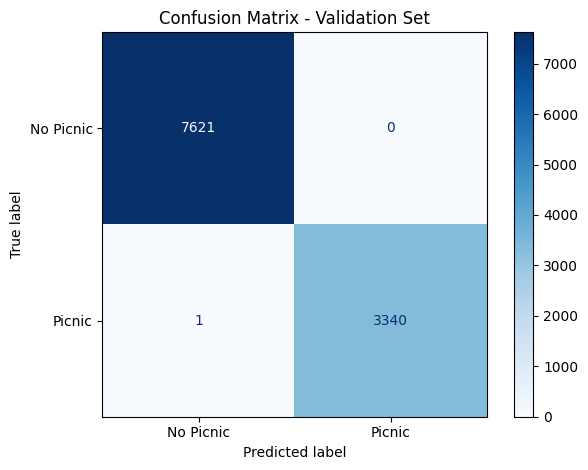

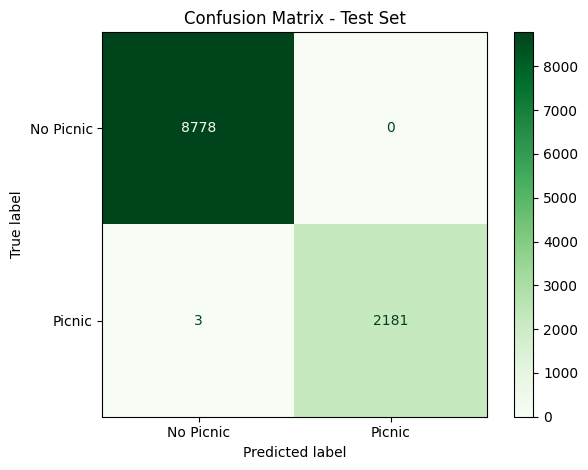

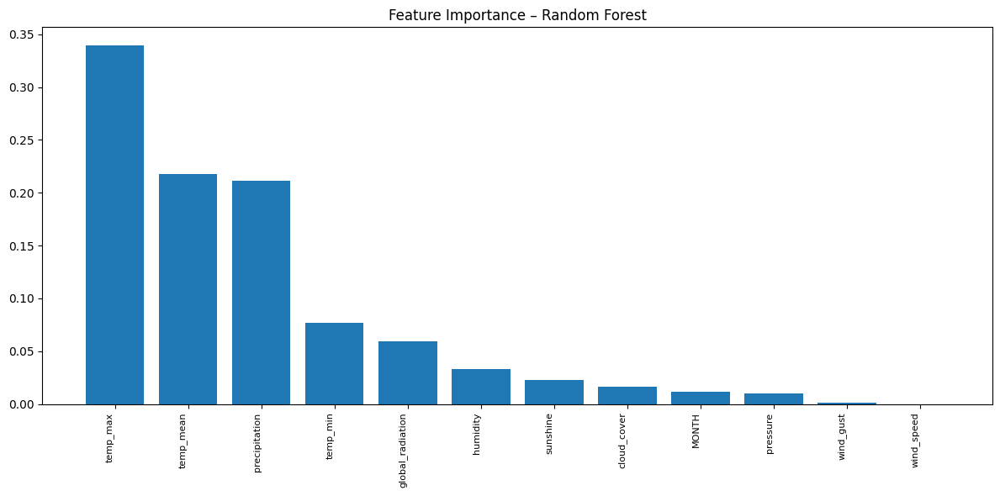

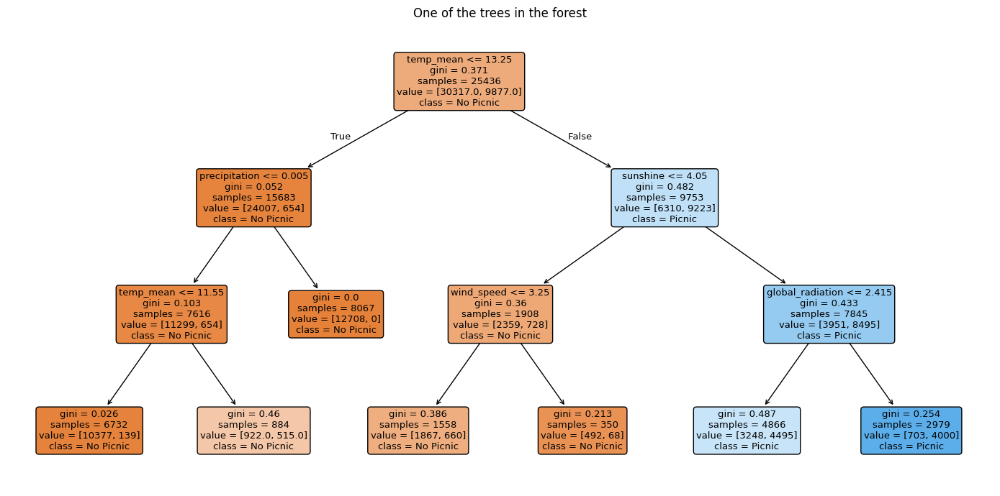

In [ ]:
# Random forest code
import pandas as pd
import numpy as np
import time
import matplotlib.pyplot as plt

from sklearn.impute import SimpleImputer
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, ConfusionMatrixDisplay
from sklearn.model_selection import learning_curve, validation_curve
from sklearn.tree import plot_tree


# -----------------------------
# Hyperparameters Random Forest
# -----------------------------
N_ESTIMATORS      = 100
MAX_DEPTH         = 3
MAX_FEATURES      = "sqrt"
MIN_SAMPLES_SPLIT = 10
BOOTSTRAP         = True
RANDOM_STATE      = 42


# Loading and formatting data
features = pd.read_csv('data/weather_prediction_dataset.csv')
labels   = pd.read_csv('data/weather_prediction_picnic_labels.csv')


feat_long = features.melt(
    id_vars=['DATE','MONTH'], var_name='var', value_name='value'
)
feat_long[['city','feature']] = feat_long['var'].str.split('_', n=1, expand=True)
feat_wide = feat_long.pivot_table(
    index=['DATE','MONTH','city'],
    columns='feature',
    values='value'
).reset_index()

labels_long = labels.melt(
    id_vars=['DATE'], var_name='var', value_name='picnic_possible'
)
labels_long['city'] = labels_long['var'].str.replace('_picnic_weather','',regex=False)
labels_long = labels_long[['DATE','city','picnic_possible']]

data = feat_wide.merge(labels_long, on=['DATE','city'])

# Split cities
non_roma = data[data['city'] != 'ROMA']
roma_df  = data[data['city'] == 'ROMA']

cities = non_roma['city'].unique()
np.random.seed(RANDOM_STATE)
shuffled = np.random.permutation(cities)

train_cities = shuffled[:11]
val_cities   = shuffled[11:14]
test_cities  = shuffled[14:17]

train_df = non_roma[non_roma['city'].isin(train_cities)].copy()
val_df   = non_roma[non_roma['city'].isin(val_cities)].copy()
test_df  = non_roma[non_roma['city'].isin(test_cities)].copy()

# Convert label to integer (0, 1)
for df in (train_df, val_df, test_df):
    df['picnic_possible'] = df['picnic_possible'].fillna(False).astype(int)

print("Train cities:", train_cities)
print("Val   cities:", val_cities)
print("Test  cities:", test_cities)


drop_cols = ['DATE','city','picnic_possible']

X_train = train_df.drop(drop_cols, axis=1); y_train = train_df['picnic_possible']
X_val   = val_df.drop(drop_cols, axis=1);   y_val   = val_df['picnic_possible']
X_test  = test_df.drop(drop_cols, axis=1);  y_test  = test_df['picnic_possible']

imputer = SimpleImputer(strategy='median')
imputer.fit(X_train)

X_train_imp = imputer.transform(X_train)
X_val_imp   = imputer.transform(X_val)
X_test_imp  = imputer.transform(X_test)

# Final RF training with time measurement
rf_clf = RandomForestClassifier(
    n_estimators=N_ESTIMATORS,
    max_depth=MAX_DEPTH,
    max_features=MAX_FEATURES,
    min_samples_split=MIN_SAMPLES_SPLIT,
    bootstrap=BOOTSTRAP,
    oob_score=True,
    n_jobs=-1,
    random_state=RANDOM_STATE
)

start = time.perf_counter()
rf_clf.fit(X_train_imp, y_train)
end = time.perf_counter()
print(f"⏱ Tempo di training Random Forest: {end - start:.6f} secondi")

# Validation set accuracy
y_val_pred = rf_clf.predict(X_val_imp)
print(f"Validation Accuracy: {accuracy_score(y_val, y_val_pred):.3f}")

# Test set accuracy
y_test_pred = rf_clf.predict(X_test_imp)
print(f"Test Accuracy: {accuracy_score(y_test, y_test_pred):.3f}")

# Confusion matrix
ConfusionMatrixDisplay.from_predictions(
    y_val, y_val_pred,
    display_labels=['No Picnic', 'Picnic'],
    cmap="Blues"
)
plt.title("Confusion Matrix - Validation Set")
plt.tight_layout()
plt.show()

ConfusionMatrixDisplay.from_predictions(
    y_test, y_test_pred,
    display_labels=['No Picnic', 'Picnic'],
    cmap="Greens"
)
plt.title("Confusion Matrix - Test Set")
plt.tight_layout()
plt.show()

# Feature Importance
importances = rf_clf.feature_importances_
indices = np.argsort(importances)[::-1]

plt.figure(figsize=(12,6))
plt.bar(range(len(indices)), importances[indices])
plt.xticks(range(len(indices)), X_train.columns[indices], rotation=90, ha='right', fontsize=8)
plt.title("Feature Importance – Random Forest")
plt.tight_layout()
plt.show()

# Display a single tree
plt.figure(figsize=(14,7))
plot_tree(
    rf_clf.estimators_[0],
    feature_names=X_train.columns,
    class_names=['No Picnic', 'Picnic'],
    filled=True, impurity=True, rounded=True
)
plt.title("One of the trees in the forest")
plt.tight_layout()
plt.show()


In [ ]:
# Accuracy and AUROC for all the sets
from sklearn.metrics import accuracy_score, roc_auc_score


y_train_pred  = rf_clf.predict(X_train_imp)
y_val_pred    = rf_clf.predict(X_val_imp)
y_test_pred   = rf_clf.predict(X_test_imp)

y_train_proba = rf_clf.predict_proba(X_train_imp)[:,1]
y_val_proba   = rf_clf.predict_proba(X_val_imp)[:,1]
y_test_proba  = rf_clf.predict_proba(X_test_imp)[:,1]

# Accuracy
train_acc = accuracy_score(y_train, y_train_pred)
val_acc   = accuracy_score(y_val,   y_val_pred)
test_acc  = accuracy_score(y_test,  y_test_pred)

# AUROC
train_auc = roc_auc_score(y_train, y_train_proba)
val_auc   = roc_auc_score(y_val,   y_val_proba)
test_auc  = roc_auc_score(y_test,  y_test_proba)


print(f"Training   → Accuracy: {train_acc:.3f} | AUROC: {train_auc:.3f}")
print(f"Validation → Accuracy: {val_acc:.3f} | AUROC: {val_auc:.3f}")
print(f"Test       → Accuracy: {test_acc:.3f} | AUROC: {test_auc:.3f}")


Training   → Accuracy: 1.000 | AUROC: 1.000
Validation → Accuracy: 1.000 | AUROC: 1.000
Test       → Accuracy: 1.000 | AUROC: 1.000


In [ ]:
# Classification Report
from sklearn.metrics import classification_report

print("Random Forest - Classification Report train:")
print(classification_report(y_train, rf_clf.predict(X_train_imp), target_names=['No Picnic', 'Picnic']))

print("Random Forest - Classification Report (Test):")
print(classification_report(y_test, rf_clf.predict(X_test_imp), target_names=['No Picnic', 'Picnic']))

Random Forest - Classification Report train:
              precision    recall  f1-score   support

   No Picnic       1.00      1.00      1.00     30383
      Picnic       1.00      1.00      1.00      9811

    accuracy                           1.00     40194
   macro avg       1.00      1.00      1.00     40194
weighted avg       1.00      1.00      1.00     40194

Random Forest - Classification Report (Test):
              precision    recall  f1-score   support

   No Picnic       1.00      1.00      1.00      8778
      Picnic       1.00      1.00      1.00      2184

    accuracy                           1.00     10962
   macro avg       1.00      1.00      1.00     10962
weighted avg       1.00      1.00      1.00     10962



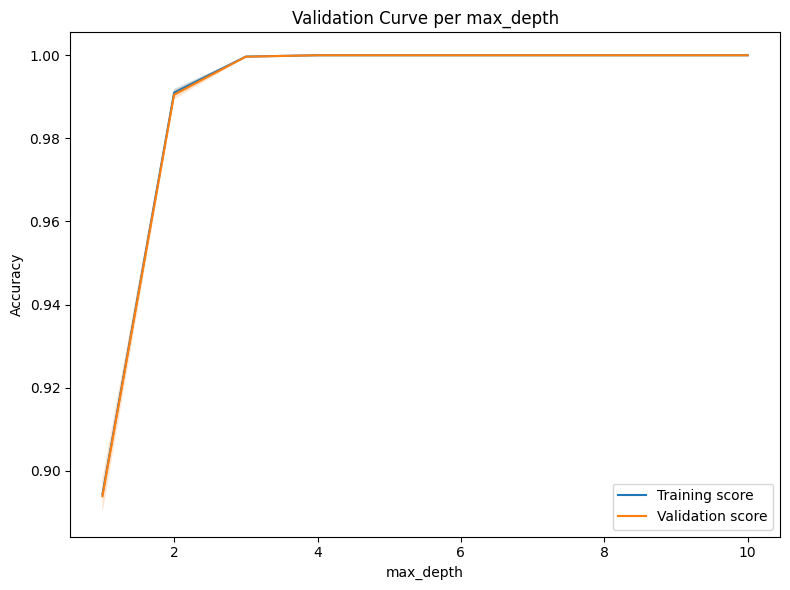

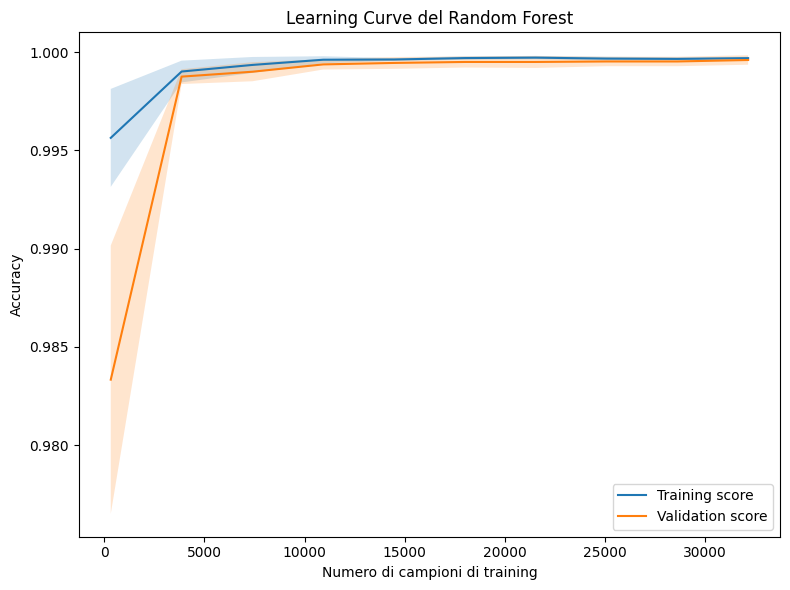

In [ ]:
# Validation Curve max_depth and learning curve
import matplotlib.pyplot as plt
from sklearn.model_selection import validation_curve, learning_curve

# Validation Curve
param_name = "max_depth"
param_range = np.arange(1, 11, 1)

train_scores, val_scores = validation_curve(
    RandomForestClassifier(
        n_estimators=N_ESTIMATORS,
        max_features=MAX_FEATURES,
        min_samples_split=MIN_SAMPLES_SPLIT,
        bootstrap=BOOTSTRAP,
        oob_score=False,
        n_jobs=-1,
        random_state=RANDOM_STATE
    ),
    X_train_imp, y_train,
    param_name=param_name,
    param_range=param_range,
    cv=5,
    scoring="accuracy",
    n_jobs=-1
)

# Calculate means and standard deviations
train_mean = np.mean(train_scores, axis=1)
train_std  = np.std(train_scores,  axis=1)
val_mean   = np.mean(val_scores,  axis=1)
val_std    = np.std(val_scores,   axis=1)

plt.figure(figsize=(8, 6))
plt.plot(param_range, train_mean, label="Training score")
plt.fill_between(param_range, train_mean - train_std, train_mean + train_std, alpha=0.2)
plt.plot(param_range, val_mean,   label="Validation score")
plt.fill_between(param_range, val_mean   - val_std,   val_mean   + val_std,   alpha=0.2)
plt.title("Validation Curve per max_depth")
plt.xlabel("max_depth")
plt.ylabel("Accuracy")
plt.legend(loc="best")
plt.tight_layout()
plt.show()


# Learning Curve

train_sizes = np.linspace(0.01, 1.0, 10)

sizes, train_scores_lc, val_scores_lc = learning_curve(
    rf_clf,
    X_train_imp, y_train,
    train_sizes=train_sizes,
    cv=5,
    scoring="accuracy",
    n_jobs=-1,
    shuffle=True,
    random_state=RANDOM_STATE
)

# Calculate means and standard deviations
train_mean_lc = np.mean(train_scores_lc, axis=1)
train_std_lc  = np.std(train_scores_lc,  axis=1)
val_mean_lc   = np.mean(val_scores_lc,  axis=1)
val_std_lc    = np.std(val_scores_lc,   axis=1)

plt.figure(figsize=(8, 6))
plt.plot(sizes, train_mean_lc, label="Training score")
plt.fill_between(sizes, train_mean_lc - train_std_lc, train_mean_lc + train_std_lc, alpha=0.2)
plt.plot(sizes, val_mean_lc,   label="Validation score")
plt.fill_between(sizes, val_mean_lc   - val_std_lc,   val_mean_lc   + val_std_lc,   alpha=0.2)
plt.title("Learning Curve del Random Forest")
plt.xlabel("Numero di campioni di training")
plt.ylabel("Accuracy")
plt.legend(loc="best")
plt.tight_layout()
plt.show()



#XGBoost

Train cities: ['BASEL' 'BUDAPEST' 'HEATHROW' 'STOCKHOLM' 'MUENCHEN' 'SONNBLICK'
 'MAASTRICHT' 'PERPIGNAN' 'DEBILT' 'MALMO' 'TOURS']
Val   cities: ['DUSSELDORF' 'LJUBLJANA' 'MONTELIMAR']
Test  cities: ['OSLO' 'DRESDEN' 'KASSEL']
⏱ Tempo di training XGBoost: 0.363600 secondi
Validation Accuracy: 1.000
Test Accuracy      : 1.000


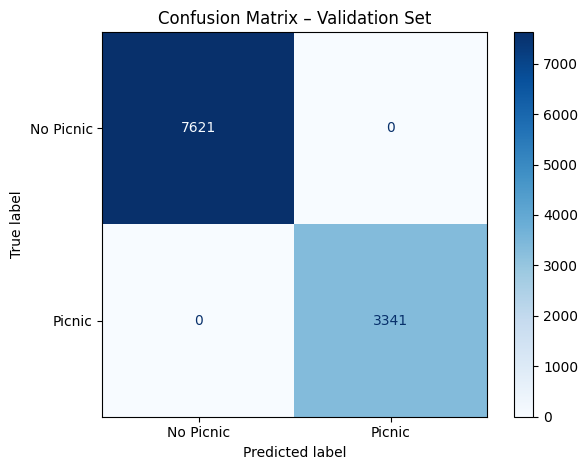

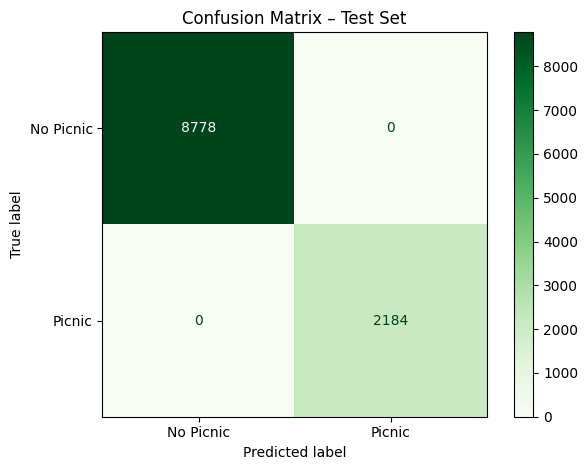

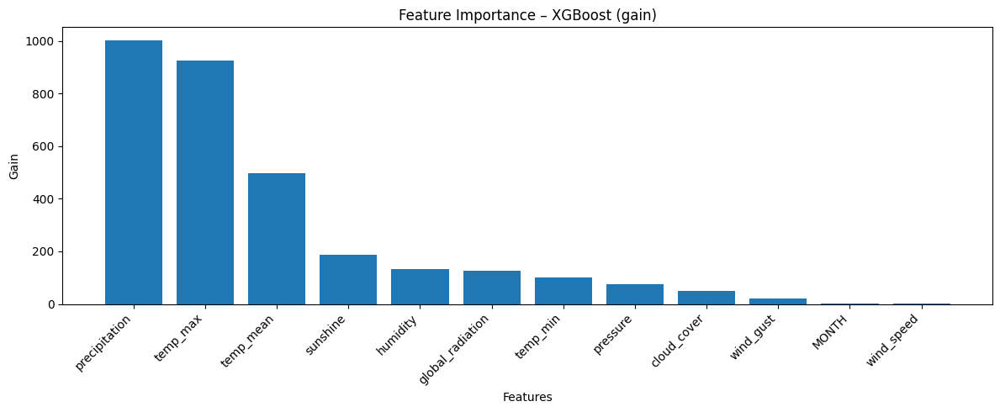

In [ ]:
# XGBoost code
import pandas as pd
import numpy as np
import time
import matplotlib.pyplot as plt

from sklearn.impute import SimpleImputer
from sklearn.metrics import accuracy_score, ConfusionMatrixDisplay
from sklearn.model_selection import learning_curve, validation_curve
from xgboost import XGBClassifier, plot_importance

# -----------------------------
# Hyperparameters XGBoost
# -----------------------------
XGB_PARAMS = {
    "n_estimators": 100,
    "max_depth": 3,
    "learning_rate": 0.10,
    "subsample": 0.80,
    "colsample_bytree": 0.80,
    "random_state": 42,
    "eval_metric": "logloss"
}


# Loading and formatting data
features = pd.read_csv("data/weather_prediction_dataset.csv")
labels   = pd.read_csv("data/weather_prediction_picnic_labels.csv")

feat_long = features.melt(id_vars=["DATE", "MONTH"], var_name="var", value_name="value")
feat_long[["city", "feature"]] = feat_long["var"].str.split("_", n=1, expand=True)
feat_wide = (
    feat_long
    .pivot_table(index=["DATE", "MONTH", "city"], columns="feature", values="value")
    .reset_index()
)

labels_long = labels.melt(id_vars=["DATE"], var_name="var", value_name="picnic_possible")
labels_long["city"] = labels_long["var"].str.replace("_picnic_weather", "", regex=False)
labels_long = labels_long[["DATE", "city", "picnic_possible"]]

data = feat_wide.merge(labels_long, on=["DATE", "city"])


# Split cities
non_roma = data[data["city"] != "ROMA"]
roma_df  = data[data["city"] == "ROMA"]

cities   = non_roma["city"].unique()
np.random.seed(42)
shuffled = np.random.permutation(cities)

train_cities = shuffled[:11]
val_cities   = shuffled[11:14]
test_cities  = shuffled[14:17]

train_df = non_roma[non_roma["city"].isin(train_cities)].copy()
val_df   = non_roma[non_roma["city"].isin(val_cities)].copy()
test_df  = non_roma[non_roma["city"].isin(test_cities)].copy()

for df in (train_df, val_df, test_df):
    df["picnic_possible"] = df["picnic_possible"].fillna(False).astype(int)

print("Train cities:", train_cities)
print("Val   cities:", val_cities)
print("Test  cities:", test_cities)


drop_cols = ["DATE", "city", "picnic_possible"]

X_train = train_df.drop(columns=drop_cols)
y_train = train_df["picnic_possible"]

X_val   = val_df.drop(columns=drop_cols)
y_val   = val_df["picnic_possible"]

X_test  = test_df.drop(columns=drop_cols)
y_test  = test_df["picnic_possible"]


X_train_imp = pd.DataFrame(imputer.transform(X_train), columns=X_train.columns)
X_val_imp   = pd.DataFrame(imputer.transform(X_val), columns=X_val.columns)
X_test_imp  = pd.DataFrame(imputer.transform(X_test), columns=X_test.columns)


# XGBoost training with time measurement
xgb_clf = XGBClassifier(**XGB_PARAMS)

start = time.perf_counter()
xgb_clf.fit(X_train_imp, y_train)
end = time.perf_counter()
print(f"⏱ Tempo di training XGBoost: {end - start:.6f} secondi")


# Validation and test accuracy
y_val_pred  = xgb_clf.predict(X_val_imp)
y_test_pred = xgb_clf.predict(X_test_imp)

print(f"Validation Accuracy: {accuracy_score(y_val, y_val_pred):.3f}")
print(f"Test Accuracy      : {accuracy_score(y_test, y_test_pred):.3f}")

# Confusion matrix
ConfusionMatrixDisplay.from_predictions(y_val, y_val_pred, display_labels=["No Picnic","Picnic"], cmap="Blues")
plt.title("Confusion Matrix – Validation Set")
plt.tight_layout(); plt.show()

ConfusionMatrixDisplay.from_predictions(y_test, y_test_pred, display_labels=["No Picnic","Picnic"], cmap="Greens")
plt.title("Confusion Matrix – Test Set")
plt.tight_layout(); plt.show()


# Feature importance
importances = xgb_clf.get_booster().get_score(importance_type="gain")
sorted_importances = sorted(importances.items(), key=lambda x: x[1], reverse=True)[:20]
features_names, scores = zip(*sorted_importances)

plt.figure(figsize=(12, 5))
plt.bar(range(len(scores)), scores, tick_label=features_names)
plt.xticks(rotation=45, ha='right')
plt.title("Feature Importance – XGBoost (gain)")
plt.xlabel("Features")
plt.ylabel("Gain")
plt.grid(False)
plt.tight_layout()
plt.show()



In [ ]:
# Accuracy and AUROC for all the sets
from sklearn.metrics import accuracy_score, roc_auc_score


y_train_pred  = xgb_clf.predict(X_train_imp)
y_val_pred    = xgb_clf.predict(X_val_imp)
y_test_pred   = xgb_clf.predict(X_test_imp)

y_train_proba = xgb_clf.predict_proba(X_train_imp)[:, 1]
y_val_proba   = xgb_clf.predict_proba(X_val_imp)[:, 1]
y_test_proba  = xgb_clf.predict_proba(X_test_imp)[:, 1]

# Accuracy
train_acc = accuracy_score(y_train, y_train_pred)
val_acc   = accuracy_score(y_val,   y_val_pred)
test_acc  = accuracy_score(y_test,  y_test_pred)

# AUROC
train_auc = roc_auc_score(y_train, y_train_proba)
val_auc   = roc_auc_score(y_val,   y_val_proba)
test_auc  = roc_auc_score(y_test,  y_test_proba)


print(f"Training   → Accuracy: {train_acc:.3f} | AUROC: {train_auc:.3f}")
print(f"Validation → Accuracy: {val_acc:.3f} | AUROC: {val_auc:.3f}")
print(f"Test       → Accuracy: {test_acc:.3f} | AUROC: {test_auc:.3f}")


Training   → Accuracy: 1.000 | AUROC: 1.000
Validation → Accuracy: 1.000 | AUROC: 1.000
Test       → Accuracy: 1.000 | AUROC: 1.000


In [ ]:
# Classification Report
from sklearn.metrics import classification_report

print("Classification Report – Traininh Set (XGBoost):")
print(classification_report(y_train, y_train_pred, target_names=["No Picnic", "Picnic"]))

print("Classification Report – Validation Set (XGBoost):")
print(classification_report(y_val, y_val_pred, target_names=["No Picnic", "Picnic"]))

print("\nClassification Report – Test Set (XGBoost):")
print(classification_report(y_test, y_test_pred, target_names=["No Picnic", "Picnic"]))

Classification Report – Traininh Set (XGBoost):
              precision    recall  f1-score   support

   No Picnic       1.00      1.00      1.00     30383
      Picnic       1.00      1.00      1.00      9811

    accuracy                           1.00     40194
   macro avg       1.00      1.00      1.00     40194
weighted avg       1.00      1.00      1.00     40194

Classification Report – Validation Set (XGBoost):
              precision    recall  f1-score   support

   No Picnic       1.00      1.00      1.00      7621
      Picnic       1.00      1.00      1.00      3341

    accuracy                           1.00     10962
   macro avg       1.00      1.00      1.00     10962
weighted avg       1.00      1.00      1.00     10962


Classification Report – Test Set (XGBoost):
              precision    recall  f1-score   support

   No Picnic       1.00      1.00      1.00      8778
      Picnic       1.00      1.00      1.00      2184

    accuracy                           

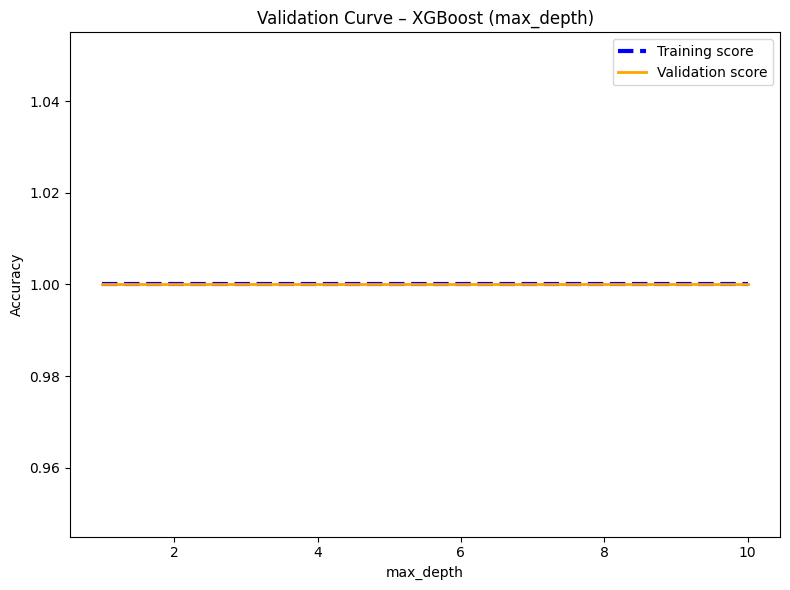

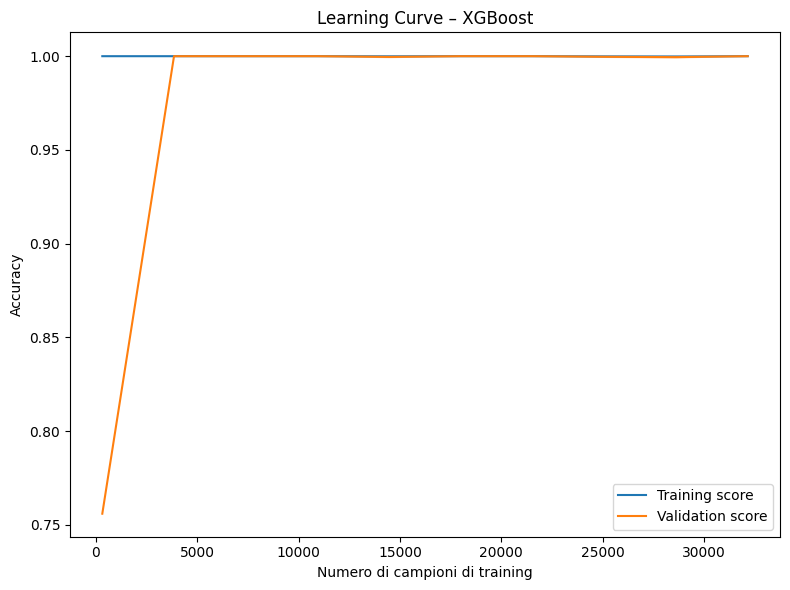

In [ ]:
# Validation and learning curve
import matplotlib.pyplot as plt
from sklearn.model_selection import validation_curve, learning_curve


# Validation Curve max_depth

param_range = np.arange(1, 11, 1)


train_scores, val_scores = validation_curve(
    XGBClassifier(**XGB_PARAMS),
    X_train_imp, y_train,
    param_name="max_depth",
    param_range=param_range,
    cv=5,
    scoring="accuracy",
    n_jobs=-1
)

# Calculate means and standard deviations
train_mean = np.mean(train_scores, axis=1)
train_std  = np.std(train_scores, axis=1)
val_mean   = np.mean(val_scores, axis=1)
val_std    = np.std(val_scores, axis=1)


plt.figure(figsize=(8, 6))
plt.plot(param_range, train_mean, label="Training score", color="blue", linestyle="--", linewidth=3)
plt.fill_between(param_range, train_mean - train_std, train_mean + train_std, alpha=0.2)


plt.plot(param_range, val_mean, label="Validation score", color="orange", linestyle="-", linewidth=2)



plt.fill_between(param_range, val_mean - val_std, val_mean + val_std, alpha=0.2)
plt.title("Validation Curve – XGBoost (max_depth)")
plt.xlabel("max_depth")
plt.ylabel("Accuracy")
plt.legend(loc="best")
plt.tight_layout()
plt.show()



# Learning Curve



train_sizes = np.linspace(0.01, 1.0, 10)

train_sizes_abs, train_scores_lc, val_scores_lc = learning_curve(
    XGBClassifier(**XGB_PARAMS),
    X_train_imp, y_train,
    train_sizes=train_sizes,
    cv=5,
    scoring="accuracy",
    n_jobs=-1
)

# Calculate means and standard deviations
train_mean_lc = np.mean(train_scores_lc, axis=1)
train_std_lc  = np.std(train_scores_lc, axis=1)
val_mean_lc   = np.mean(val_scores_lc, axis=1)
val_std_lc    = np.std(val_scores_lc, axis=1)


plt.figure(figsize=(8, 6))
plt.plot(train_sizes_abs, train_mean_lc, label="Training score")
plt.fill_between(train_sizes_abs,
                 train_mean_lc - train_std_lc,
                 train_mean_lc + train_std_lc,
                 alpha=0.2)
plt.plot(train_sizes_abs, val_mean_lc, label="Validation score")
plt.fill_between(train_sizes_abs,
                 val_mean_lc - val_std_lc,
                 val_mean_lc + val_std_lc,
                 alpha=0.2)
plt.title("Learning Curve – XGBoost")
plt.xlabel("Numero di campioni di training")
plt.ylabel("Accuracy")
plt.legend(loc="best")
plt.tight_layout()
plt.show()


#k-NN

Train cities: ['BASEL' 'BUDAPEST' 'HEATHROW' 'STOCKHOLM' 'MUENCHEN' 'SONNBLICK'
 'MAASTRICHT' 'PERPIGNAN' 'DEBILT' 'MALMO' 'TOURS']
Val   cities: ['DUSSELDORF' 'LJUBLJANA' 'MONTELIMAR']
Test  cities: ['OSLO' 'DRESDEN' 'KASSEL']
⏱ Tempo di training KNN: 0.088968 secondi
Validation Accuracy: 0.908
Test Accuracy      : 0.924


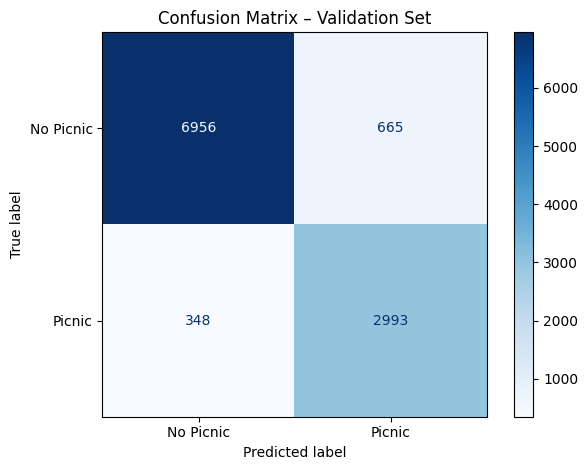

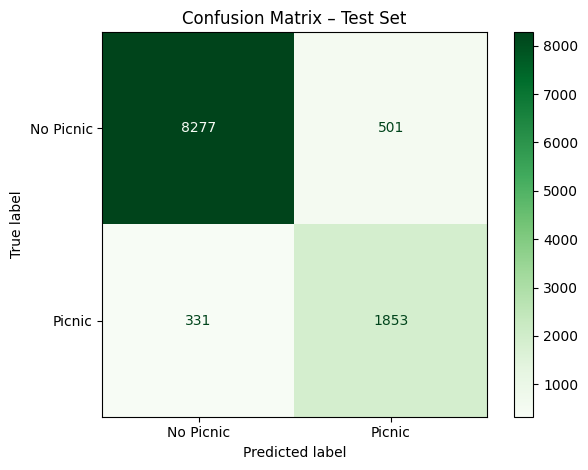

In [ ]:
# K-NN code
import pandas as pd
import numpy as np
import time
import matplotlib.pyplot as plt

from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, ConfusionMatrixDisplay
from sklearn.model_selection import learning_curve, validation_curve
from sklearn.neighbors import KNeighborsClassifier

# -----------------------------
# Hyperparameters KNN
# -----------------------------
KNN_PARAMS = {
    "n_neighbors": 9,
    "weights": "uniform",  # or 'distance'
    "metric": "minkowski",
    "p": 2  # Euclidean distance
}

# Loading and formatting data
features = pd.read_csv("data/weather_prediction_dataset.csv")
labels   = pd.read_csv("data/weather_prediction_picnic_labels.csv")

feat_long = features.melt(id_vars=["DATE", "MONTH"], var_name="var", value_name="value")
feat_long[["city", "feature"]] = feat_long["var"].str.split("_", n=1, expand=True)
feat_wide = (
    feat_long
    .pivot_table(index=["DATE", "MONTH", "city"], columns="feature", values="value")
    .reset_index()
)

labels_long = labels.melt(id_vars=["DATE"], var_name="var", value_name="picnic_possible")
labels_long["city"] = labels_long["var"].str.replace("_picnic_weather", "", regex=False)
labels_long = labels_long[["DATE", "city", "picnic_possible"]]

data = feat_wide.merge(labels_long, on=["DATE", "city"])


# Split cities
non_roma = data[data["city"] != "ROMA"]
roma_df  = data[data["city"] == "ROMA"]

cities   = non_roma["city"].unique()
np.random.seed(42)
shuffled = np.random.permutation(cities)

train_cities = shuffled[:11]
val_cities   = shuffled[11:14]
test_cities  = shuffled[14:17]

train_df = non_roma[non_roma["city"].isin(train_cities)].copy()
val_df   = non_roma[non_roma["city"].isin(val_cities)].copy()
test_df  = non_roma[non_roma["city"].isin(test_cities)].copy()

for df in (train_df, val_df, test_df):
    df["picnic_possible"] = df["picnic_possible"].fillna(False).astype(int)

print("Train cities:", train_cities)
print("Val   cities:", val_cities)
print("Test  cities:", test_cities)


drop_cols = ["DATE", "city", "picnic_possible"]

X_train = train_df.drop(columns=drop_cols)
y_train = train_df["picnic_possible"]

X_val   = val_df.drop(columns=drop_cols)
y_val   = val_df["picnic_possible"]

X_test  = test_df.drop(columns=drop_cols)
y_test  = test_df["picnic_possible"]



X_train_imp = pd.DataFrame(imputer.transform(X_train), columns=X_train.columns, index=X_train.index)
X_val_imp   = pd.DataFrame(imputer.transform(X_val),   columns=X_val.columns,   index=X_val.index)
X_test_imp  = pd.DataFrame(imputer.transform(X_test),  columns=X_test.columns,  index=X_test.index)


# Standardization of the features
scaler = StandardScaler().fit(X_train_imp)

X_train_std = pd.DataFrame(scaler.transform(X_train_imp), columns=X_train_imp.columns, index=X_train_imp.index)
X_val_std   = pd.DataFrame(scaler.transform(X_val_imp),   columns=X_val_imp.columns,   index=X_val_imp.index)
X_test_std  = pd.DataFrame(scaler.transform(X_test_imp),  columns=X_test_imp.columns,  index=X_test_imp.index)


# K-NN training with time measurement
knn_clf = KNeighborsClassifier(**KNN_PARAMS)

start = time.perf_counter()
knn_clf.fit(X_train_std, y_train)
end = time.perf_counter()
print(f"⏱ Tempo di training KNN: {end - start:.6f} secondi")

# Accuracy
y_val_pred  = knn_clf.predict(X_val_std)
y_test_pred = knn_clf.predict(X_test_std)

print(f"Validation Accuracy: {accuracy_score(y_val, y_val_pred):.3f}")
print(f"Test Accuracy      : {accuracy_score(y_test, y_test_pred):.3f}")

# Confusion matrix
ConfusionMatrixDisplay.from_predictions(y_val, y_val_pred, display_labels=["No Picnic","Picnic"], cmap="Blues")
plt.title("Confusion Matrix – Validation Set")
plt.tight_layout(); plt.show()

ConfusionMatrixDisplay.from_predictions(y_test, y_test_pred, display_labels=["No Picnic","Picnic"], cmap="Greens")
plt.title("Confusion Matrix – Test Set")
plt.tight_layout(); plt.show()


In [ ]:
# Accuracy and AUROC for all the sets
from sklearn.metrics import accuracy_score, roc_auc_score


knn_clf = KNeighborsClassifier(**KNN_PARAMS)
knn_clf.fit(X_train_std, y_train)


y_train_pred = knn_clf.predict(X_train_std)
y_val_pred   = knn_clf.predict(X_val_std)
y_test_pred  = knn_clf.predict(X_test_std)


y_train_proba = knn_clf.predict_proba(X_train_std)[:, 1]
y_val_proba   = knn_clf.predict_proba(X_val_std)[:, 1]
y_test_proba  = knn_clf.predict_proba(X_test_std)[:, 1]

# Accuracy
acc_train = accuracy_score(y_train, y_train_pred)
acc_val   = accuracy_score(y_val,   y_val_pred)
acc_test  = accuracy_score(y_test,  y_test_pred)

# AUROC
auroc_train = roc_auc_score(y_train, y_train_proba)
auroc_val   = roc_auc_score(y_val,   y_val_proba)
auroc_test  = roc_auc_score(y_test,  y_test_proba)


print(f"Train   — Accuracy: {acc_train:.3f} | AUROC: {auroc_train:.3f}")
print(f"Val     — Accuracy: {acc_val:.3f}   | AUROC: {auroc_val:.3f}")
print(f"Test    — Accuracy: {acc_test:.3f}  | AUROC: {auroc_test:.3f}")



Train   — Accuracy: 0.943 | AUROC: 0.986
Val     — Accuracy: 0.908   | AUROC: 0.964
Test    — Accuracy: 0.924  | AUROC: 0.970


In [ ]:
# Classification Report
from sklearn.metrics import classification_report

y_val_pred  = knn_clf.predict(X_val_std)
y_test_pred = knn_clf.predict(X_test_std)

y_train_pred = knn_clf.predict(X_train_std)

print("Classification Report – Training Set (KNN):")
print(classification_report(y_train, y_train_pred, target_names=["No Picnic", "Picnic"]))

print("Classification Report – Validation Set (KNN):")
print(classification_report(y_val,   y_val_pred,   target_names=["No Picnic", "Picnic"]))

print("Classification Report – Test Set (KNN):")
print(classification_report(y_test,  y_test_pred,  target_names=["No Picnic", "Picnic"]))


Classification Report – Training Set (KNN):
              precision    recall  f1-score   support

   No Picnic       0.97      0.95      0.96     30383
      Picnic       0.86      0.91      0.89      9811

    accuracy                           0.94     40194
   macro avg       0.92      0.93      0.92     40194
weighted avg       0.94      0.94      0.94     40194

Classification Report – Validation Set (KNN):
              precision    recall  f1-score   support

   No Picnic       0.95      0.91      0.93      7621
      Picnic       0.82      0.90      0.86      3341

    accuracy                           0.91     10962
   macro avg       0.89      0.90      0.89     10962
weighted avg       0.91      0.91      0.91     10962

Classification Report – Test Set (KNN):
              precision    recall  f1-score   support

   No Picnic       0.96      0.94      0.95      8778
      Picnic       0.79      0.85      0.82      2184

    accuracy                           0.92     1096

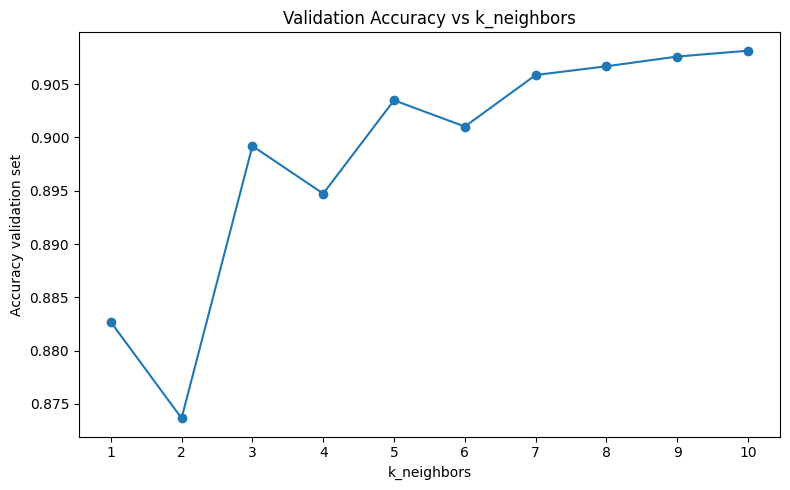

In [ ]:
# Validation Accuracy vs k_neighbors
import matplotlib.pyplot as plt
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score


k_values = list(range(1, 11))
val_accuracies = []

for k in k_values:
    knn_k = KNeighborsClassifier(
        n_neighbors=k,
        weights=KNN_PARAMS["weights"],
        metric=KNN_PARAMS["metric"],
        p=KNN_PARAMS["p"]
    )

    knn_k.fit(X_train_std, y_train)
    y_val_pred_k = knn_k.predict(X_val_std)
    val_accuracies.append(accuracy_score(y_val, y_val_pred_k))


plt.figure(figsize=(8, 5))
plt.plot(k_values, val_accuracies, marker='o')
plt.title("Validation Accuracy vs k_neighbors")
plt.xlabel("k_neighbors")
plt.ylabel("Accuracy validation set")
plt.xticks(k_values)
plt.tight_layout()
plt.show()


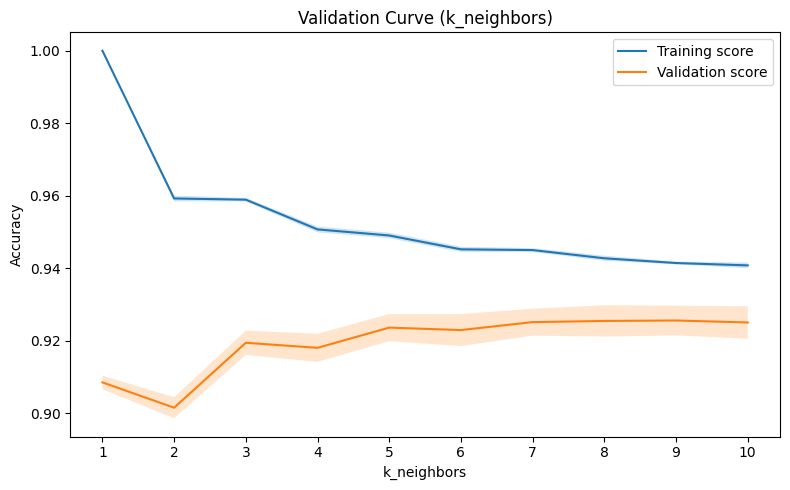

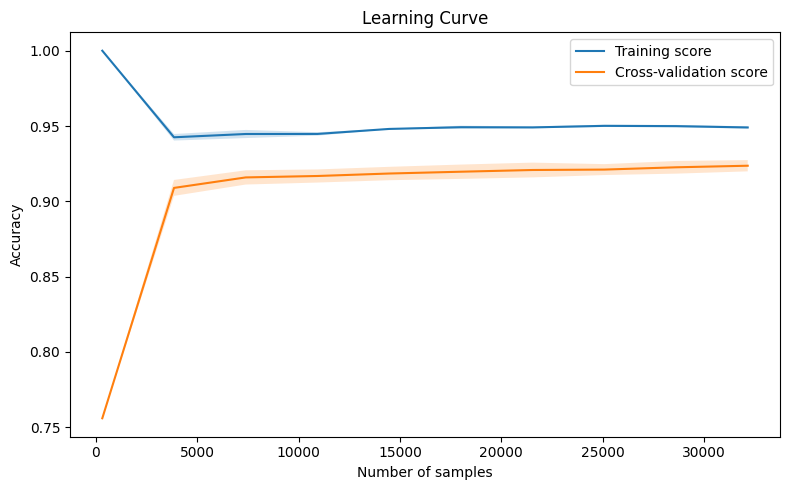

In [ ]:
# Validation and learnigin curve
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import validation_curve, learning_curve
from sklearn.neighbors import KNeighborsClassifier

# 1) Validation Curve n_neighbors
base_clf = KNeighborsClassifier(
    weights=KNN_PARAMS["weights"],
    metric=KNN_PARAMS["metric"],
    p=KNN_PARAMS["p"]
)


param_range = [1, 2, 3, 4, 5, 6, 7, 8, 9, 10]
train_scores, val_scores = validation_curve(
    base_clf,
    X_train_std, y_train,
    param_name="n_neighbors",
    param_range=param_range,
    cv=5,
    scoring="accuracy",
    n_jobs=-1
)

train_mean = np.mean(train_scores, axis=1)
train_std  = np.std (train_scores, axis=1)
val_mean   = np.mean(val_scores, axis=1)
val_std    = np.std (val_scores, axis=1)

plt.figure(figsize=(8, 5))
plt.plot(param_range, train_mean,       label="Training score")
plt.fill_between(param_range,
                 train_mean - train_std,
                 train_mean + train_std,
                 alpha=0.2)
plt.plot(param_range, val_mean,         label="Validation score")
plt.fill_between(param_range,
                 val_mean - val_std,
                 val_mean + val_std,
                 alpha=0.2)
plt.title("Validation Curve (k_neighbors)")
plt.xlabel("k_neighbors")
plt.ylabel("Accuracy")
plt.xticks(param_range)
plt.legend(loc="best")
plt.tight_layout()
plt.show()


# Learning Curve

train_sizes, train_scores_lc, val_scores_lc = learning_curve(
    base_clf,
    X_train_std, y_train,
    train_sizes=np.linspace(0.01, 1.0, 10),
    cv=5,
    scoring="accuracy",
    n_jobs=-1
)

train_mean_lc = np.mean(train_scores_lc, axis=1)
train_std_lc  = np.std (train_scores_lc, axis=1)
val_mean_lc   = np.mean(val_scores_lc, axis=1)
val_std_lc    = np.std (val_scores_lc, axis=1)

plt.figure(figsize=(8, 5))
plt.plot(train_sizes, train_mean_lc,       label="Training score")
plt.fill_between(train_sizes,
                 train_mean_lc - train_std_lc,
                 train_mean_lc + train_std_lc,
                 alpha=0.2)
plt.plot(train_sizes, val_mean_lc,         label="Cross‐validation score")
plt.fill_between(train_sizes,
                 val_mean_lc - val_std_lc,
                 val_mean_lc + val_std_lc,
                 alpha=0.2)
plt.title("Learning Curve")
plt.xlabel("Number of samples")
plt.ylabel("Accuracy")
plt.legend(loc="best")
plt.tight_layout()
plt.show()


# knn with pca

Numero di componenti PCA selezionate: 9


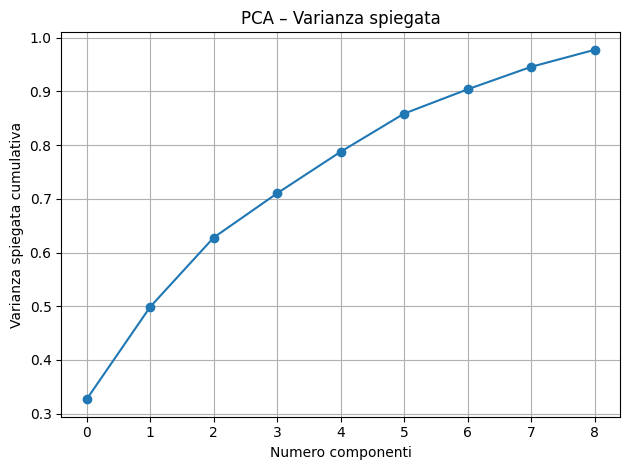

⏱ Tempo di training KNN con PCA: 0.124496 secondi
Validation Accuracy: 0.906
Test Accuracy      : 0.925


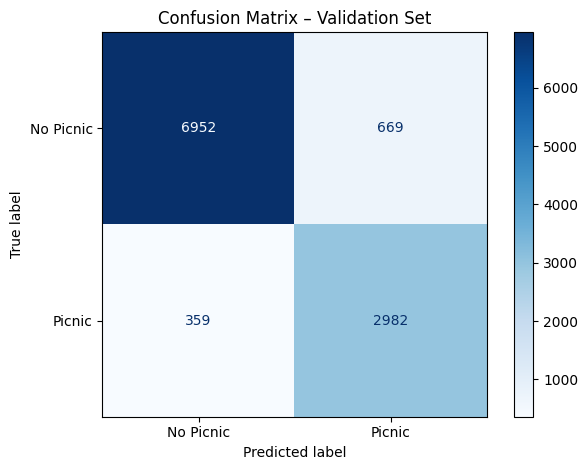

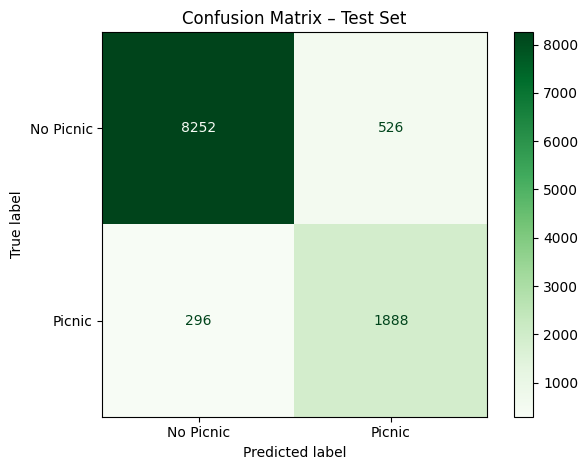

In [ ]:
import pandas as pd
import numpy as np
import time
import matplotlib.pyplot as plt

from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.metrics import accuracy_score, ConfusionMatrixDisplay
from sklearn.neighbors import KNeighborsClassifier

# -----------------------------
# Hyperparameters KNN
# -----------------------------
KNN_PARAMS = {
    "n_neighbors": 9,
    "weights": "uniform",
    "metric": "minkowski",
    "p": 2
}

# -----------------------------
# Hyperparameters PCA
# -----------------------------
# Qui scegliamo di mantenere il 95% della varianza
PCA_VARIANCE = 0.95

# -----------------------------
# Caricamento e preprocessing dati
# -----------------------------
features = pd.read_csv("data/weather_prediction_dataset.csv")
labels   = pd.read_csv("data/weather_prediction_picnic_labels.csv")

# ... (stessa procedura di melt/pivot e split per città) ...

# Impostazione del dataset
drop_cols = ["DATE", "city", "picnic_possible"]
X_train = train_df.drop(columns=drop_cols)
y_train = train_df["picnic_possible"]
X_val   = val_df.drop(columns=drop_cols)
y_val   = val_df["picnic_possible"]
X_test  = test_df.drop(columns=drop_cols)
y_test  = test_df["picnic_possible"]

# Imputazione
imputer = SimpleImputer(strategy="mean").fit(X_train)
X_train_imp = pd.DataFrame(imputer.transform(X_train), columns=X_train.columns, index=X_train.index)
X_val_imp   = pd.DataFrame(imputer.transform(X_val),   columns=X_val.columns,   index=X_val.index)
X_test_imp  = pd.DataFrame(imputer.transform(X_test),  columns=X_test.columns,  index=X_test.index)

# Standardizzazione
scaler = StandardScaler().fit(X_train_imp)
X_train_std = pd.DataFrame(scaler.transform(X_train_imp), columns=X_train_imp.columns, index=X_train_imp.index)
X_val_std   = pd.DataFrame(scaler.transform(X_val_imp),   columns=X_val_imp.columns,   index=X_val_imp.index)
X_test_std  = pd.DataFrame(scaler.transform(X_test_imp),  columns=X_test_imp.columns,  index=X_test_imp.index)

# -----------------------------
# PCA
# -----------------------------
pca = PCA(n_components=PCA_VARIANCE, svd_solver="full").fit(X_train_std)
print(f"Numero di componenti PCA selezionate: {pca.n_components_}")

X_train_pca = pca.transform(X_train_std)
X_val_pca   = pca.transform(X_val_std)
X_test_pca  = pca.transform(X_test_std)

# Facoltativo: visualizzazione della varianza spiegata cumulativa
plt.figure()
plt.plot(np.cumsum(pca.explained_variance_ratio_), marker='o')
plt.xlabel("Numero componenti")
plt.ylabel("Varianza spiegata cumulativa")
plt.title("PCA – Varianza spiegata")
plt.grid(True)
plt.tight_layout()
plt.show()

# -----------------------------
# K-NN training con PCA
# -----------------------------
knn_clf = KNeighborsClassifier(**KNN_PARAMS)

start = time.perf_counter()
knn_clf.fit(X_train_pca, y_train)
end = time.perf_counter()
print(f"⏱ Tempo di training KNN con PCA: {end - start:.6f} secondi")

# Valutazione
y_val_pred  = knn_clf.predict(X_val_pca)
y_test_pred = knn_clf.predict(X_test_pca)

print(f"Validation Accuracy: {accuracy_score(y_val, y_val_pred):.3f}")
print(f"Test Accuracy      : {accuracy_score(y_test, y_test_pred):.3f}")

# Matrici di confusione
ConfusionMatrixDisplay.from_predictions(y_val, y_val_pred,
                                        display_labels=["No Picnic","Picnic"],
                                        cmap="Blues")
plt.title("Confusion Matrix – Validation Set")
plt.tight_layout(); plt.show()

ConfusionMatrixDisplay.from_predictions(y_test, y_test_pred,
                                        display_labels=["No Picnic","Picnic"],
                                        cmap="Greens")
plt.title("Confusion Matrix – Test Set")
plt.tight_layout(); plt.show()


#Neural Network ReLu

Train cities: ['BASEL' 'BUDAPEST' 'HEATHROW' 'STOCKHOLM' 'MUENCHEN' 'SONNBLICK'
 'MAASTRICHT' 'PERPIGNAN' 'DEBILT' 'MALMO' 'TOURS']
Val   cities: ['DUSSELDORF' 'LJUBLJANA' 'MONTELIMAR']
Test  cities: ['OSLO' 'DRESDEN' 'KASSEL']
Epoch 1/100
2513/2513 - 7s - 3ms/step - accuracy: 0.8885 - loss: 0.2571 - mae: 0.1733 - mse: 0.0805 - val_accuracy: 0.9238 - val_loss: 0.1808 - val_mae: 0.1248 - val_mse: 0.0555
Epoch 2/100
2513/2513 - 9s - 4ms/step - accuracy: 0.9385 - loss: 0.1606 - mae: 0.1060 - mse: 0.0475 - val_accuracy: 0.9446 - val_loss: 0.1413 - val_mae: 0.0986 - val_mse: 0.0420
Epoch 3/100
2513/2513 - 17s - 7ms/step - accuracy: 0.9489 - loss: 0.1334 - mae: 0.0883 - mse: 0.0392 - val_accuracy: 0.9523 - val_loss: 0.1207 - val_mae: 0.0844 - val_mse: 0.0353
Epoch 4/100
2513/2513 - 11s - 4ms/step - accuracy: 0.9583 - loss: 0.1154 - mae: 0.0767 - mse: 0.0332 - val_accuracy: 0.9585 - val_loss: 0.1063 - val_mae: 0.0725 - val_mse: 0.0310
Epoch 5/100
2513/2513 - 5s - 2ms/step - accuracy: 0.9639 -

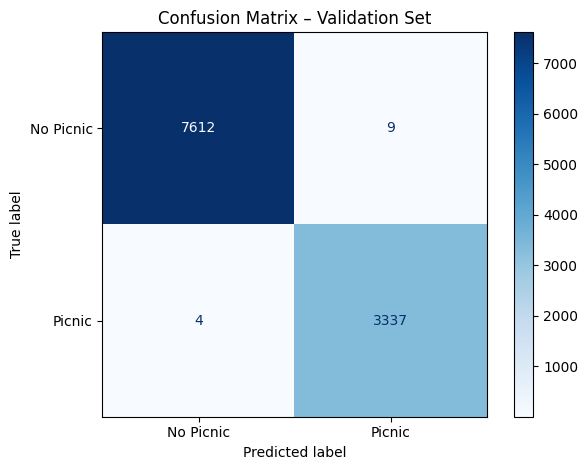

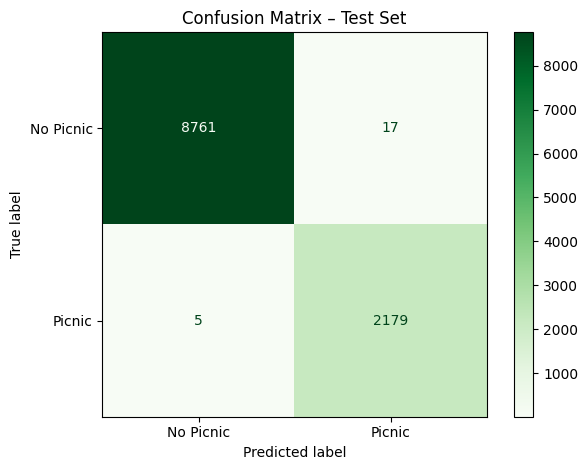

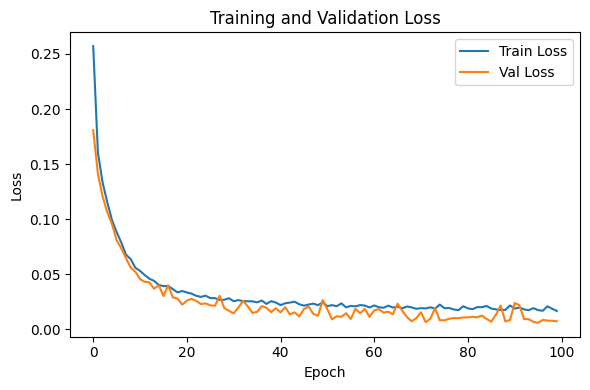

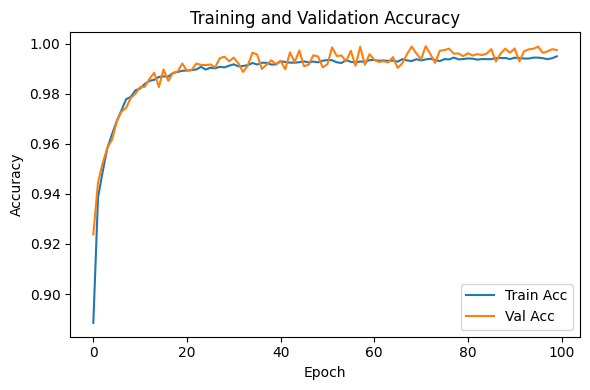

In [ ]:
# Neural Network ReLu
import pandas as pd
import numpy as np
import time
import matplotlib.pyplot as plt
import tensorflow as tf

from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, ConfusionMatrixDisplay

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input, Dense, Dropout
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import EarlyStopping

# -----------------------------
# Hyperparameters Neural Network
# -----------------------------
NN_PARAMS = {
    "layers": [32],        # Number of units per layer
    "activation": "relu",      # Activation function
    "dropout_rate": 0.5,       # Dropout between layers
    "learning_rate": 0.001,
    "batch_size": 16,
    "epochs": 100,
    "patience": 40
}


# Loading and formatting data
features = pd.read_csv("data/weather_prediction_dataset.csv")
labels   = pd.read_csv("data/weather_prediction_picnic_labels.csv")


feat_long = features.melt(id_vars=["DATE", "MONTH"], var_name="var", value_name="value")
feat_long[["city", "feature"]] = feat_long["var"].str.split("_", n=1, expand=True)
feat_wide = (
    feat_long
    .pivot_table(index=["DATE", "MONTH", "city"], columns="feature", values="value")
    .reset_index()
)


labels_long = labels.melt(id_vars=["DATE"], var_name="var", value_name="picnic_possible")
labels_long["city"] = labels_long["var"].str.replace("_picnic_weather", "", regex=False)
labels_long = labels_long[["DATE", "city", "picnic_possible"]]

data = feat_wide.merge(labels_long, on=["DATE", "city"])


# Split cities
roma_df  = data[data["city"] == "ROMA"]

cities   = non_roma["city"].unique()
np.random.seed(42)
shuffled = np.random.permutation(cities)

train_cities = shuffled[:11]
val_cities   = shuffled[11:14]
test_cities  = shuffled[14:17]

train_df = non_roma[non_roma["city"].isin(train_cities)].copy()
val_df   = non_roma[non_roma["city"].isin(val_cities)].copy()
test_df  = non_roma[non_roma["city"].isin(test_cities)].copy()

for df in (train_df, val_df, test_df):
    df["picnic_possible"] = df["picnic_possible"].fillna(False).astype(int)

print("Train cities:", train_cities)
print("Val   cities:", val_cities)
print("Test  cities:", test_cities)


drop_cols = ["DATE", "city", "picnic_possible"]

X_train = train_df.drop(columns=drop_cols)
y_train = train_df["picnic_possible"]

X_val   = val_df.drop(columns=drop_cols)
y_val   = val_df["picnic_possible"]

X_test  = test_df.drop(columns=drop_cols)
y_test  = test_df["picnic_possible"]

# Standardization of the features
scaler  = StandardScaler().fit(imputer.transform(X_train))

X_train_proc = scaler.transform(imputer.transform(X_train))
X_val_proc   = scaler.transform(imputer.transform(X_val))
X_test_proc  = scaler.transform(imputer.transform(X_test))


# Model definition
model = Sequential()
input_dim = X_train_proc.shape[1]

model.add(Input(shape=(input_dim,)))

# Hidden layers
for units in NN_PARAMS['layers']:
    model.add(Dense(units, activation=NN_PARAMS['activation']))
    model.add(Dropout(NN_PARAMS['dropout_rate']))

# Output layer
model.add(Dense(1, activation='sigmoid'))

optimizer = Adam(learning_rate=NN_PARAMS['learning_rate'])
model.compile(
    optimizer=optimizer,
    loss='binary_crossentropy',
    metrics=['accuracy', 'mae', 'mse']
)

# Early stopping
early_stop = EarlyStopping(
    monitor='val_loss',
    patience=NN_PARAMS['patience'],
    restore_best_weights=True
)


# Training with time measurement
start = time.perf_counter()
history = model.fit(
    X_train_proc, y_train,
    validation_data=(X_val_proc, y_val),
    epochs=NN_PARAMS['epochs'],
    batch_size=NN_PARAMS['batch_size'],
    callbacks=[early_stop],
    verbose=2
)
end = time.perf_counter()
print(f"⏱ Tempo di training Rete Neurale: {end - start:.6f} secondi")

# Accuracy
y_val_pred  = (model.predict(X_val_proc) > 0.5).astype(int).flatten()
y_test_pred = (model.predict(X_test_proc) > 0.5).astype(int).flatten()

print(f"Validation Accuracy: {accuracy_score(y_val, y_val_pred):.3f}")
print(f"Test Accuracy      : {accuracy_score(y_test, y_test_pred):.3f}")  # qui tolto il doppio ':'

# Confusion matrix
ConfusionMatrixDisplay.from_predictions(
    y_val, y_val_pred, display_labels=["No Picnic", "Picnic"], cmap="Blues"
)
plt.title("Confusion Matrix – Validation Set")
plt.tight_layout(); plt.show()

ConfusionMatrixDisplay.from_predictions(
    y_test, y_test_pred, display_labels=["No Picnic", "Picnic"], cmap="Greens"
)
plt.title("Confusion Matrix – Test Set")
plt.tight_layout(); plt.show()

# Learning curves
plt.figure(figsize=(6,4))
plt.plot(history.history['loss'],     label='Train Loss')
plt.plot(history.history['val_loss'], label='Val Loss')
plt.title('Training and Validation Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.tight_layout()
plt.show()

plt.figure(figsize=(6,4))
plt.plot(history.history['accuracy'],     label='Train Acc')
plt.plot(history.history['val_accuracy'], label='Val Acc')
plt.title('Training and Validation Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()
plt.tight_layout()
plt.show()


In [ ]:
# Accuracy and AUROC
from sklearn.metrics import accuracy_score, roc_auc_score


y_train_prob = model.predict(X_train_proc).flatten()
y_val_prob   = model.predict(X_val_proc).flatten()
y_test_prob  = model.predict(X_test_proc).flatten()

y_train_pred = (y_train_prob > 0.5).astype(int)
y_val_pred   = (y_val_prob   > 0.5).astype(int)
y_test_pred  = (y_test_prob  > 0.5).astype(int)

# Accuracy
acc_train = accuracy_score(y_train, y_train_pred)
acc_val   = accuracy_score(y_val,   y_val_pred)
acc_test  = accuracy_score(y_test,  y_test_pred)

# AUROC
auc_train = roc_auc_score(y_train, y_train_prob)
auc_val   = roc_auc_score(y_val,   y_val_prob)
auc_test  = roc_auc_score(y_test,  y_test_prob)

print("=== Accuracy ===")
print(f"Train: {acc_train:.3f}   |   Val: {acc_val:.3f}   |   Test: {acc_test:.3f}")
print("\n=== AUROC ===")
print(f"Train: {auc_train:.3f}   |   Val: {auc_val:.3f}   |   Test: {auc_test:.3f}")


1257/1257 ━━━━━━━━━━━━━━━━━━━━ 1s 1000us/step
343/343 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step
343/343 ━━━━━━━━━━━━━━━━━━━━ 0s 999us/step
=== Accuracy ===
Train: 0.999   |   Val: 0.999   |   Test: 0.998

=== AUROC ===
Train: 1.000   |   Val: 1.000   |   Test: 1.000


In [ ]:
# Classification Report
from sklearn.metrics import classification_report

print("=== Classification Report: TRAIN SET ===")
print(classification_report(y_train, y_train_pred, target_names=["No Picnic", "Picnic"]))

print("=== Classification Report: VAL SET ===")
print(classification_report(y_val, y_val_pred, target_names=["No Picnic", "Picnic"]))

print("=== Classification Report: TEST SET ===")
print(classification_report(y_test, y_test_pred, target_names=["No Picnic", "Picnic"]))


=== Classification Report: TRAIN SET ===
              precision    recall  f1-score   support

   No Picnic       1.00      1.00      1.00     30383
      Picnic       1.00      1.00      1.00      9811

    accuracy                           1.00     40194
   macro avg       1.00      1.00      1.00     40194
weighted avg       1.00      1.00      1.00     40194

=== Classification Report: VAL SET ===
              precision    recall  f1-score   support

   No Picnic       1.00      1.00      1.00      7621
      Picnic       1.00      1.00      1.00      3341

    accuracy                           1.00     10962
   macro avg       1.00      1.00      1.00     10962
weighted avg       1.00      1.00      1.00     10962

=== Classification Report: TEST SET ===
              precision    recall  f1-score   support

   No Picnic       1.00      1.00      1.00      8778
      Picnic       0.99      1.00      0.99      2184

    accuracy                           1.00     10962
   macro

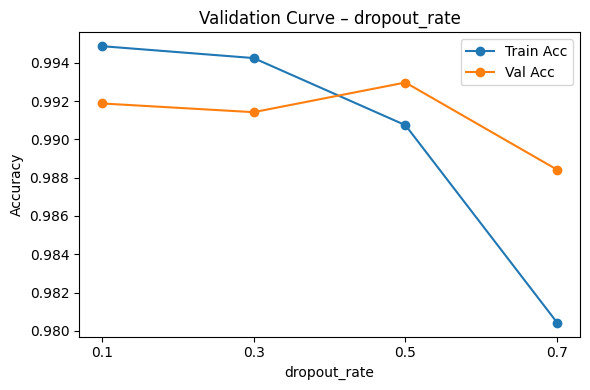

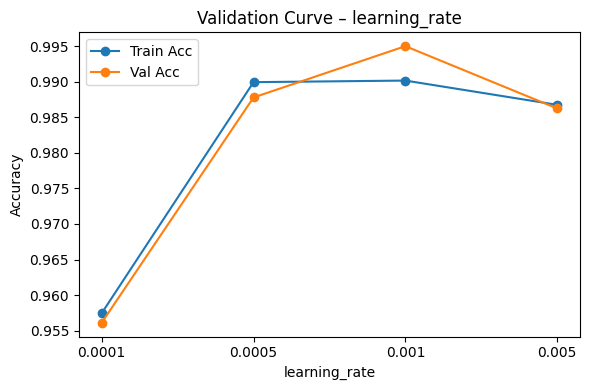

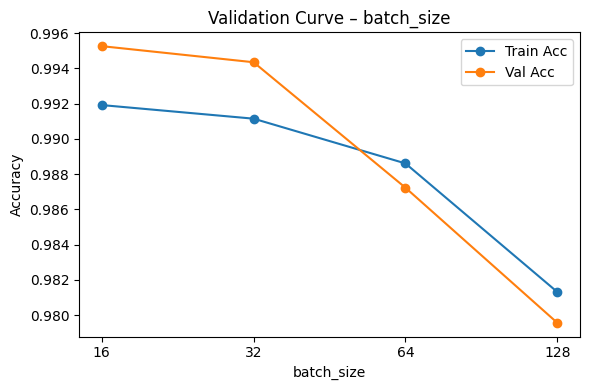

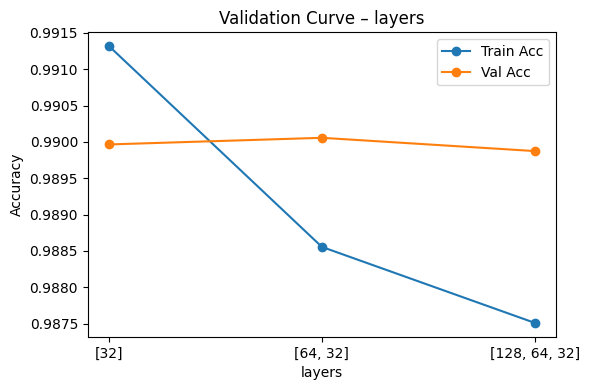

In [ ]:
# Validation curves
import numpy as np
import matplotlib.pyplot as plt
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input, Dense, Dropout
from tensorflow.keras.optimizers import Adam


def build_model(input_dim, params):
    model = Sequential()
    model.add(Input(shape=(input_dim,)))
    # hidden layers
    for units in params["layers"]:
        model.add(Dense(units, activation=params["activation"]))
        model.add(Dropout(params["dropout_rate"]))
    model.add(Dense(1, activation="sigmoid"))
    optimizer = Adam(learning_rate=params["learning_rate"])
    model.compile(
        optimizer=optimizer,
        loss="binary_crossentropy",
        metrics=["accuracy"]
    )
    return model

# Testing values
param_grid = {
    "dropout_rate":    [0.1, 0.3, 0.5, 0.7],
    "learning_rate":   [1e-4, 5e-4, 1e-3, 5e-3],
    "batch_size":      [16, 32, 64, 128],
    "layers":          [ [32], [64,32], [128,64,32] ],
}


test_epochs = 30



input_dim = X_train_proc.shape[1]

for param_name, values in param_grid.items():
    train_scores = []
    val_scores   = []
    for v in values:

        p = NN_PARAMS.copy()
        p.update({param_name: v})

        model = build_model(input_dim, p)
        history = model.fit(
            X_train_proc, y_train,
            validation_data=(X_val_proc, y_val),
            epochs=test_epochs,
            batch_size=p["batch_size"],
            verbose=0
        )
        train_scores.append(history.history["accuracy"][-1])
        val_scores.append(history.history["val_accuracy"][-1])


    plt.figure(figsize=(6,4))
    label_x = [str(x) for x in values]
    plt.plot(label_x, train_scores, marker="o", label="Train Acc")
    plt.plot(label_x, val_scores,   marker="o", label="Val Acc")
    plt.xlabel(param_name)
    plt.ylabel("Accuracy")
    plt.title(f"Validation Curve – {param_name}")
    plt.legend()
    plt.tight_layout()
    plt.show()


#Neural Network Tanh

Train cities: ['BASEL' 'BUDAPEST' 'HEATHROW' 'STOCKHOLM' 'MUENCHEN' 'SONNBLICK'
 'MAASTRICHT' 'PERPIGNAN' 'DEBILT' 'MALMO' 'TOURS']
Val   cities: ['DUSSELDORF' 'LJUBLJANA' 'MONTELIMAR']
Test  cities: ['OSLO' 'DRESDEN' 'KASSEL']
Epoch 1/100
629/629 - 3s - 5ms/step - accuracy: 0.7838 - loss: 0.4650 - mae: 0.3214 - mse: 0.1507 - val_accuracy: 0.8578 - val_loss: 0.3523 - val_mae: 0.2401 - val_mse: 0.1072
Epoch 2/100
629/629 - 2s - 4ms/step - accuracy: 0.8790 - loss: 0.3006 - mae: 0.2100 - mse: 0.0903 - val_accuracy: 0.8949 - val_loss: 0.2638 - val_mae: 0.1754 - val_mse: 0.0787
Epoch 3/100
629/629 - 3s - 4ms/step - accuracy: 0.9002 - loss: 0.2385 - mae: 0.1617 - mse: 0.0721 - val_accuracy: 0.9035 - val_loss: 0.2329 - val_mae: 0.1481 - val_mse: 0.0702
Epoch 4/100
629/629 - 2s - 3ms/step - accuracy: 0.9096 - loss: 0.2135 - mae: 0.1392 - mse: 0.0649 - val_accuracy: 0.9091 - val_loss: 0.2192 - val_mae: 0.1344 - val_mse: 0.0659
Epoch 5/100
629/629 - 3s - 5ms/step - accuracy: 0.9161 - loss: 0.198

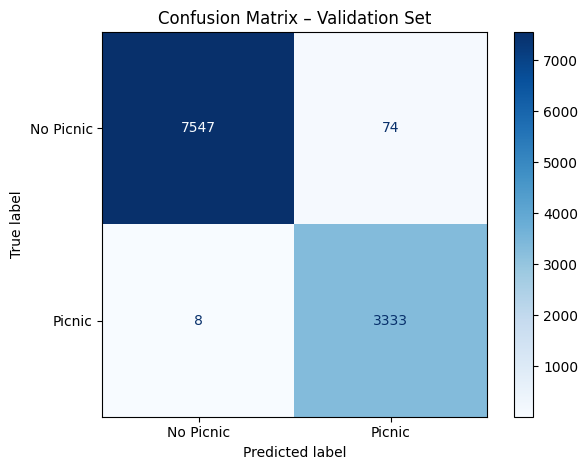

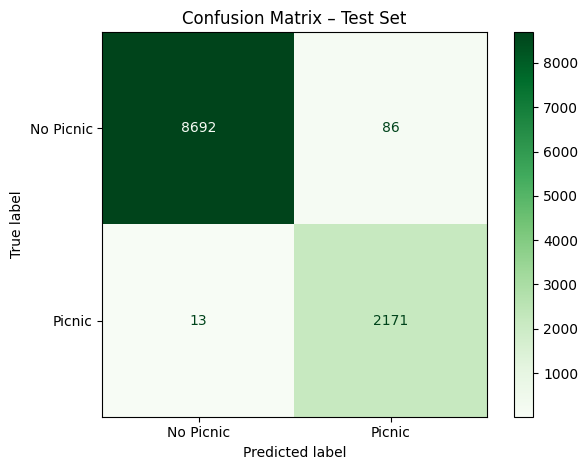

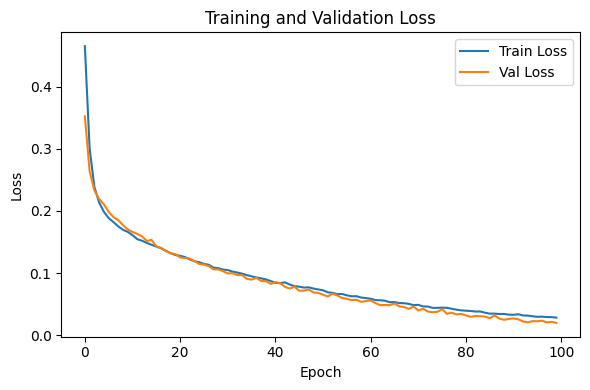

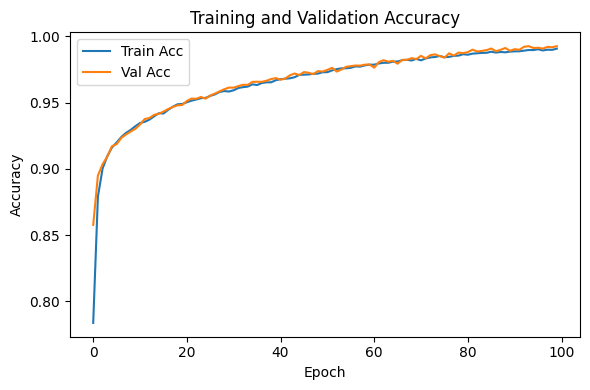

In [ ]:
# Neural Network tanh
import pandas as pd
import numpy as np
import time
import matplotlib.pyplot as plt
import tensorflow as tf

from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, ConfusionMatrixDisplay

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input, Dense, Dropout
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import EarlyStopping

# -----------------------------
# Hyperparameters Neural Network
# -----------------------------
NN_PARAMS = {
    "layers": [64, 32],        # Number of units per layer
    "activation": "tanh",      # Activation function
    "dropout_rate": 0.3,       # Dropout between layers
    "learning_rate": 0.0001,
    "batch_size": 64,
    "epochs": 100,
    "patience": 40
}

# Loading and formatting data
features = pd.read_csv("data/weather_prediction_dataset.csv")
labels   = pd.read_csv("data/weather_prediction_picnic_labels.csv")


feat_long = features.melt(id_vars=["DATE", "MONTH"], var_name="var", value_name="value")
feat_long[["city", "feature"]] = feat_long["var"].str.split("_", n=1, expand=True)
feat_wide = (
    feat_long
    .pivot_table(index=["DATE", "MONTH", "city"], columns="feature", values="value")
    .reset_index()
)


labels_long = labels.melt(id_vars=["DATE"], var_name="var", value_name="picnic_possible")
labels_long["city"] = labels_long["var"].str.replace("_picnic_weather", "", regex=False)
labels_long = labels_long[["DATE", "city", "picnic_possible"]]

data = feat_wide.merge(labels_long, on=["DATE", "city"])


# Split cities
non_roma = data[data["city"] != "ROMA"]
roma_df  = data[data["city"] == "ROMA"]

cities   = non_roma["city"].unique()
np.random.seed(42)
shuffled = np.random.permutation(cities)

train_cities = shuffled[:11]
val_cities   = shuffled[11:14]
test_cities  = shuffled[14:17]

train_df = non_roma[non_roma["city"].isin(train_cities)].copy()
val_df   = non_roma[non_roma["city"].isin(val_cities)].copy()
test_df  = non_roma[non_roma["city"].isin(test_cities)].copy()

for df in (train_df, val_df, test_df):
    df["picnic_possible"] = df["picnic_possible"].fillna(False).astype(int)

print("Train cities:", train_cities)
print("Val   cities:", val_cities)
print("Test  cities:", test_cities)


drop_cols = ["DATE", "city", "picnic_possible"]

X_train = train_df.drop(columns=drop_cols)
y_train = train_df["picnic_possible"]

X_val   = val_df.drop(columns=drop_cols)
y_val   = val_df["picnic_possible"]

X_test  = test_df.drop(columns=drop_cols)
y_test  = test_df["picnic_possible"]

# Standardization of the features
scaler  = StandardScaler().fit(imputer.transform(X_train))

X_train_proc = scaler.transform(imputer.transform(X_train))
X_val_proc   = scaler.transform(imputer.transform(X_val))
X_test_proc  = scaler.transform(imputer.transform(X_test))

# Model definition
model = Sequential()
input_dim = X_train_proc.shape[1]

model.add(Input(shape=(input_dim,)))

# Hidden layers
for units in NN_PARAMS['layers']:
    model.add(Dense(units, activation=NN_PARAMS['activation']))
    model.add(Dropout(NN_PARAMS['dropout_rate']))

# Output layer
model.add(Dense(1, activation='sigmoid'))

optimizer = Adam(learning_rate=NN_PARAMS['learning_rate'])
model.compile(
    optimizer=optimizer,
    loss='binary_crossentropy',
    metrics=['accuracy', 'mae', 'mse']
)

# Early stopping
early_stop = EarlyStopping(
    monitor='val_loss',
    patience=NN_PARAMS['patience'],
    restore_best_weights=True
)

# Training with time measurement
start = time.perf_counter()
history = model.fit(
    X_train_proc, y_train,
    validation_data=(X_val_proc, y_val),
    epochs=NN_PARAMS['epochs'],
    batch_size=NN_PARAMS['batch_size'],
    callbacks=[early_stop],
    verbose=2
)
end = time.perf_counter()
print(f"⏱ Tempo di training Rete Neurale: {end - start:.6f} secondi")

# Accuracy
y_val_pred  = (model.predict(X_val_proc) > 0.5).astype(int).flatten()
y_test_pred = (model.predict(X_test_proc) > 0.5).astype(int).flatten()

print(f"Validation Accuracy: {accuracy_score(y_val, y_val_pred):.3f}")
print(f"Test Accuracy      : {accuracy_score(y_test, y_test_pred):.3f}")

# Confusion matrix
ConfusionMatrixDisplay.from_predictions(
    y_val, y_val_pred, display_labels=["No Picnic", "Picnic"], cmap="Blues"
)
plt.title("Confusion Matrix – Validation Set")
plt.tight_layout(); plt.show()

ConfusionMatrixDisplay.from_predictions(
    y_test, y_test_pred, display_labels=["No Picnic", "Picnic"], cmap="Greens"
)
plt.title("Confusion Matrix – Test Set")
plt.tight_layout(); plt.show()

# Learning curves
plt.figure(figsize=(6,4))
plt.plot(history.history['loss'],     label='Train Loss')
plt.plot(history.history['val_loss'], label='Val Loss')
plt.title('Training and Validation Loss')
plt.xlabel('Epoch'); plt.ylabel('Loss')
plt.legend(); plt.tight_layout(); plt.show()

plt.figure(figsize=(6,4))
plt.plot(history.history['accuracy'],     label='Train Acc')
plt.plot(history.history['val_accuracy'], label='Val Acc')
plt.title('Training and Validation Accuracy')
plt.xlabel('Epoch'); plt.ylabel('Accuracy')
plt.legend(); plt.tight_layout(); plt.show()




In [ ]:
# Accuracy and AUROC
from sklearn.metrics import accuracy_score, roc_auc_score


y_train_prob = model.predict(X_train_proc).flatten()
y_val_prob   = model.predict(X_val_proc).flatten()
y_test_prob  = model.predict(X_test_proc).flatten()

y_train_pred = (y_train_prob > 0.5).astype(int)
y_val_pred   = (y_val_prob   > 0.5).astype(int)
y_test_pred  = (y_test_prob  > 0.5).astype(int)

# Accuracy
acc_train = accuracy_score(y_train, y_train_pred)
acc_val   = accuracy_score(y_val,   y_val_pred)
acc_test  = accuracy_score(y_test,  y_test_pred)

# AUROC
auc_train = roc_auc_score(y_train, y_train_prob)
auc_val   = roc_auc_score(y_val,   y_val_prob)
auc_test  = roc_auc_score(y_test,  y_test_prob)

print("=== Accuracy ===")
print(f"Train: {acc_train:.3f}   |   Val: {acc_val:.3f}   |   Test: {acc_test:.3f}")
print("\n=== AUROC ===")
print(f"Train: {auc_train:.3f}   |   Val: {auc_val:.3f}   |   Test: {auc_test:.3f}")


1257/1257 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step
343/343 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step
343/343 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step
=== Accuracy ===
Train: 0.995   |   Val: 0.993   |   Test: 0.991

=== AUROC ===
Train: 1.000   |   Val: 1.000   |   Test: 1.000


In [ ]:
# Classification Report
from sklearn.metrics import classification_report

print("=== Classification Report: TRAIN SET ===")
print(classification_report(y_train, y_train_pred, target_names=["No Picnic", "Picnic"]))

print("=== Classification Report: VAL SET ===")
print(classification_report(y_val, y_val_pred, target_names=["No Picnic", "Picnic"]))

print("=== Classification Report: TEST SET ===")
print(classification_report(y_test, y_test_pred, target_names=["No Picnic", "Picnic"]))


=== Classification Report: TRAIN SET ===
              precision    recall  f1-score   support

   No Picnic       1.00      0.99      1.00     30383
      Picnic       0.98      1.00      0.99      9811

    accuracy                           0.99     40194
   macro avg       0.99      1.00      0.99     40194
weighted avg       0.99      0.99      0.99     40194

=== Classification Report: VAL SET ===
              precision    recall  f1-score   support

   No Picnic       1.00      0.99      0.99      7621
      Picnic       0.98      1.00      0.99      3341

    accuracy                           0.99     10962
   macro avg       0.99      0.99      0.99     10962
weighted avg       0.99      0.99      0.99     10962

=== Classification Report: TEST SET ===
              precision    recall  f1-score   support

   No Picnic       1.00      0.99      0.99      8778
      Picnic       0.96      0.99      0.98      2184

    accuracy                           0.99     10962
   macro

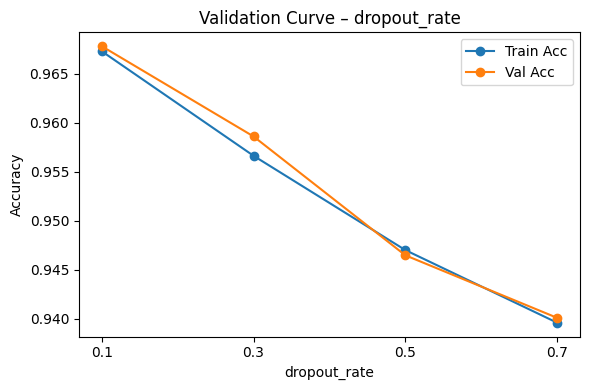

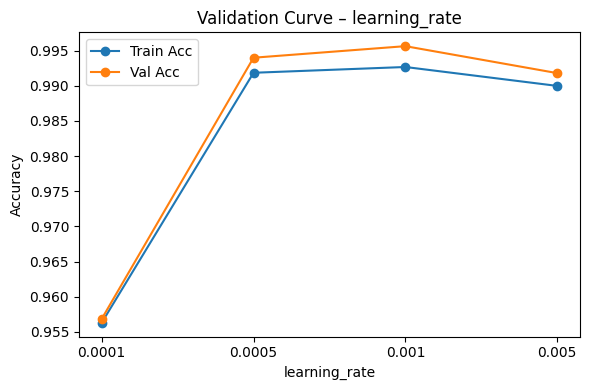

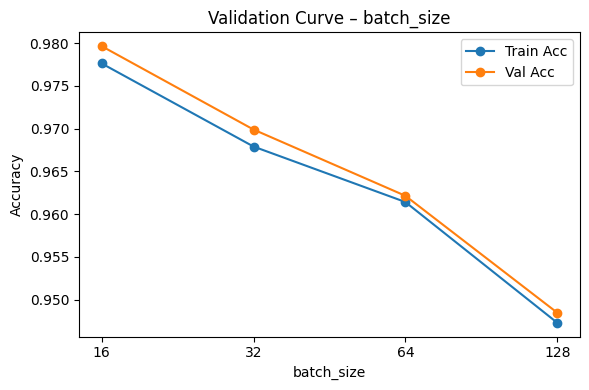

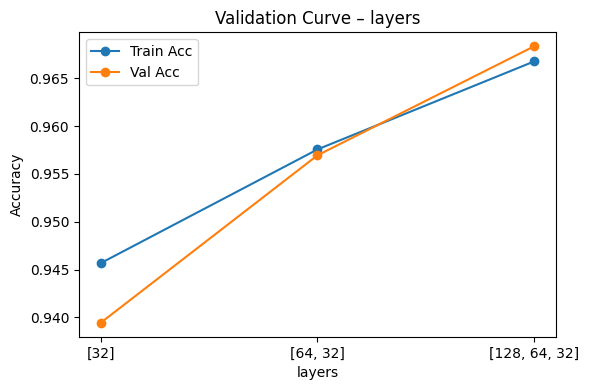

In [ ]:
# Validation curves
import numpy as np
import matplotlib.pyplot as plt
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input, Dense, Dropout
from tensorflow.keras.optimizers import Adam


def build_model(input_dim, params):
    model = Sequential()
    model.add(Input(shape=(input_dim,)))
    # hidden layers
    for units in params["layers"]:
        model.add(Dense(units, activation=params["activation"]))
        model.add(Dropout(params["dropout_rate"]))
    model.add(Dense(1, activation="sigmoid"))
    optimizer = Adam(learning_rate=params["learning_rate"])
    model.compile(
        optimizer=optimizer,
        loss="binary_crossentropy",
        metrics=["accuracy"]
    )
    return model

# definition values
param_grid = {
    "dropout_rate":    [0.1, 0.3, 0.5, 0.7],
    "learning_rate":   [1e-4, 5e-4, 1e-3, 5e-3],
    "batch_size":      [16, 32, 64, 128],
    "layers":          [ [32], [64,32], [128,64,32] ],
}


test_epochs = 30



input_dim = X_train_proc.shape[1]

for param_name, values in param_grid.items():
    train_scores = []
    val_scores   = []
    for v in values:

        p = NN_PARAMS.copy()
        p.update({param_name: v})

        model = build_model(input_dim, p)
        history = model.fit(
            X_train_proc, y_train,
            validation_data=(X_val_proc, y_val),
            epochs=test_epochs,
            batch_size=p["batch_size"],
            verbose=0
        )
        train_scores.append(history.history["accuracy"][-1])
        val_scores.append(history.history["val_accuracy"][-1])


    plt.figure(figsize=(6,4))
    label_x = [str(x) for x in values]
    plt.plot(label_x, train_scores, marker="o", label="Train Acc")
    plt.plot(label_x, val_scores,   marker="o", label="Val Acc")
    plt.xlabel(param_name)
    plt.ylabel("Accuracy")
    plt.title(f"Validation Curve – {param_name}")
    plt.legend()
    plt.tight_layout()
    plt.show()
